Dataset shape: (308021, 24)
Number of samples: 308021
Number of features: 23
Target: activity
Features: ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W']

Data types:
A           float64
B           float64
C           float64
D           float64
E           float64
F           float64
G           float64
H           float64
I           float64
J           float64
K           float64
L           float64
M           float64
N           float64
O           float64
P           float64
Q           float64
R           float64
S           float64
T           float64
U           float64
V           float64
W           float64
activity      int64
dtype: object

Non-numeric features: None

Missing values:
A           0
B           0
C           0
D           0
E           0
F           0
G           0
H           0
I           0
J           0
K           0
L           0
M           0
N           0
O           0
P           0
Q   

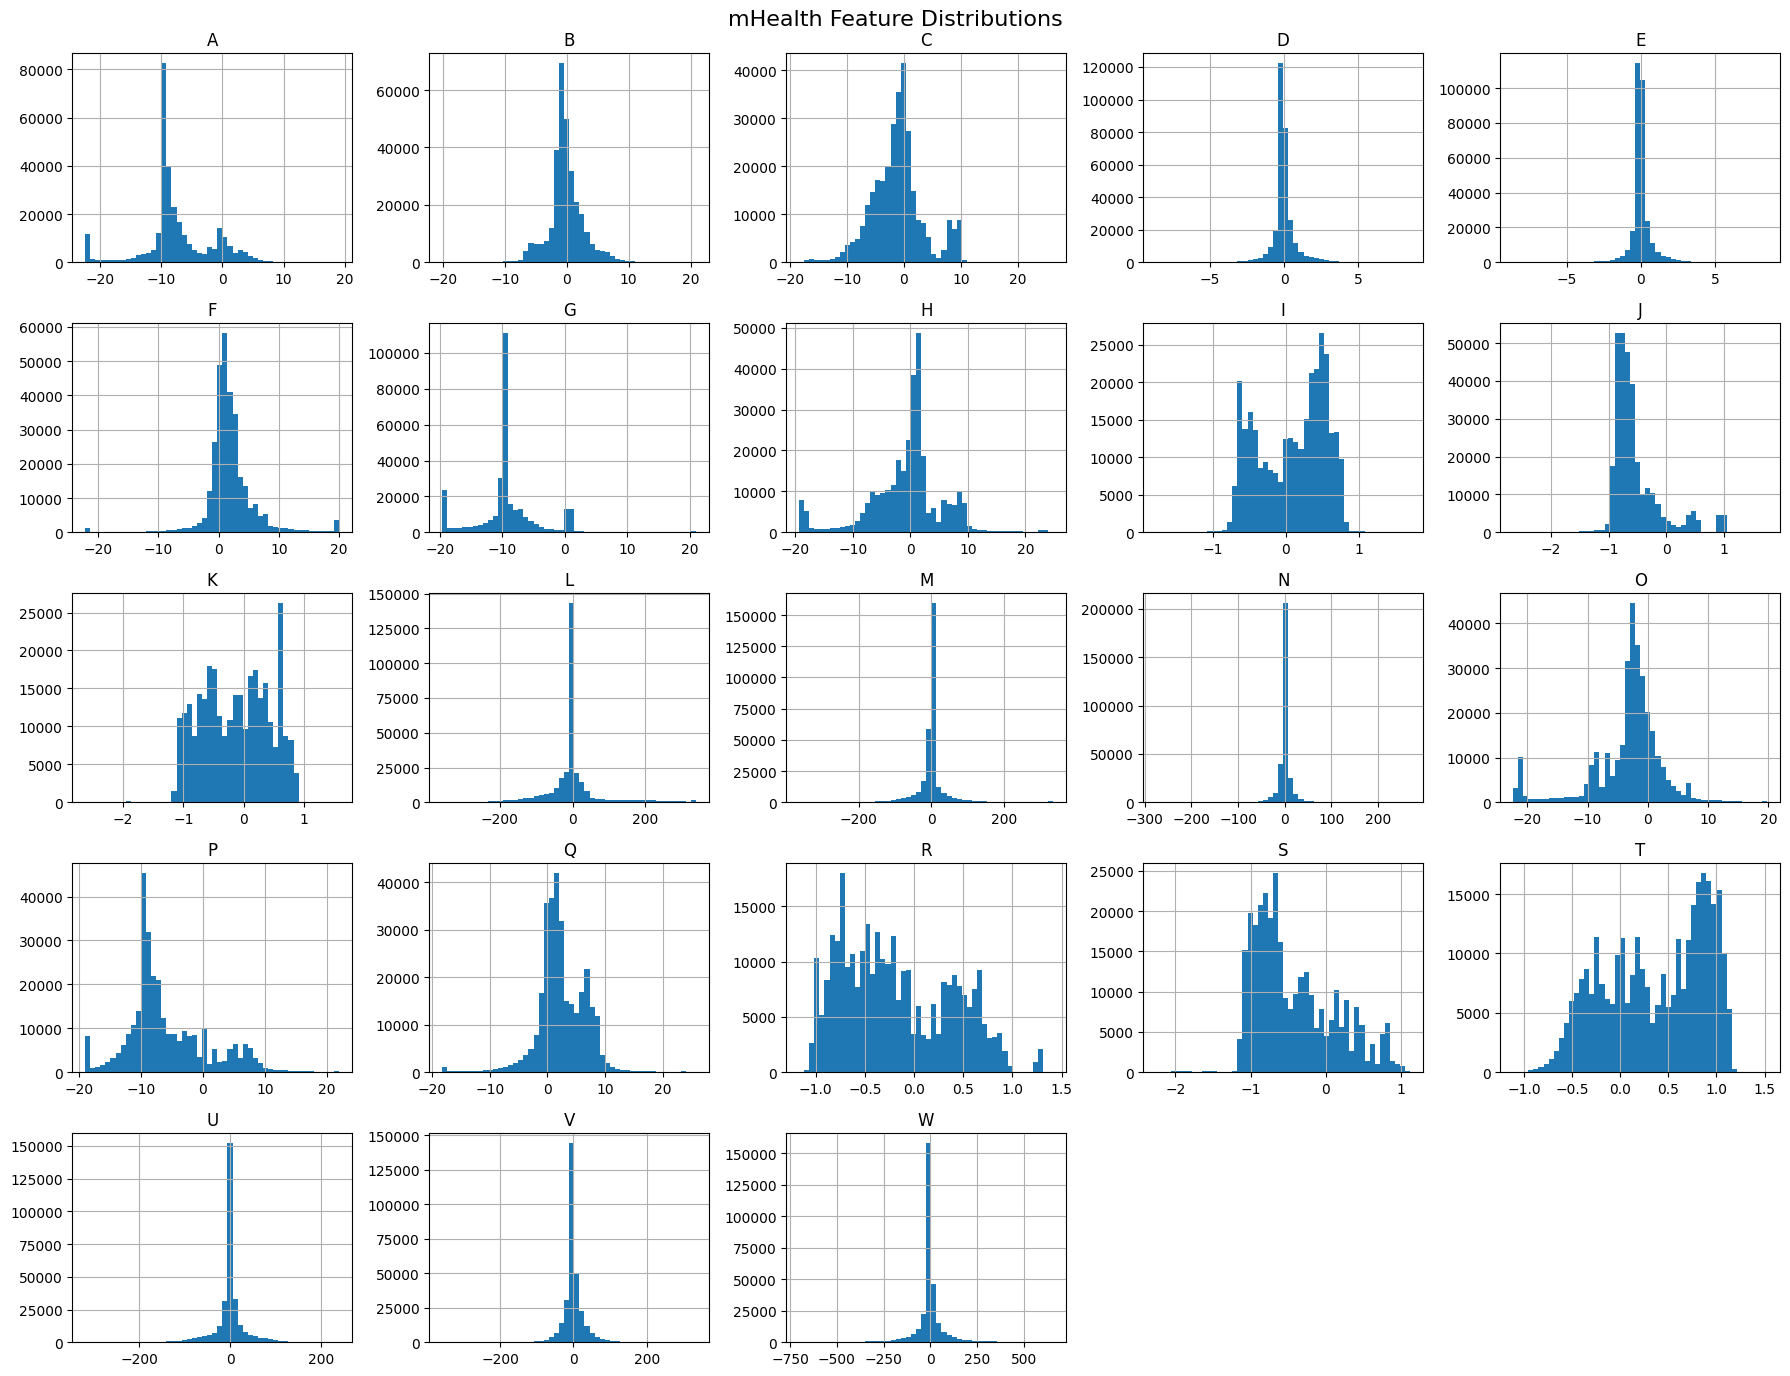

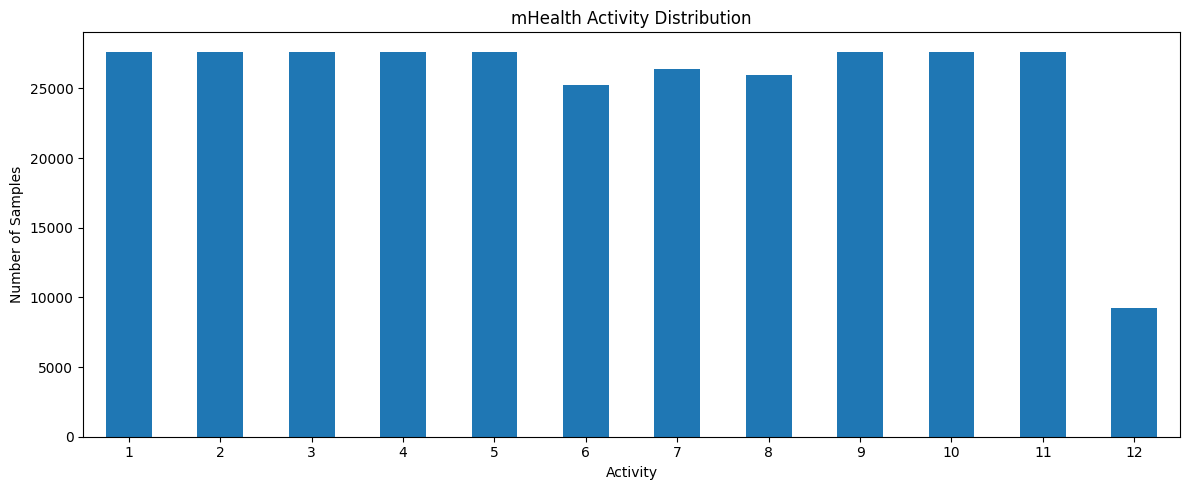

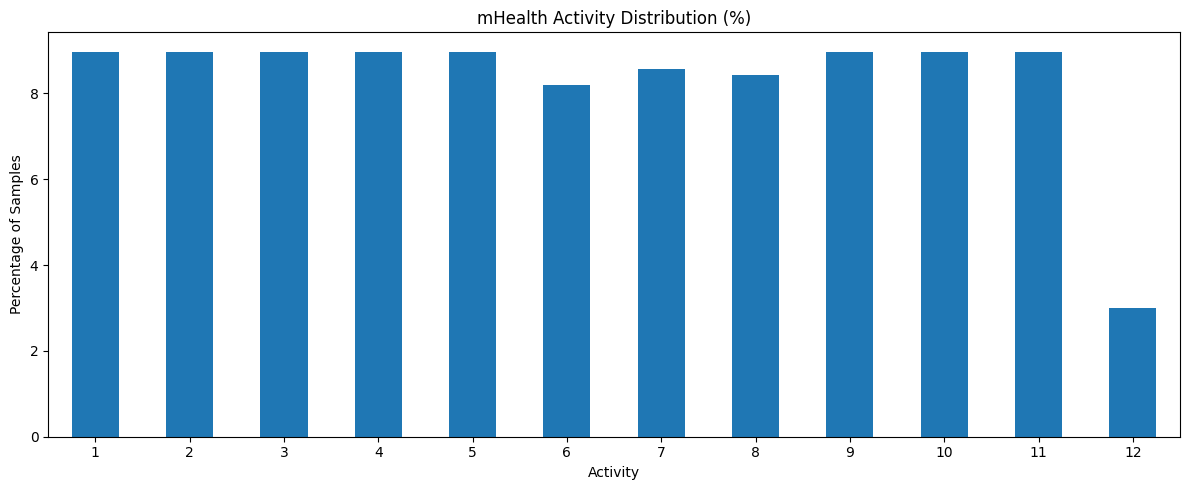

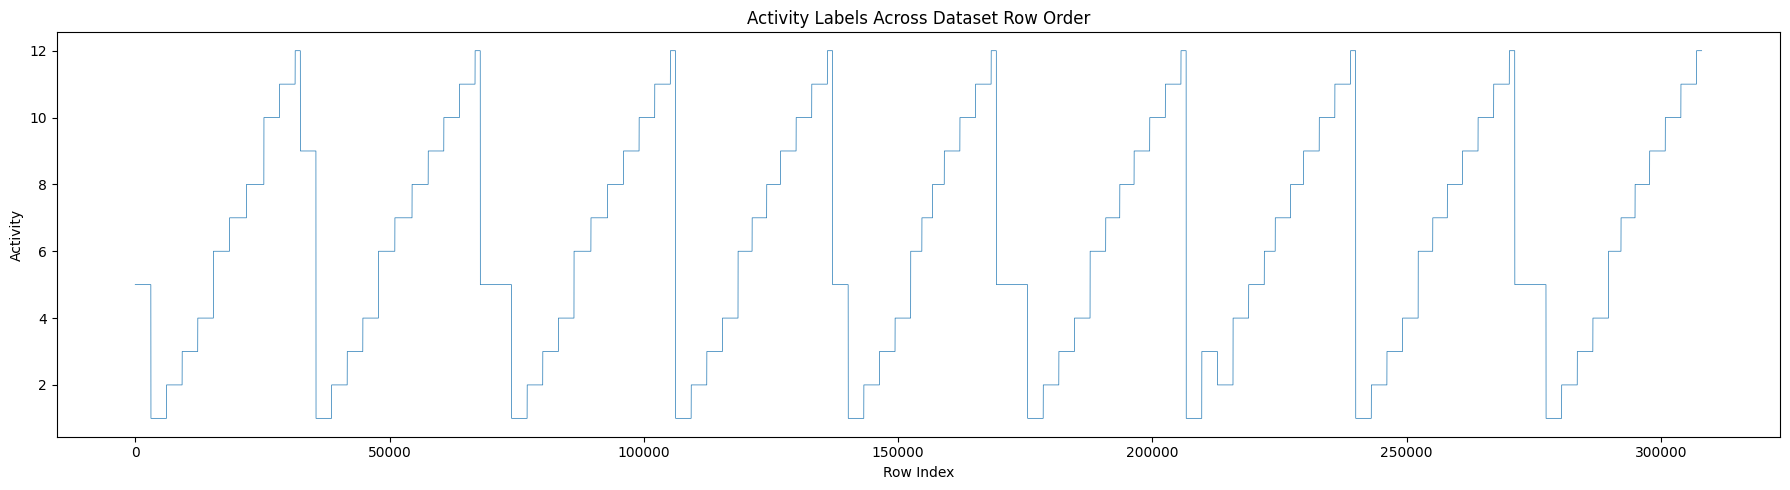


Feature ranges:
Feature   Minimum  Maximum     Range       Std
      A  -22.4380  19.0940   41.5320  5.688833
      B  -20.1880  20.9270   41.1150  2.894578
      C  -18.4010  26.1960   44.5970  4.575691
      D   -8.6196   8.5065   17.1261  0.860955
      E   -8.6196   8.5191   17.1387  0.831343
      F  -22.1460  20.0240   42.1700  4.123394
      G  -19.6190  21.0800   40.6990  5.183053
      H  -19.3650  24.8430   44.2080  6.476754
      I   -1.7792   1.7106    3.4898  0.458489
      J   -2.6604   1.7523    4.4127  0.432555
      K   -2.6267   1.5815    4.2082  0.562728
      L -357.5600 339.2200  696.7800 77.783431
      M -364.4400 336.2400  700.6800 46.505158
      N -275.8400 269.3000  545.1400 15.202448
      O  -22.3450  19.8010   42.1460  5.939879
      P  -18.9720  21.9650   40.9370  6.607413
      Q  -18.2380  25.7410   43.9790  4.212971
      R   -1.1706   1.4157    2.5863  0.554559
      S   -2.2567   1.1211    3.3778  0.537352
      T   -1.1142   1.5280    2.6422  0.523

In [2]:
#Data Analyssis 

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path


# Dataset Loading here--

DATA_PATH = "/kaggle/input/datasets/pratyaydhar/mhealth/mHealth.csv"

TARGET = "activity"

df = pd.read_csv(DATA_PATH)

FEATURES = [
    column for column in df.columns
    if column != TARGET
]

print("Dataset shape:", df.shape)
print("Number of samples:", len(df))
print("Number of features:", len(FEATURES))
print("Target:", TARGET)
print("Features:", FEATURES)


# Data types

print("\nData types:")
print(df.dtypes)

non_numeric_features = (
    df[FEATURES]
    .select_dtypes(exclude=[np.number])
    .columns
    .tolist()
)

if non_numeric_features:
    print("\nNon-numeric features:", non_numeric_features)
else:
    print("\nNon-numeric features: None")


# Missing values

missing = df.isnull().sum()
total_missing = missing.sum()

print("\nMissing values:")
print(missing)
print("Total missing values:", total_missing)


# Duplicate rows

duplicate_count = df.duplicated().sum()

print("\nDuplicate rows:", duplicate_count)


# Activity labels

activities = sorted(df[TARGET].unique())

print("\nNumber of activities:", len(activities))
print("Activity labels:", activities)


# Class distribution

class_counts = (
    df[TARGET]
    .value_counts()
    .sort_index()
)

class_percentage = (
    df[TARGET]
    .value_counts(normalize=True)
    .sort_index()
    * 100
)

distribution = pd.DataFrame({
    "Activity": class_counts.index,
    "Samples": class_counts.values,
    "Percentage": class_percentage.values
})

print("\nClass distribution:")
print(distribution.to_string(index=False))


# Class imbalance

largest_class = class_counts.max()
smallest_class = class_counts.min()

largest_activity = class_counts.idxmax()
smallest_activity = class_counts.idxmin()

imbalance_ratio = largest_class / smallest_class

print("\nClass imbalance:")
print(
    f"Largest class : Activity {largest_activity} "
    f"({largest_class:,} samples)"
)
print(
    f"Smallest class: Activity {smallest_activity} "
    f"({smallest_class:,} samples)"
)
print(f"Imbalance ratio: {imbalance_ratio:.2f}:1")


# Feature statistics

feature_statistics = df[FEATURES].describe().T

print("\nFeature statistics:")
print(
    feature_statistics[
        [
            "count",
            "mean",
            "std",
            "min",
            "25%",
            "50%",
            "75%",
            "max"
        ]
    ].to_string()
)


# Constant features

unique_counts = df[FEATURES].nunique()

constant_features = unique_counts[
    unique_counts <= 1
]

print("\nConstant features:")

if constant_features.empty:
    print("None")
else:
    print(constant_features)


# Near-constant features

near_constant_features = []

for feature in FEATURES:
    value_frequency = (
        df[feature]
        .value_counts(normalize=True)
    )

    highest_frequency = value_frequency.iloc[0]

    if highest_frequency >= 0.99:
        near_constant_features.append(
            (
                feature,
                highest_frequency * 100
            )
        )

print("\nNear-constant features:")

if near_constant_features:
    for feature, percentage in near_constant_features:
        print(f"{feature}: {percentage:.2f}%")
else:
    print("None")


# Temporal activity order

activity_array = df[TARGET].to_numpy()

activity_changes = np.sum(
    activity_array[1:] != activity_array[:-1]
)

total_transitions = len(activity_array) - 1

if total_transitions > 0:
    change_percentage = (
        activity_changes /
        total_transitions
    ) * 100
else:
    change_percentage = 0

print("\nTemporal activity order:")
print("Total row-to-row transitions:", total_transitions)
print("Activity-label changes:", activity_changes)
print(
    f"Transitions with activity changes: "
    f"{change_percentage:.4f}%"
)


# Activity transitions

transition_table = pd.crosstab(
    df[TARGET].shift(1),
    df[TARGET],
    dropna=True
)

print("\nActivity transition matrix:")
print(transition_table)


# Feature correlation

correlation_matrix = df[FEATURES].corr()

print("\nFeature correlation matrix:")
print(correlation_matrix.round(3).to_string())


high_correlation_pairs = []

for i in range(len(FEATURES)):
    for j in range(i + 1, len(FEATURES)):

        feature_1 = FEATURES[i]
        feature_2 = FEATURES[j]

        correlation = correlation_matrix.loc[
            feature_1,
            feature_2
        ]

        if abs(correlation) >= 0.90:
            high_correlation_pairs.append(
                (
                    feature_1,
                    feature_2,
                    correlation
                )
            )

print(
    "\nHighly correlated feature pairs "
    "(absolute correlation >= 0.90):"
)

if high_correlation_pairs:
    for feature_1, feature_2, correlation in high_correlation_pairs:
        print(
            f"{feature_1} <-> {feature_2}: "
            f"{correlation:.3f}"
        )
else:
    print("None")


# Feature distributions

df[FEATURES].hist(
    figsize=(18, 14),
    bins=50
)

plt.suptitle(
    "mHealth Feature Distributions",
    fontsize=16
)

plt.tight_layout()
plt.show()


# Activity distribution

plt.figure(figsize=(12, 5))

class_counts.plot(kind="bar")

plt.title("mHealth Activity Distribution")
plt.xlabel("Activity")
plt.ylabel("Number of Samples")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()


# Activity percentage distribution

plt.figure(figsize=(12, 5))

class_percentage.plot(kind="bar")

plt.title("mHealth Activity Distribution (%)")
plt.xlabel("Activity")
plt.ylabel("Percentage of Samples")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()


# Temporal activity sequence

plt.figure(figsize=(18, 5))

plt.plot(
    df[TARGET].values,
    linewidth=0.5
)

plt.title("Activity Labels Across Dataset Row Order")
plt.xlabel("Row Index")
plt.ylabel("Activity")

plt.tight_layout()
plt.show()


# Feature range analysis

feature_ranges = pd.DataFrame({
    "Feature": FEATURES,
    "Minimum": [
        df[feature].min()
        for feature in FEATURES
    ],
    "Maximum": [
        df[feature].max()
        for feature in FEATURES
    ],
    "Range": [
        df[feature].max() - df[feature].min()
        for feature in FEATURES
    ],
    "Std": [
        df[feature].std()
        for feature in FEATURES
    ]
})

print("\nFeature ranges:")
print(
    feature_ranges.to_string(index=False)
)


# Dataset summary

print("\nDataset summary")
print("----------------")

print("Dataset shape:", df.shape)
print("Total samples:", len(df))
print("Total features:", len(FEATURES))
print("Target:", TARGET)
print("Number of activities:", len(activities))
print("Missing values:", total_missing)
print("Duplicate rows:", duplicate_count)
print("Constant features:", len(constant_features))
print(
    "Highly correlated feature pairs:",
    len(high_correlation_pairs)
)


# Preprocessing decisions

print("\nPreprocessing decisions")
print("-----------------------")

print("Target column: activity")
print("Sensor features: all columns except activity")
print("Subject IDs are not available in the CSV")
print("No subject or session reconstruction will be performed")
print("Sliding windows will be generated in the next stage")
print("Windows should contain a single activity label")
print("Normalization will be fitted using training data only")
print("Class imbalance will be considered during model training")

# mHealth Dataset Preprocessing 

This code implements a complete preprocessing pipeline for the **mHealth Human Activity Recognition (HAR) dataset**. It converts the raw continuous sensor data into clean, normalized, fixed-length temporal windows suitable for machine-learning and deep-learning models.

The dataset contains **23 sensor features (A–W)** and **12 activity classes**. The pipeline first loads the CSV file and performs extensive validation, checking for missing features, incorrect data types, missing values, unexpected columns, duplicate rows, and the expected number of activities.

A key feature of this preprocessing approach is **activity-run-based splitting**. Instead of randomly splitting individual sensor samples, the code identifies continuous runs where the activity label remains unchanged. Complete activity runs are then distributed into **70% training, 15% validation, and 15% testing**, separately for each activity. This prevents the same continuous activity run from appearing in multiple splits and significantly reduces the possibility of temporal/run-level data leakage. The code also verifies that there is no overlap between the three splits and that every run has been assigned exactly once.

After splitting, the code performs **training-only normalization** using `StandardScaler`. The scaler is fitted exclusively on the training data and then applied to the training, validation, and test sets. This prevents information from the validation or test data from influencing the preprocessing statistics.

The normalized data is then converted into temporal sequences using **sliding windows of 128 samples with 64 samples of overlap**. Therefore, the step size is 64 samples and each final input window has the shape:

`128 × 23`

Windows are generated **separately inside each activity run**, meaning a window can never cross from one activity into another. Every generated window is checked to ensure that all 128 samples belong to the same activity. Runs shorter than 128 samples are skipped and recorded in the window statistics.

The pipeline performs several additional validation steps, including checking the final tensor shapes, verifying window labels, ensuring all 12 activities are present in every split, and checking for NaN or infinite values.

To handle possible class imbalance, **balanced class weights are calculated using training windows only**. Both the original activity labels (`1–12`) and zero-based model class indices (`0–11`) are recorded for compatibility with machine-learning models.

Finally, the processed datasets are saved as `train.npz`, `validation.npz`, and `test.npz`. The fitted scaler, class weights, activity-run assignments, preprocessing configuration, window statistics, activity information, and dataset summary are also saved to ensure **reproducibility, transparency, and easy reuse during model training and inference**.

### Overall Pipeline

**Raw mHealth data → Dataset validation → Activity-run detection → Run-level stratified split → Train-only normalization → 128-sample sliding windows → Activity-boundary validation → Class-weight calculation → Data-quality checks → Save processed datasets and preprocessing metadata**

### Important Note

This preprocessing method provides strong protection against **run-level temporal leakage**, but the dataset does not provide usable subject/session information. Therefore, the resulting evaluation **cannot be claimed as subject-independent evaluation**. It should be described as **activity-run-level separated evaluation**.


# Data

In [3]:
# mHealth Dataset 
# Run-level splitting, train-only normalization and run-wise windowing

import os
import json
import joblib  #Used to save the trained StandardScaler.

import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight


DATA_PATH = "/kaggle/input/datasets/pratyaydhar/mhealth/mHealth.csv"
OUTPUT_DIR = "mHealth_preprocessed"

TARGET = "activity"

FEATURES = [
    "A", "B", "C", "D", "E", "F",
    "G", "H", "I", "J", "K", "L",
    "M", "N", "O", "P", "Q", "R",
    "S", "T", "U", "V", "W"
] #23 feature/columns info

#THe main train-test-val split is here below

TRAIN_RATIO = 0.70
VAL_RATIO = 0.15
TEST_RATIO = 0.15

RANDOM_SEED = 43

WINDOW_SIZE = 128
OVERLAP = 64
STEP = WINDOW_SIZE - OVERLAP


# Configuration checks

if not np.isclose(
    TRAIN_RATIO + VAL_RATIO + TEST_RATIO,
    1.0
):
    raise ValueError(
        "Train, validation and test ratios must sum to 1."
    )

if WINDOW_SIZE <= 0:
    raise ValueError(
        "WINDOW_SIZE must be greater than 0."
    )

if not 0 <= OVERLAP < WINDOW_SIZE:
    raise ValueError(
        "OVERLAP must be >= 0 and < WINDOW_SIZE."
    )

if STEP <= 0:
    raise ValueError(
        "STEP must be greater than 0."
    )

if len(FEATURES) != 23:
    raise ValueError(
        "Expected exactly 23 sensor features."
    )


# Load dataset

if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(
        f"Dataset not found: {DATA_PATH}"
    )

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)


# Dataset validation

if TARGET not in df.columns:
    raise ValueError(
        f"Target column '{TARGET}' does not exist."
    )

missing_features = [
    feature
    for feature in FEATURES
    if feature not in df.columns
]

if missing_features:
    raise ValueError(
        f"Missing feature columns: {missing_features}"
    )

expected_columns = FEATURES + [TARGET]

unexpected_columns = [
    column
    for column in df.columns
    if column not in expected_columns
]

if unexpected_columns:
    print(
        "Warning: unexpected columns found:",
        unexpected_columns
    )

non_numeric_features = (
    df[FEATURES]
    .select_dtypes(exclude=[np.number])
    .columns
    .tolist()
)

if non_numeric_features:
    raise TypeError(
        f"Non-numeric feature columns: "
        f"{non_numeric_features}"
    )

if not np.issubdtype(df[TARGET].dtype, np.number):
    raise TypeError(
        "Activity labels must be numeric."
    )

missing_values = (
    df[FEATURES + [TARGET]]
    .isnull()
    .sum()
    .sum()
)

if missing_values > 0:
    raise ValueError(
        "Missing values detected."
    )

duplicate_count = df.duplicated().sum()

if duplicate_count > 0:
    print(
        f"Warning: {duplicate_count} duplicate rows found."
    )


# Activity information

activities = sorted(df[TARGET].unique())
number_of_activities = len(activities)

if number_of_activities != 12:
    raise ValueError(
        f"Expected 12 activities, "
        f"but found {number_of_activities}."
    )

print("Activities:", activities)


# Raw features and labels

X_raw = df[FEATURES].to_numpy(dtype=np.float32)
y_raw = df[TARGET].to_numpy(dtype=np.int64)

print("Raw feature shape:", X_raw.shape)
print("Raw label shape:", y_raw.shape)


# Identify continuous activity runs

activity_changes = np.where(
    y_raw[1:] != y_raw[:-1]
)[0] + 1

run_starts = np.concatenate([
    np.array([0]),
    activity_changes
])

run_ends = np.concatenate([
    activity_changes,
    np.array([len(y_raw)])
])

runs = []

for run_id, (start, end) in enumerate(
    zip(run_starts, run_ends),
    start=1
):
    runs.append({
        "run_id": run_id,
        "start_row": int(start),
        "end_row_exclusive": int(end),
        "length": int(end - start),
        "activity": int(y_raw[start])
    })

runs_df = pd.DataFrame(runs)

number_of_runs = len(runs_df)

print("Continuous activity runs:", number_of_runs)


# Check that every activity has enough runs

insufficient_activities = []

for activity in activities:
    count = int(
        (runs_df["activity"] == activity).sum()
    )

    if count < 3:
        insufficient_activities.append(
            (activity, count)
        )

if insufficient_activities:
    raise ValueError(
        "Activities with fewer than 3 runs: "
        f"{insufficient_activities}"
    )


# Run-level stratified splitting

rng = np.random.default_rng(RANDOM_SEED)


def split_activity_runs(
    activity_runs,
    train_ratio,
    val_ratio,
    test_ratio,
    rng
):
    activity_runs = list(activity_runs)
    n = len(activity_runs)

    if n < 3:
        raise ValueError(
            "At least 3 runs are required."
        )

    indices = rng.permutation(n)

    shuffled_runs = [
        activity_runs[i]
        for i in indices
    ]

    train_count = max(
        1,
        int(round(n * train_ratio))
    )

    val_count = max(
        1,
        int(round(n * val_ratio))
    )

    test_count = (
        n - train_count - val_count
    )

    while test_count < 1:

        if train_count > val_count and train_count > 1:
            train_count -= 1

        elif val_count > 1:
            val_count -= 1

        else:
            raise ValueError(
                "Unable to create a valid split."
            )

        test_count = (
            n - train_count - val_count
        )

    train_runs = shuffled_runs[:train_count]

    val_runs = shuffled_runs[
        train_count:
        train_count + val_count
    ]

    test_runs = shuffled_runs[
        train_count + val_count:
    ]

    return train_runs, val_runs, test_runs


train_run_ids = []
val_run_ids = []
test_run_ids = []

for activity in activities:

    activity_runs = (
        runs_df[
            runs_df["activity"] == activity
        ]
        .to_dict("records")
    )

    train_runs, val_runs, test_runs = (
        split_activity_runs(
            activity_runs,
            TRAIN_RATIO,
            VAL_RATIO,
            TEST_RATIO,
            rng
        )
    )

    train_run_ids.extend(
        run["run_id"]
        for run in train_runs
    )

    val_run_ids.extend(
        run["run_id"]
        for run in val_runs
    )

    test_run_ids.extend(
        run["run_id"]
        for run in test_runs
    )

train_run_ids = set(train_run_ids)
val_run_ids = set(val_run_ids)
test_run_ids = set(test_run_ids)


# Verify run assignments

if train_run_ids & val_run_ids:
    raise RuntimeError(
        "Run overlap between training and validation."
    )

if train_run_ids & test_run_ids:
    raise RuntimeError(
        "Run overlap between training and test."
    )

if val_run_ids & test_run_ids:
    raise RuntimeError(
        "Run overlap between validation and test."
    )

all_assigned_runs = (
    train_run_ids |
    val_run_ids |
    test_run_ids
)

if len(all_assigned_runs) != number_of_runs:
    raise RuntimeError(
        "Some activity runs were not assigned."
    )

print(
    "Run split:",
    len(train_run_ids),
    len(val_run_ids),
    len(test_run_ids)
)


# Build independent run structures

def build_run_list(
    run_ids,
    runs_df,
    X_raw,
    y_raw
):
    selected_runs = (
        runs_df[
            runs_df["run_id"].isin(run_ids)
        ]
        .sort_values("start_row")
    )

    run_data = []

    for _, run in selected_runs.iterrows():

        start = int(run["start_row"])
        end = int(run["end_row_exclusive"])
        activity = int(run["activity"])

        X_run = X_raw[start:end]
        y_run = y_raw[start:end]

        if len(np.unique(y_run)) != 1:
            raise RuntimeError(
                f"Run {run['run_id']} contains "
                "multiple activities."
            )

        if int(y_run[0]) != activity:
            raise RuntimeError(
                f"Activity mismatch in run "
                f"{run['run_id']}."
            )

        run_data.append({
            "run_id": int(run["run_id"]),
            "activity": activity,
            "start_row": start,
            "end_row_exclusive": end,
            "length": len(X_run),
            "X": X_run,
            "y": y_run
        })

    if not run_data:
        raise ValueError(
            "No runs selected."
        )

    return run_data


train_runs = build_run_list(
    train_run_ids,
    runs_df,
    X_raw,
    y_raw
)

val_runs = build_run_list(
    val_run_ids,
    runs_df,
    X_raw,
    y_raw
)

test_runs = build_run_list(
    test_run_ids,
    runs_df,
    X_raw,
    y_raw
)


# Raw split sizes

train_raw_samples = sum(
    run["length"]
    for run in train_runs
)

val_raw_samples = sum(
    run["length"]
    for run in val_runs
)

test_raw_samples = sum(
    run["length"]
    for run in test_runs
)

if (
    train_raw_samples +
    val_raw_samples +
    test_raw_samples
) != len(df):
    raise RuntimeError(
        "Raw split sizes do not match "
        "the original dataset."
    )

print(
    "Raw samples:",
    train_raw_samples,
    val_raw_samples,
    test_raw_samples
)


# Class distribution helper

def get_class_distribution(labels):

    counts = (
        pd.Series(labels)
        .value_counts()
        .sort_index()
    )

    percentages = (
        pd.Series(labels)
        .value_counts(normalize=True)
        .sort_index()
        * 100
    )

    return pd.DataFrame({
        "Activity": counts.index,
        "Samples": counts.values,
        "Percentage": percentages.values
    })


def get_labels_from_runs(run_list):
    return np.concatenate([
        run["y"]
        for run in run_list
    ])


y_train_raw = get_labels_from_runs(train_runs)
y_val_raw = get_labels_from_runs(val_runs)
y_test_raw = get_labels_from_runs(test_runs)


# Ensure every activity is present

expected_activities = set(activities)

for name, labels in [
    ("train", y_train_raw),
    ("validation", y_val_raw),
    ("test", y_test_raw)
]:

    present = set(np.unique(labels))
    missing = expected_activities - present

    if missing:
        raise RuntimeError(
            f"{name} split is missing activities: "
            f"{sorted(missing)}"
        )


# Train-only normalization

scaler = StandardScaler()

X_train_for_scaler = np.concatenate([
    run["X"]
    for run in train_runs
], axis=0)

scaler.fit(X_train_for_scaler)


def scale_runs(run_list, scaler):

    scaled_runs = []

    for run in run_list:

        X_scaled = (
            scaler
            .transform(run["X"])
            .astype(np.float32)
        )

        scaled_runs.append({
            "run_id": run["run_id"],
            "activity": run["activity"],
            "start_row": run["start_row"],
            "end_row_exclusive": run["end_row_exclusive"],
            "length": run["length"],
            "X": X_scaled,
            "y": run["y"]
        })

    return scaled_runs


train_scaled_runs = scale_runs(
    train_runs,
    scaler
)

val_scaled_runs = scale_runs(
    val_runs,
    scaler
)

test_scaled_runs = scale_runs(
    test_runs,
    scaler
)


# Verify training normalization

train_scaled_for_check = np.concatenate([
    run["X"]
    for run in train_scaled_runs
], axis=0)

train_means = train_scaled_for_check.mean(axis=0)
train_stds = train_scaled_for_check.std(axis=0)

max_abs_mean = np.max(
    np.abs(train_means)
)

min_std = train_stds.min()
max_std = train_stds.max()

if max_abs_mean > 1e-4:
    print(
        "Warning: training means are not "
        "sufficiently close to zero."
    )

if (
    abs(min_std - 1.0) > 1e-4
    or
    abs(max_std - 1.0) > 1e-4
):
    print(
        "Warning: training standard deviations "
        "differ from 1."
    )


# Run-wise sliding windows

def create_windows_from_runs(
    run_list,
    window_size,
    step
):
    windows = []
    labels = []

    total_possible = 0
    accepted = 0
    skipped_short_runs = 0

    run_statistics = []

    for run in run_list:

        X_run = run["X"]
        y_run = run["y"]

        run_id = run["run_id"]
        activity = run["activity"]
        run_length = len(X_run)

        if run_length < window_size:

            skipped_short_runs += 1

            run_statistics.append({
                "run_id": run_id,
                "activity": activity,
                "length": run_length,
                "possible_windows": 0,
                "accepted_windows": 0
            })

            continue

        run_possible = 0
        run_accepted = 0

        for start in range(
            0,
            run_length - window_size + 1,
            step
        ):

            end = start + window_size

            total_possible += 1
            run_possible += 1

            X_window = X_run[start:end]
            y_window = y_run[start:end]

            if not np.all(
                y_window == y_window[0]
            ):
                raise RuntimeError(
                    f"Mixed activity detected "
                    f"in run {run_id}."
                )

            windows.append(X_window)
            labels.append(y_window[0])

            accepted += 1
            run_accepted += 1

        run_statistics.append({
            "run_id": run_id,
            "activity": activity,
            "length": run_length,
            "possible_windows": run_possible,
            "accepted_windows": run_accepted
        })

    if accepted > 0:

        windows = np.stack(windows).astype(
            np.float32
        )

        labels = np.asarray(
            labels,
            dtype=np.int64
        )

    else:

        windows = np.empty(
            (
                0,
                window_size,
                len(FEATURES)
            ),
            dtype=np.float32
        )

        labels = np.empty(
            (0,),
            dtype=np.int64
        )

    return (
        windows,
        labels,
        {
            "total_possible": total_possible,
            "accepted": accepted,
            "skipped_short_runs": skipped_short_runs,
            "run_statistics": run_statistics
        }
    )


X_train, y_train, train_window_stats = (
    create_windows_from_runs(
        train_scaled_runs,
        WINDOW_SIZE,
        STEP
    )
)

X_val, y_val, val_window_stats = (
    create_windows_from_runs(
        val_scaled_runs,
        WINDOW_SIZE,
        STEP
    )
)

X_test, y_test, test_window_stats = (
    create_windows_from_runs(
        test_scaled_runs,
        WINDOW_SIZE,
        STEP
    )
)


print("\nFinal window shapes:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_val:", X_val.shape)
print("y_val:", y_val.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)


# Shape validation

assert X_train.ndim == 3
assert X_val.ndim == 3
assert X_test.ndim == 3

assert X_train.shape[1] == WINDOW_SIZE
assert X_val.shape[1] == WINDOW_SIZE
assert X_test.shape[1] == WINDOW_SIZE

assert X_train.shape[2] == len(FEATURES)
assert X_val.shape[2] == len(FEATURES)
assert X_test.shape[2] == len(FEATURES)

assert len(X_train) == len(y_train)
assert len(X_val) == len(y_val)
assert len(X_test) == len(y_test)


# Verify generated windows

def verify_window_labels(
    run_list,
    window_labels,
    window_size,
    step
):
    generated_index = 0

    for run in run_list:

        y_run = run["y"]
        run_length = len(y_run)

        if run_length < window_size:
            continue

        for start in range(
            0,
            run_length - window_size + 1,
            step
        ):

            end = start + window_size

            expected_label = y_run[start]
            actual_label = (
                window_labels[generated_index]
            )

            if expected_label != actual_label:
                raise RuntimeError(
                    f"Window label mismatch "
                    f"in run {run['run_id']}."
                )

            if not np.all(
                y_run[start:end] == expected_label
            ):
                raise RuntimeError(
                    f"Mixed activity window "
                    f"in run {run['run_id']}."
                )

            generated_index += 1

    if generated_index != len(window_labels):
        raise RuntimeError(
            "Generated window count does not "
            "match the label count."
        )


verify_window_labels(
    train_scaled_runs,
    y_train,
    WINDOW_SIZE,
    STEP
)

verify_window_labels(
    val_scaled_runs,
    y_val,
    WINDOW_SIZE,
    STEP
)

verify_window_labels(
    test_scaled_runs,
    y_test,
    WINDOW_SIZE,
    STEP
)


# Final activity presence check

for name, labels in [
    ("train", y_train),
    ("validation", y_val),
    ("test", y_test)
]:

    present = set(np.unique(labels))
    missing = expected_activities - present

    if missing:
        raise RuntimeError(
            f"{name} windows are missing "
            f"activities: {sorted(missing)}"
        )


# Class weights from training windows

train_classes = np.unique(y_train)

expected_classes = np.arange(
    1,
    number_of_activities + 1
)

if not np.array_equal(
    train_classes,
    expected_classes
):
    raise RuntimeError(
        "Training windows do not contain "
        "all expected activity labels."
    )

class_weight_values = compute_class_weight(
    class_weight="balanced",
    classes=train_classes,
    y=y_train
)

raw_class_weights = {
    int(activity): float(weight)
    for activity, weight in zip(
        train_classes,
        class_weight_values
    )
}

model_class_weights = {
    int(activity - 1): float(weight)
    for activity, weight in zip(
        train_classes,
        class_weight_values
    )
}

class_weight_table = pd.DataFrame({
    "Activity_Label": train_classes,
    "Model_Class_Index": train_classes - 1,
    "Class_Weight": class_weight_values
})

print("\nClass weights:")
print(
    class_weight_table.to_string(index=False)
)


# Final data-quality check

datasets = {
    "X_train": X_train,
    "X_val": X_val,
    "X_test": X_test
}

for name, data in datasets.items():

    nan_count = np.isnan(data).sum()
    inf_count = np.isinf(data).sum()

    if nan_count > 0 or inf_count > 0:
        raise ValueError(
            f"{name} contains NaN or infinite values."
        )


# Output directory

os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)


# Save datasets

np.savez_compressed(
    os.path.join(
        OUTPUT_DIR,
        "train.npz"
    ),
    X=X_train,
    y=y_train
)

np.savez_compressed(
    os.path.join(
        OUTPUT_DIR,
        "validation.npz"
    ),
    X=X_val,
    y=y_val
)

np.savez_compressed(
    os.path.join(
        OUTPUT_DIR,
        "test.npz"
    ),
    X=X_test,
    y=y_test
)


# Save preprocessing objects

joblib.dump(
    scaler,
    os.path.join(
        OUTPUT_DIR,
        "standard_scaler.pkl"
    )
)

with open(
    os.path.join(
        OUTPUT_DIR,
        "class_weights.json"
    ),
    "w"
) as file:
    json.dump(
        model_class_weights,
        file,
        indent=4
    )

with open(
    os.path.join(
        OUTPUT_DIR,
        "class_weights_activity_labels.json"
    ),
    "w"
) as file:
    json.dump(
        raw_class_weights,
        file,
        indent=4
    )


# Save run assignments

split_assignment = []

for run_id in sorted(train_run_ids):
    split_assignment.append({
        "run_id": run_id,
        "split": "train"
    })

for run_id in sorted(val_run_ids):
    split_assignment.append({
        "run_id": run_id,
        "split": "validation"
    })

for run_id in sorted(test_run_ids):
    split_assignment.append({
        "run_id": run_id,
        "split": "test"
    })

split_assignment_df = (
    pd.DataFrame(split_assignment)
    .merge(
        runs_df,
        on="run_id",
        how="left"
    )
    .sort_values(
        ["activity", "run_id"]
    )
)

split_assignment_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "activity_run_split_assignment.csv"
    ),
    index=False
)

runs_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "activity_runs.csv"
    ),
    index=False
)


# Save preprocessing configuration

configuration = {
    "dataset": "mHealth",
    "target": TARGET,
    "number_of_features": len(FEATURES),
    "features": FEATURES,
    "number_of_activities": number_of_activities,
    "activities": activities,
    "train_ratio_target": TRAIN_RATIO,
    "validation_ratio_target": VAL_RATIO,
    "test_ratio_target": TEST_RATIO,
    "random_seed": RANDOM_SEED,
    "split_strategy":
        "activity_stratified_complete_run_split",
    "continuous_activity_runs": number_of_runs,
    "subject_information": "not_available",
    "session_information": "not_available",
    "subject_independent_evaluation": False,
    "window_size": WINDOW_SIZE,
    "overlap": OVERLAP,
    "step": STEP,
    "normalization": "StandardScaler",
    "scaler_fitted_on": "training_data_only",
    "window_generation":
        "separately_inside_each_activity_run",
    "window_rule":
        "all samples in window must belong to one original activity run",
    "raw_labels": "1-12",
    "model_labels": "0-11",
    "class_weights_file_labels": "0-11"
}

with open(
    os.path.join(
        OUTPUT_DIR,
        "preprocessing_configuration.json"
    ),
    "w"
) as file:
    json.dump(
        configuration,
        file,
        indent=4,
        default=str
    )


# Save window statistics

window_statistics = pd.DataFrame({
    "Split": [
        "Train",
        "Validation",
        "Test"
    ],
    "Total_Possible_Windows": [
        train_window_stats["total_possible"],
        val_window_stats["total_possible"],
        test_window_stats["total_possible"]
    ],
    "Accepted_Windows": [
        train_window_stats["accepted"],
        val_window_stats["accepted"],
        test_window_stats["accepted"]
    ],
    "Skipped_Short_Runs": [
        train_window_stats["skipped_short_runs"],
        val_window_stats["skipped_short_runs"],
        test_window_stats["skipped_short_runs"]
    ]
})

window_statistics.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "window_statistics.csv"
    ),
    index=False
)


# Save dataset summary

summary = pd.DataFrame({
    "Dataset": [
        "Train",
        "Validation",
        "Test"
    ],
    "Raw_Samples": [
        train_raw_samples,
        val_raw_samples,
        test_raw_samples
    ],
    "Windows": [
        len(X_train),
        len(X_val),
        len(X_test)
    ],
    "Window_Size": [
        WINDOW_SIZE,
        WINDOW_SIZE,
        WINDOW_SIZE
    ],
    "Overlap": [
        OVERLAP,
        OVERLAP,
        OVERLAP
    ],
    "Features_Per_Window": [
        len(FEATURES),
        len(FEATURES),
        len(FEATURES)
    ],
    "Activity_Runs": [
        len(train_runs),
        len(val_runs),
        len(test_runs)
    ]
})

summary.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "dataset_summary.csv"
    ),
    index=False
)


# Final summary

print("\nPreprocessing complete.")
print("Raw samples:")
print(
    f"Train={train_raw_samples}, "
    f"Validation={val_raw_samples}, "
    f"Test={test_raw_samples}"
)

print("\nWindows:")
print(
    f"Train={len(X_train)}, "
    f"Validation={len(X_val)}, "
    f"Test={len(X_test)}"
)

print("\nShapes:")
print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)

print("\nOutput directory:", OUTPUT_DIR)

print("\nLeakage checks passed:")
print("- Complete activity runs assigned to one split")
print("- No run overlap between splits")
print("- Windows generated within individual runs")
print("- No window crosses an activity boundary")
print("- Scaler fitted on training data only")
print("- Class weights calculated from training windows")
print("- No NaN or infinite values")

print(
    "\nNote: subject/session IDs are unavailable, "
    "so subject-independent evaluation cannot be claimed."
)

Dataset shape: (308021, 24)
Activities: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12)]
Raw feature shape: (308021, 23)
Raw label shape: (308021,)
Continuous activity runs: 105
Run split: 70 12 23
Raw samples: 205108 38092 64821

Final window shapes:
X_train: (3127, 128, 23)
y_train: (3127,)
X_val: (582, 128, 23)
y_val: (582,)
X_test: (987, 128, 23)
y_test: (987,)

Class weights:
 Activity_Label  Model_Class_Index  Class_Weight
              1                  0      0.924054
              2                  1      0.924054
              3                  2      0.924054
              4                  3      0.924054
              5                  4      0.917547
              6                  5      1.029974
              7                  6      0.987058
              8                  7      0.994593
              9                  8      0.924054
             10

In [4]:
# ============================================================
# DISPLAY TRAIN / VALIDATION / TEST DATA AS TABLES
# ============================================================

import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1. BASIC DATASET SUMMARY
# ------------------------------------------------------------

summary_table = pd.DataFrame({
    "Split": ["Train", "Validation", "Test"],
    "Number of Windows": [
        len(X_train),
        len(X_val),
        len(X_test)
    ],
    "Timesteps / Window": [
        X_train.shape[1],
        X_val.shape[1],
        X_test.shape[1]
    ],
    "Features / Timestep": [
        X_train.shape[2],
        X_val.shape[2],
        X_test.shape[2]
    ],
    "Raw Samples": [
        train_raw_samples,
        val_raw_samples,
        test_raw_samples
    ],
    "Activity Runs": [
        len(train_runs),
        len(val_runs),
        len(test_runs)
    ]
})

print("\n" + "=" * 80)
print("TRAIN / VALIDATION / TEST SUMMARY")
print("=" * 80)

display(summary_table)


# ------------------------------------------------------------
# 2. ACTIVITY DISTRIBUTION TABLE
# ------------------------------------------------------------

def activity_distribution_table(labels, split_name):

    counts = pd.Series(labels).value_counts().sort_index()

    percentages = (
        counts / len(labels) * 100
    )

    table = pd.DataFrame({
        "Activity": counts.index,
        "Number of Windows": counts.values,
        "Percentage (%)": percentages.values
    })

    table["Split"] = split_name

    return table[
        ["Split", "Activity", "Number of Windows", "Percentage (%)"]
    ]


train_activity_table = activity_distribution_table(
    y_train,
    "Train"
)

val_activity_table = activity_distribution_table(
    y_val,
    "Validation"
)

test_activity_table = activity_distribution_table(
    y_test,
    "Test"
)

activity_table = pd.concat(
    [
        train_activity_table,
        val_activity_table,
        test_activity_table
    ],
    ignore_index=True
)

print("\n" + "=" * 80)
print("ACTIVITY DISTRIBUTION")
print("=" * 80)

display(activity_table)


# ------------------------------------------------------------
# 3. SIDE-BY-SIDE ACTIVITY DISTRIBUTION
# ------------------------------------------------------------

comparison_table = pd.DataFrame({
    "Activity": sorted(np.unique(y_train)),

    "Train": [
        np.sum(y_train == activity)
        for activity in sorted(np.unique(y_train))
    ],

    "Validation": [
        np.sum(y_val == activity)
        for activity in sorted(np.unique(y_val))
    ],

    "Test": [
        np.sum(y_test == activity)
        for activity in sorted(np.unique(y_test))
    ]
})

comparison_table["Total"] = (
    comparison_table["Train"]
    + comparison_table["Validation"]
    + comparison_table["Test"]
)

print("\n" + "=" * 80)
print("TRAIN vs VALIDATION vs TEST")
print("=" * 80)

display(comparison_table)


# ------------------------------------------------------------
# 4. SHOW FIRST FEW WINDOW LABELS
# ------------------------------------------------------------

num_samples = 10

sample_table = pd.DataFrame({
    "Window Index": range(num_samples),

    "Train Activity": y_train[:num_samples],

    "Validation Activity": y_val[:num_samples],

    "Test Activity": y_test[:num_samples]
})

print("\n" + "=" * 80)
print("FIRST 10 WINDOW LABELS")
print("=" * 80)

display(sample_table)


# ------------------------------------------------------------
# 5. SHOW ACTUAL SENSOR VALUES FROM FIRST WINDOW
# ------------------------------------------------------------

# Display the first 10 timesteps of the first training window

first_train_window = pd.DataFrame(
    X_train[0][:10],
    columns=FEATURES
)

first_train_window.insert(
    0,
    "Timestep",
    range(10)
)

print("\n" + "=" * 80)
print("FIRST TRAINING WINDOW - FIRST 10 TIMESTEPS")
print("=" * 80)

display(first_train_window)

print("\nActivity label of this window:",
      y_train[0])

print("Complete window shape:",
      X_train[0].shape)


TRAIN / VALIDATION / TEST SUMMARY


,Split,Number of Windows,Timesteps / Window,Features / Timestep,Raw Samples,Activity Runs
0,Train,3127,128,23,205108,70
1,Validation,582,128,23,38092,12
2,Test,987,128,23,64821,23



ACTIVITY DISTRIBUTION


,Split,Activity,Number of Windows,Percentage (%)
0,Train,1,282,9.018228
1,Train,2,282,9.018228
2,Train,3,282,9.018228
3,Train,4,282,9.018228
4,Train,5,284,9.082187
5,Train,6,253,8.090822
6,Train,7,264,8.442597
7,Train,8,262,8.378638
8,Train,9,282,9.018228
9,Train,10,282,9.018228



TRAIN vs VALIDATION vs TEST


,Activity,Train,Validation,Test,Total
0,1,282,47,94,423
1,2,282,47,94,423
2,3,282,47,94,423
3,4,282,47,94,423
4,5,284,95,47,426
5,6,253,48,81,382
6,7,264,50,85,399
7,8,262,45,86,393
8,9,282,47,94,423
9,10,282,47,94,423



FIRST 10 WINDOW LABELS


,Window Index,Train Activity,Validation Activity,Test Activity
0,0,2,6,5
1,1,2,6,5
2,2,2,6,5
3,3,2,6,5
4,4,2,6,5
5,5,2,6,5
6,6,2,6,5
7,7,2,6,5
8,8,2,6,5
9,9,2,6,5



FIRST TRAINING WINDOW - FIRST 10 TIMESTEPS


,Timestep,A,B,C,D,E,F,G,H,I,...,N,O,P,Q,R,S,T,U,V,W
0,0,-0.166572,-0.329610,1.249194,-0.120194,-0.086517,0.245767,0.314384,-0.854487,-0.151711,...,-0.009627,-0.416131,0.550448,1.199648,-0.901899,2.096014,0.966001,0.043026,-0.036874,-0.005902
1,1,-0.197771,-0.353785,1.206244,-0.124683,-0.081937,0.257615,0.341127,-0.870922,-0.151711,...,-0.009014,-0.386572,0.535732,1.238168,-0.901899,2.096014,0.966001,0.026094,-0.042791,-0.010193
2,2,-0.203289,-0.326699,1.237810,-0.124683,-0.104841,0.255397,0.323856,-0.866829,-0.151711,...,-0.028521,-0.384440,0.537078,1.215942,-0.901899,2.096014,0.966001,0.031777,-0.036758,-0.005985
3,3,-0.211227,-0.406620,1.251673,-0.124683,-0.068197,0.287847,0.343383,-0.845089,-0.147524,...,0.001172,-0.405288,0.579028,1.226733,-0.891599,2.088592,0.949578,0.014901,-0.036703,-0.010297
4,4,-0.195437,-0.413023,1.237459,-0.129161,-0.081937,0.262686,0.335389,-0.867917,-0.147524,...,0.019696,-0.399530,0.523663,1.222326,-0.891599,2.088592,0.949578,0.009218,-0.042736,-0.014505
5,5,-0.206748,-0.330740,1.269902,-0.129161,-0.077358,0.223507,0.318371,-0.843280,-0.147524,...,0.030251,-0.411834,0.542716,1.159318,-0.891599,2.088592,0.949578,0.020528,-0.036523,-0.001883
6,6,-0.166364,-0.350703,1.271064,-0.120194,-0.068197,0.225604,0.331675,-0.857124,-0.168454,...,0.010743,-0.373042,0.535702,1.233213,-0.891599,2.088592,0.949578,0.014732,-0.054500,-0.006049
7,7,-0.174994,-0.360564,1.226622,-0.129161,-0.059036,0.302987,0.281338,-0.879385,-0.168454,...,0.010993,-0.389878,0.580433,1.211964,-0.901899,2.088592,0.957790,0.037402,-0.036697,-0.001757
8,8,-0.201611,-0.320193,1.265887,-0.102261,-0.022395,0.285726,0.318410,-0.841302,-0.168454,...,0.040072,-0.359496,0.538648,1.225995,-0.901899,2.088592,0.957790,0.031720,-0.042730,-0.005965
9,9,-0.205796,-0.251487,1.290631,-0.061897,0.023407,0.295137,0.333522,-0.862996,-0.168454,...,0.010374,-0.359261,0.541550,1.213822,-0.901899,2.088592,0.957790,0.014787,-0.048647,-0.010256



Activity label of this window: 2
Complete window shape: (128, 23)


# CNN+BiLSTM

# 🧠 mHealth Human Activity Recognition — Multi-Scale CNN + BiLSTM

This notebook implements an **11-class Human Activity Recognition (HAR) model** using a **Multi-Scale Convolutional Neural Network (CNN) combined with a Bidirectional Long Short-Term Memory (BiLSTM)** network. The model is trained on preprocessed mHealth sensor data represented as temporal sequences of **128 timesteps and 23 sensor features**. Activity 2 is removed from the original 12-class dataset, resulting in **11 activity classes**.

The model first receives the standardized sensor sequence of shape **(128, 23)**. To improve robustness and reduce overfitting, **Gaussian noise with a standard deviation of 0.015** and **SpatialDropout1D with a rate of 0.10** are applied to the input. The data is then passed through an initial **1D convolutional layer with 48 filters and a kernel size of 5**, followed by **Batch Normalization, ReLU activation, dropout of 0.20, and MaxPooling1D with a pool size of 2**. This initial CNN block extracts important local temporal patterns from the sensor signals while reducing the temporal representation.

After the initial convolutional feature extraction, the network uses a **multi-scale temporal feature extraction mechanism with two parallel CNN branches**. The first branch is a **short-term temporal branch** using a Conv1D layer with 48 filters, kernel size 3, and dilation rate 1. This branch focuses mainly on local and short-duration temporal patterns. The second branch is a **long-term temporal branch** using 48 filters, kernel size 5, and dilation rate 2. The larger kernel and dilation rate allow this branch to capture a broader temporal context. Both branches use **Batch Normalization and ReLU activation**. Their outputs are then combined using a **channel-wise Concatenate layer**, allowing the model to integrate short-term and long-term temporal information into a unified representation.

The combined multi-scale representation is passed through another **SpatialDropout1D layer with a rate of 0.25** and then processed by a **Bidirectional LSTM with 32 units**. The BiLSTM uses a dropout rate of 0.25 and recurrent dropout of 0.25, while `return_sequences=False` produces a final temporal representation for classification. The bidirectional structure allows the network to capture temporal dependencies from both forward and backward directions.

The BiLSTM representation is then passed through a **Dense layer containing 48 neurons with ReLU activation and L2 regularization of 1.5 × 10⁻⁴**. A relatively stronger **dropout rate of 0.35** is applied before the final classification layer. The final output layer contains **11 neurons with Softmax activation**, producing a probability distribution across the 11 remaining activity classes. The class with the highest probability is selected as the predicted activity.

To improve generalization, the model uses several regularization techniques, including **Gaussian noise, SpatialDropout, CNN dropout, temporal dropout, LSTM dropout, recurrent dropout, Dense-layer dropout, and L2 weight regularization**. Class weights are also incorporated during training to reduce the effect of class imbalance and give greater importance to underrepresented activities.

The model is trained using **Sparse Categorical Crossentropy** as the loss function and the **Adam optimizer** with a learning rate of **2.5 × 10⁻⁴** and weight decay of **1 × 10⁻⁴**. Training uses a **batch size of 32** for a maximum of **35 epochs**. Three callbacks are used to improve training stability and prevent overfitting: **EarlyStopping with a patience of 7**, **ReduceLROnPlateau with a patience of 2 and reduction factor of 0.5**, and **TerminateOnNaN** to stop training if invalid numerical values occur. The best validation-performing model is saved as `best_cnn_multiscale_bilstm_11class.keras`.

After training, the best model is evaluated on the test dataset. Performance is measured using **accuracy, macro-averaged precision, macro-averaged recall, macro-averaged F1-score, and per-class precision, recall, and F1-score**. Both **raw and normalized confusion matrices** are generated to analyze class-wise prediction performance and identify activities that are frequently confused with one another. Training history, per-class metrics, confusion matrices, and overall results are saved for further analysis and reproducibility.

### Overall Architecture

**Input (128 × 23) → Gaussian Noise → Spatial Dropout → Initial Conv1D → Batch Normalization → ReLU → Dropout → MaxPooling → Parallel Short-Term CNN + Long-Term CNN → Concatenation → Spatial Dropout → Bidirectional LSTM → Dense (48) → Dropout → Dense (11) → Softmax → Activity Prediction**

### Key Idea

The main purpose of the architecture is to combine **multi-scale temporal feature extraction and bidirectional temporal modeling**. The CNN branches learn short- and long-range patterns from the sensor signals, while the BiLSTM captures temporal dependencies across the extracted features. The final Dense and Softmax layers transform these learned representations into predictions for the **11 human activity classes**.

GPU available: True
GPU: Tesla T4
GPU: Tesla T4

Original dataset:
Train: (3127, 128, 23) (3127,)
Validation: (582, 128, 23) (582,)
Test: (987, 128, 23) (987,)

Training distribution:
 1 | Standing still            |   282
 2 | Sitting and relaxing      |   282
 3 | Lying down                |   282
 4 | Walking                   |   282
 5 | Climbing stairs           |   284
 6 | Waist bends forward       |   253
 7 | Frontal elevation of arms |   264
 8 | Knees bending             |   262
 9 | Cycling                   |   282
10 | Jogging                   |   282
11 | Running                   |   282
12 | Jump front & back         |    90


I0000 00:00:1787469568.365809      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1787469568.372041      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Model: "mHealth_CNN_MultiScale_BiLSTM_12Class"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ sensor_input        │ (None, 128, 23)   │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_noise         │ (None, 128, 23)   │          0 │ sensor_input[0][… │
│ (GaussianNoise)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_feature_drop… │ (None, 128, 23)   │          0 │ input_noise[0][0] │
│ (SpatialDropout1D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cnn_block1_conv     │ (None, 128, 48)   │      5,568 │ input_feature_dr… │
│ (Conv1D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cnn_block1_bn       │ (None, 128, 48)   │        192 │ cnn_block1_conv[… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cnn_block1_activat… │ (None, 128, 48)   │          0 │ cnn_block1_bn[0]… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cnn_block1_dropout  │ (None, 128, 48)   │          0 │ cnn_block1_activ… │
│ (SpatialDropout1D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cnn_block1_pool     │ (None, 64, 48)    │          0 │ cnn_block1_dropo… │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ temporal_short_conv │ (None, 64, 48)    │      6,960 │ cnn_block1_pool[… │
│ (Conv1D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ temporal_long_conv  │ (None, 64, 48)    │     11,568 │ cnn_block1_pool[… │
│ (Conv1D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ temporal_short_bn   │ (None, 64, 48)    │        192 │ temporal_short_c… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ temporal_long_bn    │ (None, 64, 48)    │        192 │ temporal_long_co… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ temporal_short_act… │ (None, 64, 48)    │          0 │ temporal_short_b… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ temporal_long_acti… │ (None, 64, 48)    │          0 │ temporal_long_bn… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_scale_concat  │ (None, 64, 96)    │          0 │ temporal_short_a… │
│ (Concatenate)       │                   │            │ temporal_long_ac… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_scale_dropout │ (None, 64, 96)    │          0 │ multi_scale_conc… │
│ (SpatialDropout1D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional_lstm  │ (None, 64)        │     33,024 │ multi_scale_drop

 Total params: 61,404 (239.86 KB)

 Trainable params: 61,116 (238.73 KB)

 Non-trainable params: 288 (1.12 KB)


Parameters: 61,404

Starting training...

Epoch 1/35
98/98 ━━━━━━━━━━━━━━━━━━━━ 15s 40ms/step - accuracy: 0.1890 - loss: 2.4711 - val_accuracy: 0.4622 - val_loss: 2.1738 - learning_rate: 2.5000e-04
Epoch 2/35
98/98 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - accuracy: 0.3706 - loss: 2.1233 - val_accuracy: 0.4570 - val_loss: 1.7278 - learning_rate: 2.5000e-04
Epoch 3/35
98/98 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - accuracy: 0.4669 - loss: 1.7436 - val_accuracy: 0.5601 - val_loss: 1.3529 - learning_rate: 2.5000e-04
Epoch 4/35
98/98 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - accuracy: 0.5788 - loss: 1.4033 - val_accuracy: 0.7663 - val_loss: 0.9780 - learning_rate: 2.5000e-04
Epoch 5/35
98/98 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - accuracy: 0.6450 - loss: 1.1634 - val_accuracy: 0.8780 - val_loss: 0.6773 - learning_rate: 2.5000e-04
Epoch 6/35
98/98 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - accuracy: 0.6834 - loss: 1.0200 - val_accuracy: 0.9089 - val_loss: 0.5442 - learning_rate: 2.5000e-04
Epoch 7/35
98/98 ━━━━━━━━━

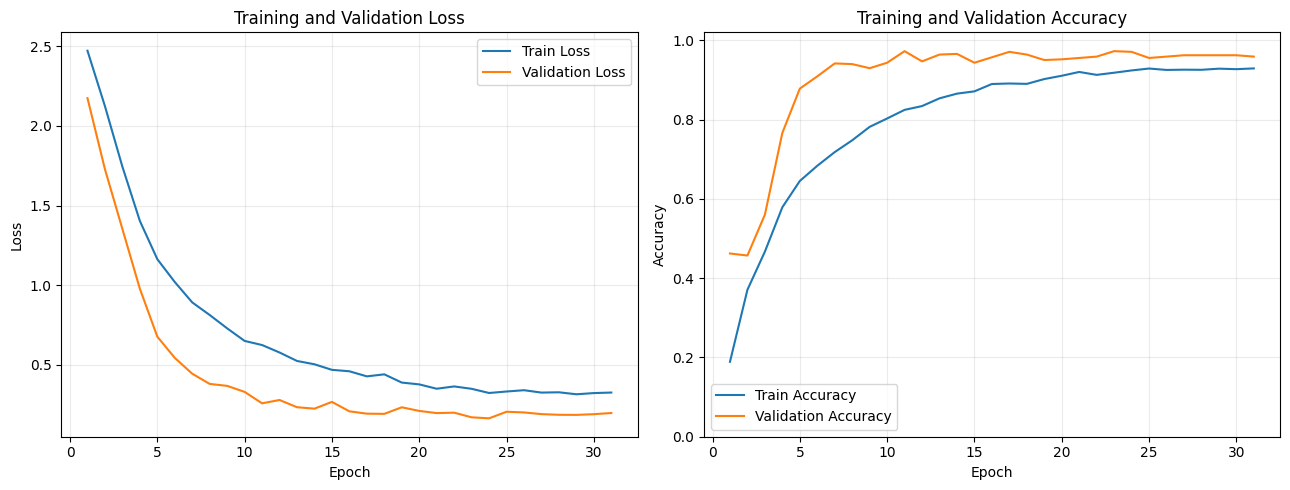


Validation-selected model loaded.

FINAL RESULTS
Train      | Accuracy=0.9958 | Macro Precision=0.9962 | Macro Recall=0.9962 | Macro F1=0.9962 | Weighted F1=0.9958
Validation | Accuracy=0.9725 | Macro Precision=0.9868 | Macro Recall=0.9717 | Macro F1=0.9763 | Weighted F1=0.9710
Test       | Accuracy=0.9291 | Macro Precision=0.9434 | Macro Recall=0.9333 | Macro F1=0.9280 | Weighted F1=0.9268

TEST CLASSIFICATION REPORT
                           precision    recall  f1-score   support

           Standing still     1.0000    1.0000    1.0000        94
     Sitting and relaxing     1.0000    0.5000    0.6667        94
               Lying down     1.0000    1.0000    1.0000        94
                  Walking     1.0000    1.0000    1.0000        94
          Climbing stairs     0.8246    1.0000    0.9038        47
      Waist bends forward     1.0000    1.0000    1.0000        81
Frontal elevation of arms     1.0000    1.0000    1.0000        85
            Knees bending     0.6179    

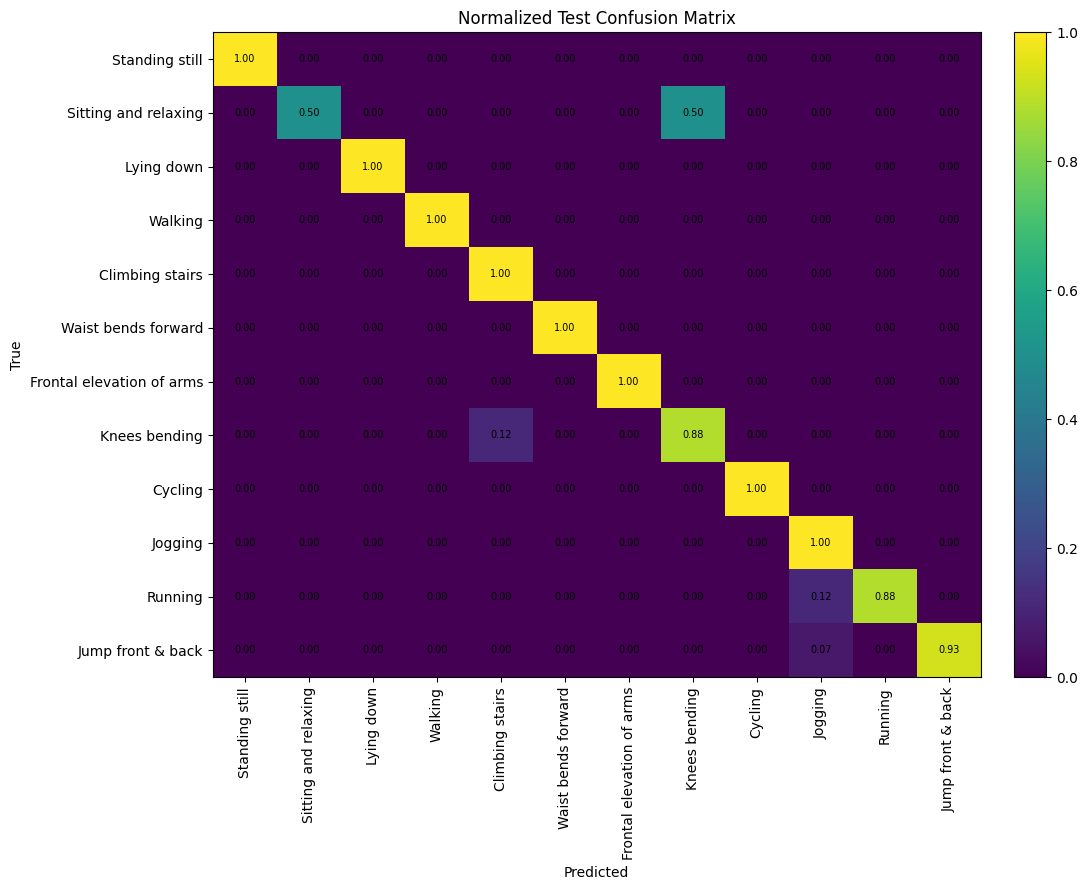


FINAL SUMMARY
Model: 12-Class Multi-Scale CNN + BiLSTM
Parameters: 61,404

Train Accuracy      : 0.9958
Validation Accuracy : 0.9725
Test Accuracy       : 0.9291
Test Macro F1       : 0.9280
Test Weighted F1    : 0.9268

All epoch results saved to: mHealth_preprocessed/cnn_multiscale_bilstm_11class/training_history.csv
Final results saved to: mHealth_preprocessed/cnn_multiscale_bilstm_11class/results.csv
Per-class metrics saved to: mHealth_preprocessed/cnn_multiscale_bilstm_11class/perclass_metrics.csv
Confusion matrices saved to: mHealth_preprocessed/cnn_multiscale_bilstm_11class/confusion_matrix_raw.csv
mHealth_preprocessed/cnn_multiscale_bilstm_11class/confusion_matrix_normalized.csv

Experiment complete.


In [5]:
# ============================================================
# mHealth Dataset
# 12-Class Multi-Scale CNN + BiLSTM

# ============================================================

import os
import random

import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    precision_recall_fscore_support
)

from tensorflow.keras import Model
from tensorflow.keras.layers import (
    Input,
    GaussianNoise,
    Conv1D,
    BatchNormalization,
    SpatialDropout1D,
    MaxPooling1D,
    LSTM,
    Bidirectional,
    Dense,
    Dropout,
    Concatenate,
    Activation
)

from tensorflow.keras.regularizers import l2

from tensorflow.keras.callbacks import (
    Callback,
    EarlyStopping,
    ReduceLROnPlateau,
    TerminateOnNaN
)

from tensorflow.keras.losses import SparseCategoricalCrossentropy


# ============================================================
# 1. REPRODUCIBILITY
# ============================================================

SEED = 43

os.environ["PYTHONHASHSEED"] = str(SEED)

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)


# ============================================================
# 2. DATASET CONFIGURATION
# ============================================================

DATA_DIR = "mHealth_preprocessed"

RESULTS_DIR = os.path.join(
    DATA_DIR,
    "cnn_multiscale_bilstm_11class"
)

os.makedirs(
    RESULTS_DIR,
    exist_ok=True
)

ORIGINAL_NUM_CLASSES = 12
NUM_CLASSES = 12

WINDOW_SIZE = 128
NUM_FEATURES = 23

ACTIVITY_NAMES = [
    "Standing still",
    "Sitting and relaxing",
    "Lying down",
    "Walking",
    "Climbing stairs",
    "Waist bends forward",
    "Frontal elevation of arms",
    "Knees bending",
    "Cycling",
    "Jogging",
    "Running",
    "Jump front & back"
]


# ============================================================
# 3. TRAINING CONFIGURATION
# ============================================================

BATCH_SIZE = 32
EPOCHS = 35

LEARNING_RATE = 2.5e-4
WEIGHT_DECAY = 1e-4
L2_REG = 1.5e-4

INPUT_NOISE = 0.015
INPUT_FEATURE_DROPOUT = 0.10

CNN_DROPOUT = 0.20
TEMPORAL_DROPOUT = 0.25
LSTM_DROPOUT = 0.25
DENSE_DROPOUT = 0.35

EARLY_STOPPING_PATIENCE = 7

LR_PATIENCE = 2
LR_FACTOR = 0.5
MIN_LR = 1e-6


# ============================================================
# 4. CLASS WEIGHTS
# ============================================================

CLASS_WEIGHTS = {
    0: 1.00,
    1: 1.00,
    2: 1.00,
    3: 1.00,
    4: 1.00,
    5: 1.00,
    6: 1.00,
    7: 1.00,
    8: 1.00,
    9: 1.00,
    10: 1.00,
    11: 1.60
}


# ============================================================
# 5. OUTPUT FILES
# ============================================================

MODEL_PATH = os.path.join(
    RESULTS_DIR,
    "best_cnn_multiscale_bilstm_12class.keras"
)

RESULTS_PATH = os.path.join(
    RESULTS_DIR,
    "results.csv"
)

PERCLASS_PATH = os.path.join(
    RESULTS_DIR,
    "perclass_metrics.csv"
)

CM_RAW_PATH = os.path.join(
    RESULTS_DIR,
    "confusion_matrix_raw.csv"
)

CM_NORM_PATH = os.path.join(
    RESULTS_DIR,
    "confusion_matrix_normalized.csv"
)

HISTORY_PATH = os.path.join(
    RESULTS_DIR,
    "training_history.csv"
)


# ============================================================
# 6. GPU
# ============================================================

gpus = tf.config.list_physical_devices("GPU")

print("GPU available:", bool(gpus))

for gpu in gpus:

    try:
        tf.config.experimental.set_memory_growth(
            gpu,
            True
        )
    except RuntimeError:
        pass

    details = tf.config.experimental.get_device_details(
        gpu
    )

    print(
        "GPU:",
        details.get(
            "device_name",
            gpu.name
        )
    )


# ============================================================
# 7. LOAD DATA
# ============================================================

def load_npz(filename):

    filepath = os.path.join(
        DATA_DIR,
        filename
    )

    if not os.path.exists(filepath):
        raise FileNotFoundError(
            f"File not found: {filepath}"
        )

    data = np.load(filepath)

    X = data["X"].astype(np.float32)
    y = data["y"].astype(np.int64)

    return X, y


X_train_raw, y_train_raw = load_npz(
    "train.npz"
)

X_val_raw, y_val_raw = load_npz(
    "validation.npz"
)

X_test_raw, y_test_raw = load_npz(
    "test.npz"
)

print("\nOriginal dataset:")

print(
    "Train:",
    X_train_raw.shape,
    y_train_raw.shape
)

print(
    "Validation:",
    X_val_raw.shape,
    y_val_raw.shape
)

print(
    "Test:",
    X_test_raw.shape,
    y_test_raw.shape
)


# ============================================================
# 8. DATA VALIDATION
# ============================================================

def validate_dataset(
    name,
    X,
    y,
    num_classes
):

    assert X.ndim == 3, (
        f"{name}: X must be 3-dimensional."
    )

    assert X.shape[1] == WINDOW_SIZE, (
        f"{name}: incorrect window size."
    )

    assert X.shape[2] == NUM_FEATURES, (
        f"{name}: incorrect feature count."
    )

    assert len(X) == len(y), (
        f"{name}: X and y lengths differ."
    )

    assert not np.isnan(X).any(), (
        f"{name}: NaN detected."
    )

    assert not np.isinf(X).any(), (
        f"{name}: infinity detected."
    )

    assert np.all(
        (y >= 1) &
        (y <= num_classes)
    ), (
        f"{name}: invalid labels."
    )


validate_dataset(
    "Train",
    X_train_raw,
    y_train_raw,
    ORIGINAL_NUM_CLASSES
)

validate_dataset(
    "Validation",
    X_val_raw,
    y_val_raw,
    ORIGINAL_NUM_CLASSES
)

validate_dataset(
    "Test",
    X_test_raw,
    y_test_raw,
    ORIGINAL_NUM_CLASSES
)


# ============================================================
# 9. KEEP ALL 12 ACTIVITIES
# ============================================================

X_train, y_train = X_train_raw, y_train_raw
X_val, y_val = X_val_raw, y_val_raw
X_test, y_test = X_test_raw, y_test_raw

# ============================================================
# 10. LABEL PREPARATION
# ============================================================

y_train = y_train.astype(np.int64)
y_val = y_val.astype(np.int64)
y_test = y_test.astype(np.int64)

validate_dataset(
    "Train",
    X_train,
    y_train,
    NUM_CLASSES
)

validate_dataset(
    "Validation",
    X_val,
    y_val,
    NUM_CLASSES
)

validate_dataset(
    "Test",
    X_test,
    y_test,
    NUM_CLASSES
)

# Keras uses labels 0 to 11
y_train_model = y_train - 1
y_val_model = y_val - 1
y_test_model = y_test - 1

# ============================================================
# 11. TRAINING DISTRIBUTION
# ============================================================

train_counts = (
    pd.Series(y_train)
    .value_counts()
    .sort_index()
)

print("\nTraining distribution:")

for class_id in range(
    1,
    NUM_CLASSES + 1
):

    count = int(
        train_counts.get(
            class_id,
            0
        )
    )

    print(
        f"{class_id:2d} | "
        f"{ACTIVITY_NAMES[class_id - 1]:25s} | "
        f"{count:5d}"
    )


# ============================================================
# 12. BEST VALIDATION MACRO-F1 CHECKPOINT
# ============================================================

class BestMacroF1Checkpoint(Callback):

    def __init__(
        self,
        x_val,
        y_val,
        filepath
    ):

        super().__init__()

        self.x_val = x_val
        self.y_val = y_val
        self.filepath = filepath
        self.best = -np.inf


    def on_epoch_end(
        self,
        epoch,
        logs=None
    ):

        probabilities = self.model.predict(
            self.x_val,
            batch_size=BATCH_SIZE,
            verbose=0
        )

        predictions = np.argmax(
            probabilities,
            axis=1
        )

        score = f1_score(
            self.y_val,
            predictions,
            average="macro",
            zero_division=0
        )

        if score > self.best:

            self.best = float(score)

            self.model.save(
                self.filepath
            )


# ============================================================
# 13. MODEL
# ============================================================

inputs = Input(
    shape=(
        WINDOW_SIZE,
        NUM_FEATURES
    ),
    name="sensor_input"
)


x = GaussianNoise(
    INPUT_NOISE,
    name="input_noise"
)(inputs)

x = SpatialDropout1D(
    INPUT_FEATURE_DROPOUT,
    name="input_feature_dropout"
)(x)


x = Conv1D(
    filters=48,
    kernel_size=5,
    padding="same",
    activation=None,
    kernel_regularizer=l2(L2_REG),
    name="cnn_block1_conv"
)(x)

x = BatchNormalization(
    name="cnn_block1_bn"
)(x)

x = Activation(
    "relu",
    name="cnn_block1_activation"
)(x)

x = SpatialDropout1D(
    CNN_DROPOUT,
    name="cnn_block1_dropout"
)(x)

x = MaxPooling1D(
    pool_size=2,
    name="cnn_block1_pool"
)(x)


short_branch = Conv1D(
    filters=48,
    kernel_size=3,
    dilation_rate=1,
    padding="same",
    activation=None,
    kernel_regularizer=l2(L2_REG),
    name="temporal_short_conv"
)(x)

short_branch = BatchNormalization(
    name="temporal_short_bn"
)(short_branch)

short_branch = Activation(
    "relu",
    name="temporal_short_activation"
)(short_branch)


long_branch = Conv1D(
    filters=48,
    kernel_size=5,
    dilation_rate=2,
    padding="same",
    activation=None,
    kernel_regularizer=l2(L2_REG),
    name="temporal_long_conv"
)(x)

long_branch = BatchNormalization(
    name="temporal_long_bn"
)(long_branch)

long_branch = Activation(
    "relu",
    name="temporal_long_activation"
)(long_branch)


x = Concatenate(
    axis=-1,
    name="multi_scale_concat"
)(
    [
        short_branch,
        long_branch
    ]
)

x = SpatialDropout1D(
    TEMPORAL_DROPOUT,
    name="multi_scale_dropout"
)(x)


x = Bidirectional(
    LSTM(
        32,
        return_sequences=False,
        dropout=LSTM_DROPOUT,
        recurrent_dropout=0.0,
        kernel_regularizer=l2(L2_REG),
        recurrent_regularizer=l2(L2_REG),
        name="temporal_lstm"
    ),
    name="bidirectional_lstm"
)(x)


x = Dense(
    48,
    activation="relu",
    kernel_regularizer=l2(L2_REG),
    name="dense_features"
)(x)

x = Dropout(
    DENSE_DROPOUT,
    name="classifier_dropout"
)(x)

outputs = Dense(
    NUM_CLASSES,
    activation="softmax",
    name="activity_output"
)(x)


model = Model(
    inputs=inputs,
    outputs=outputs,
    name="mHealth_CNN_MultiScale_BiLSTM_12Class"
)


model.summary()

print(
    "\nParameters:",
    f"{model.count_params():,}"
)


# ============================================================
# 14. COMPILE
# ============================================================

try:

    optimizer = tf.keras.optimizers.AdamW(
        learning_rate=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY,
        clipnorm=1.0
    )

except AttributeError:

    optimizer = tf.keras.optimizers.Adam(
        learning_rate=LEARNING_RATE,
        clipnorm=1.0
    )


model.compile(
    optimizer=optimizer,
    loss=SparseCategoricalCrossentropy(
        from_logits=False
    ),
    metrics=["accuracy"]
)


# ============================================================
# 15. CALLBACKS
# ============================================================

macro_checkpoint = BestMacroF1Checkpoint(
    X_val,
    y_val_model,
    MODEL_PATH
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=LR_FACTOR,
    patience=LR_PATIENCE,
    min_lr=MIN_LR,
    verbose=1
)

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=EARLY_STOPPING_PATIENCE,
    mode="min",
    restore_best_weights=False,
    verbose=1
)

terminate_nan = TerminateOnNaN()


# ============================================================
# 16. TRAINING
# ============================================================

print("\nStarting training...\n")

history = model.fit(
    X_train,
    y_train_model,

    validation_data=(
        X_val,
        y_val_model
    ),

    epochs=EPOCHS,
    batch_size=BATCH_SIZE,

    class_weight=CLASS_WEIGHTS,

    callbacks=[
        macro_checkpoint,
        reduce_lr,
        early_stopping,
        terminate_nan
    ],

    shuffle=True,
    verbose=1
)


# ============================================================
# 17. ALL EPOCH RESULTS
# ============================================================

history_df = pd.DataFrame(
    history.history
)

history_df.insert(
    0,
    "Epoch",
    np.arange(
        1,
        len(history_df) + 1
    )
)


print(
    "\n" + "=" * 75
)

print(
    "ALL EPOCH RESULTS"
)

print(
    "=" * 75
)

print(
    history_df[
        [
            "Epoch",
            "loss",
            "val_loss",
            "accuracy",
            "val_accuracy"
        ]
    ].to_string(
        index=False,
        formatters={
            "loss":
                "{:.4f}".format,

            "val_loss":
                "{:.4f}".format,

            "accuracy":
                "{:.4f}".format,

            "val_accuracy":
                "{:.4f}".format
        }
    )
)


history_df.to_csv(
    HISTORY_PATH,
    index=False
)


# ============================================================
# 18. FINAL TRAINING GRAPHS
# ============================================================

epochs = history_df["Epoch"]


fig, axes = plt.subplots(
    1,
    2,
    figsize=(13, 5)
)


axes[0].plot(
    epochs,
    history_df["loss"],
    label="Train Loss"
)

axes[0].plot(
    epochs,
    history_df["val_loss"],
    label="Validation Loss"
)

axes[0].set_title(
    "Training and Validation Loss"
)

axes[0].set_xlabel(
    "Epoch"
)

axes[0].set_ylabel(
    "Loss"
)

axes[0].legend()

axes[0].grid(
    True,
    alpha=0.25
)


axes[1].plot(
    epochs,
    history_df["accuracy"],
    label="Train Accuracy"
)

axes[1].plot(
    epochs,
    history_df["val_accuracy"],
    label="Validation Accuracy"
)

axes[1].set_title(
    "Training and Validation Accuracy"
)

axes[1].set_xlabel(
    "Epoch"
)

axes[1].set_ylabel(
    "Accuracy"
)

axes[1].set_ylim(
    0,
    1.02
)

axes[1].legend()

axes[1].grid(
    True,
    alpha=0.25
)


plt.tight_layout()
plt.show()
plt.close(fig)


# ============================================================
# 19. LOAD VALIDATION-SELECTED MODEL
# ============================================================

if not os.path.exists(
    MODEL_PATH
):

    raise FileNotFoundError(
        "Validation-selected model was not saved."
    )


best_model = tf.keras.models.load_model(
    MODEL_PATH,
    compile=False
)

print(
    "\nValidation-selected model loaded."
)


# ============================================================
# 20. EVALUATION
# ============================================================

def evaluate_split(
    name,
    X,
    y
):

    probabilities = best_model.predict(
        X,
        batch_size=BATCH_SIZE,
        verbose=0
    )

    predictions = np.argmax(
        probabilities,
        axis=1
    )

    metrics = {
        "Split": name,

        "Accuracy": accuracy_score(
            y,
            predictions
        ),

        "Macro_Precision": precision_score(
            y,
            predictions,
            average="macro",
            zero_division=0
        ),

        "Macro_Recall": recall_score(
            y,
            predictions,
            average="macro",
            zero_division=0
        ),

        "Macro_F1": f1_score(
            y,
            predictions,
            average="macro",
            zero_division=0
        ),

        "Weighted_F1": f1_score(
            y,
            predictions,
            average="weighted",
            zero_division=0
        )
    }

    print(
        f"{name:10s} | "
        f"Accuracy={metrics['Accuracy']:.4f} | "
        f"Macro Precision={metrics['Macro_Precision']:.4f} | "
        f"Macro Recall={metrics['Macro_Recall']:.4f} | "
        f"Macro F1={metrics['Macro_F1']:.4f} | "
        f"Weighted F1={metrics['Weighted_F1']:.4f}"
    )

    return (
        predictions,
        metrics
    )


print(
    "\nFINAL RESULTS"
)

train_predictions, train_metrics = (
    evaluate_split(
        "Train",
        X_train,
        y_train_model
    )
)

val_predictions, val_metrics = (
    evaluate_split(
        "Validation",
        X_val,
        y_val_model
    )
)

test_predictions, test_metrics = (
    evaluate_split(
        "Test",
        X_test,
        y_test_model
    )
)


# ============================================================
# 21. TEST CLASSIFICATION REPORT
# ============================================================

test_predictions_labels = (
    test_predictions + 1
)

print(
    "\nTEST CLASSIFICATION REPORT"
)

print(
    classification_report(
        y_test,
        test_predictions_labels,
        labels=np.arange(
            1,
            NUM_CLASSES + 1
        ),
        target_names=ACTIVITY_NAMES,
        digits=4,
        zero_division=0
    )
)


# ============================================================
# 22. PER-CLASS METRICS
# ============================================================

precision_per_class, \
recall_per_class, \
f1_per_class, \
support_per_class = (
    precision_recall_fscore_support(
        y_test,
        test_predictions_labels,
        labels=np.arange(
            1,
            NUM_CLASSES + 1
        ),
        zero_division=0
    )
)


perclass_df = pd.DataFrame({
    "Activity_ID":
        np.arange(
            1,
            NUM_CLASSES + 1
        ),

    "Activity":
        ACTIVITY_NAMES,

    "Precision":
        precision_per_class,

    "Recall":
        recall_per_class,

    "F1":
        f1_per_class,

    "Support":
        support_per_class
})


perclass_df.to_csv(
    PERCLASS_PATH,
    index=False
)


# ============================================================
# 23. CONFUSION MATRIX
# ============================================================

labels = np.arange(
    1,
    NUM_CLASSES + 1
)

cm = confusion_matrix(
    y_test,
    test_predictions_labels,
    labels=labels
)

with np.errstate(
    divide="ignore",
    invalid="ignore"
):

    cm_normalized = (
        cm.astype(np.float64)
        /
        cm.sum(
            axis=1,
            keepdims=True
        )
    )

cm_normalized = np.nan_to_num(
    cm_normalized
)


pd.DataFrame(
    cm,
    index=ACTIVITY_NAMES,
    columns=ACTIVITY_NAMES
).to_csv(
    CM_RAW_PATH
)

pd.DataFrame(
    cm_normalized,
    index=ACTIVITY_NAMES,
    columns=ACTIVITY_NAMES
).to_csv(
    CM_NORM_PATH
)


# ============================================================
# 24. CONFUSION MATRIX PLOT
# ============================================================

fig, ax = plt.subplots(
    figsize=(11, 9)
)

im = ax.imshow(
    cm_normalized,
    interpolation="nearest",
    aspect="auto"
)

ax.set_title(
    "Normalized Test Confusion Matrix"
)

ax.set_xlabel(
    "Predicted"
)

ax.set_ylabel(
    "True"
)

ax.set_xticks(
    range(NUM_CLASSES)
)

ax.set_yticks(
    range(NUM_CLASSES)
)

ax.set_xticklabels(
    ACTIVITY_NAMES,
    rotation=90
)

ax.set_yticklabels(
    ACTIVITY_NAMES
)

fig.colorbar(
    im,
    ax=ax,
    fraction=0.046,
    pad=0.04
)


for i in range(
    NUM_CLASSES
):

    for j in range(
        NUM_CLASSES
    ):

        ax.text(
            j,
            i,
            f"{cm_normalized[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=7
        )


plt.tight_layout()
plt.show()
plt.close(fig)


# ============================================================
# 25. SAVE FINAL RESULTS
# ============================================================

results_df = pd.DataFrame([
    train_metrics,
    val_metrics,
    test_metrics
])

results_df.to_csv(
    RESULTS_PATH,
    index=False
)


# ============================================================
# 26. FINAL SUMMARY
# ============================================================

print(
    "\n" + "=" * 65
)

print(
    "FINAL SUMMARY"
)

print(
    "=" * 65
)

print(
    "Model:",
    "12-Class Multi-Scale CNN + BiLSTM"
)

print(
    "Parameters:",
    f"{best_model.count_params():,}"
)

print()

print(
    f"Train Accuracy      : "
    f"{train_metrics['Accuracy']:.4f}"
)

print(
    f"Validation Accuracy : "
    f"{val_metrics['Accuracy']:.4f}"
)

print(
    f"Test Accuracy       : "
    f"{test_metrics['Accuracy']:.4f}"
)

print(
    f"Test Macro F1       : "
    f"{test_metrics['Macro_F1']:.4f}"
)

print(
    f"Test Weighted F1    : "
    f"{test_metrics['Weighted_F1']:.4f}"
)

print()

print(
    "All epoch results saved to:",
    HISTORY_PATH
)

print(
    "Final results saved to:",
    RESULTS_PATH
)

print(
    "Per-class metrics saved to:",
    PERCLASS_PATH
)

print(
    "Confusion matrices saved to:",
    CM_RAW_PATH
)

print(
    CM_NORM_PATH
)

print(
    "\nExperiment complete."
)

# CNN

GPU available: True
GPU: Tesla T4
GPU: Tesla T4
Original train: (3127, 128, 23) (3127,)
Original validation: (582, 128, 23) (582,)
Original test: (987, 128, 23) (987,)


Model: "mHealth_CNN_Only_12Class"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ sensor_input        │ (None, 128, 23)   │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_noise         │ (None, 128, 23)   │          0 │ sensor_input[0][… │
│ (GaussianNoise)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_feature_drop… │ (None, 128, 23)   │          0 │ input_noise[0][0] │
│ (SpatialDropout1D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cnn_block1_conv     │ (None, 128, 48)   │      5,568 │ input_feature_dr… │
│ (Conv1D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cnn_block1_bn       │ (None, 128, 48)   │        192 │ cnn_block1_conv[… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cnn_block1_activat… │ (None, 128, 48)   │          0 │ cnn_block1_bn[0]… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cnn_block1_dropout  │ (None, 128, 48)   │          0 │ cnn_block1_activ… │
│ (SpatialDropout1D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cnn_block1_pool     │ (None, 64, 48)    │          0 │ cnn_block1_dropo… │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ temporal_short_conv │ (None, 64, 48)    │      6,960 │ cnn_block1_pool[… │
│ (Conv1D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ temporal_long_conv  │ (None, 64, 48)    │     11,568 │ cnn_block1_pool[… │
│ (Conv1D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ temporal_short_bn   │ (None, 64, 48)    │        192 │ temporal_short_c… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ temporal_long_bn    │ (None, 64, 48)    │        192 │ temporal_long_co… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ temporal_short_act… │ (None, 64, 48)    │          0 │ temporal_short_b… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ temporal_long_acti… │ (None, 64, 48)    │          0 │ temporal_long_bn… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_scale_concat  │ (None, 64, 96)    │          0 │ temporal_short_a… │
│ (Concatenate)       │                   │            │ temporal_long_ac… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_scale_dropout │ (None, 64, 96)    │          0 │ multi_scale_conc… │
│ (SpatialDropout1D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 96)        │          0 │ multi_scale_drop

 Total params: 29,916 (116.86 KB)

 Trainable params: 29,628 (115.73 KB)

 Non-trainable params: 288 (1.12 KB)

Parameters: 29,916
Epoch 1/35
41/98 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.1178 - loss: 2.6060

I0000 00:00:1787469716.135529     134 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


98/98 ━━━━━━━━━━━━━━━━━━━━ 19s 87ms/step - accuracy: 0.2370 - loss: 2.2701 - val_accuracy: 0.3694 - val_loss: 1.8672 - learning_rate: 2.5000e-04
Epoch 2/35
98/98 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.4493 - loss: 1.7250 - val_accuracy: 0.7629 - val_loss: 1.4353 - learning_rate: 2.5000e-04
Epoch 3/35
98/98 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6057 - loss: 1.3539 - val_accuracy: 0.8024 - val_loss: 1.0811 - learning_rate: 2.5000e-04
Epoch 4/35
98/98 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6856 - loss: 1.0850 - val_accuracy: 0.9261 - val_loss: 0.7959 - learning_rate: 2.5000e-04
Epoch 5/35
98/98 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7509 - loss: 0.8925 - val_accuracy: 0.9313 - val_loss: 0.6065 - learning_rate: 2.5000e-04
Epoch 6/35
98/98 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7832 - loss: 0.7694 - val_accuracy: 0.9519 - val_loss: 0.5044 - learning_rate: 2.5000e-04
Epoch 7/35
98/98 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8174 - loss: 0.6696 -

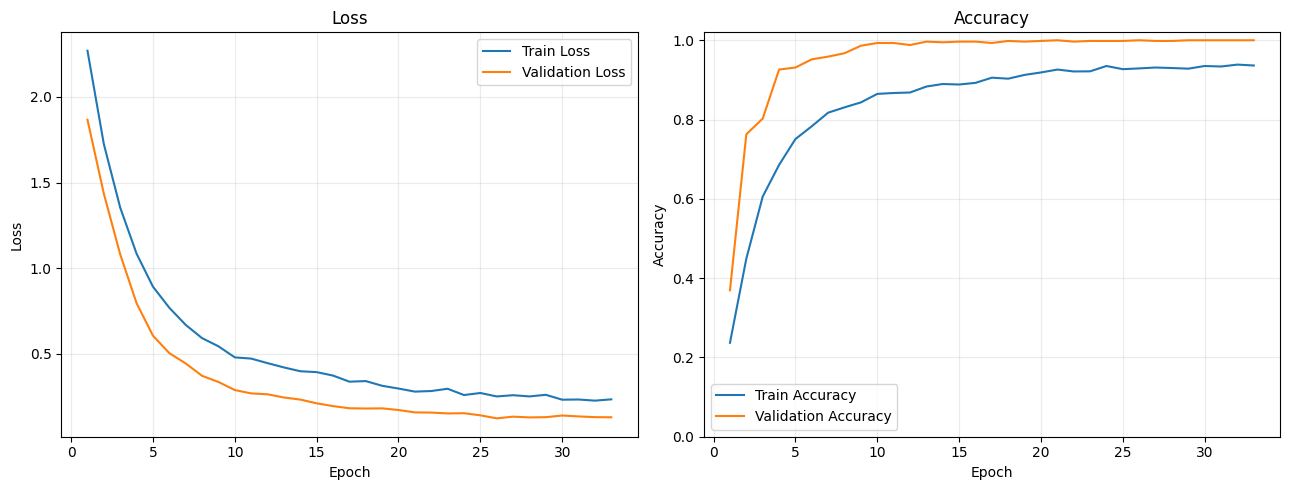


FINAL RESULTS
Train      | Accuracy=0.9965 | Macro F1=0.9967 | Weighted F1=0.9965
Validation | Accuracy=1.0000 | Macro F1=1.0000 | Weighted F1=1.0000
Test       | Accuracy=0.8987 | Macro F1=0.9002 | Weighted F1=0.8933

TEST CLASSIFICATION REPORT

                           precision    recall  f1-score   support

           Standing still     1.0000    1.0000    1.0000        94
     Sitting and relaxing     1.0000    0.5000    0.6667        94
               Lying down     1.0000    1.0000    1.0000        94
                  Walking     1.0000    1.0000    1.0000        94
          Climbing stairs     0.9592    1.0000    0.9792        47
      Waist bends forward     1.0000    1.0000    1.0000        81
Frontal elevation of arms     1.0000    1.0000    1.0000        85
            Knees bending     0.6412    0.9767    0.7742        86
                  Cycling     1.0000    1.0000    1.0000        94
                  Jogging     0.6483    1.0000    0.7866        94
              

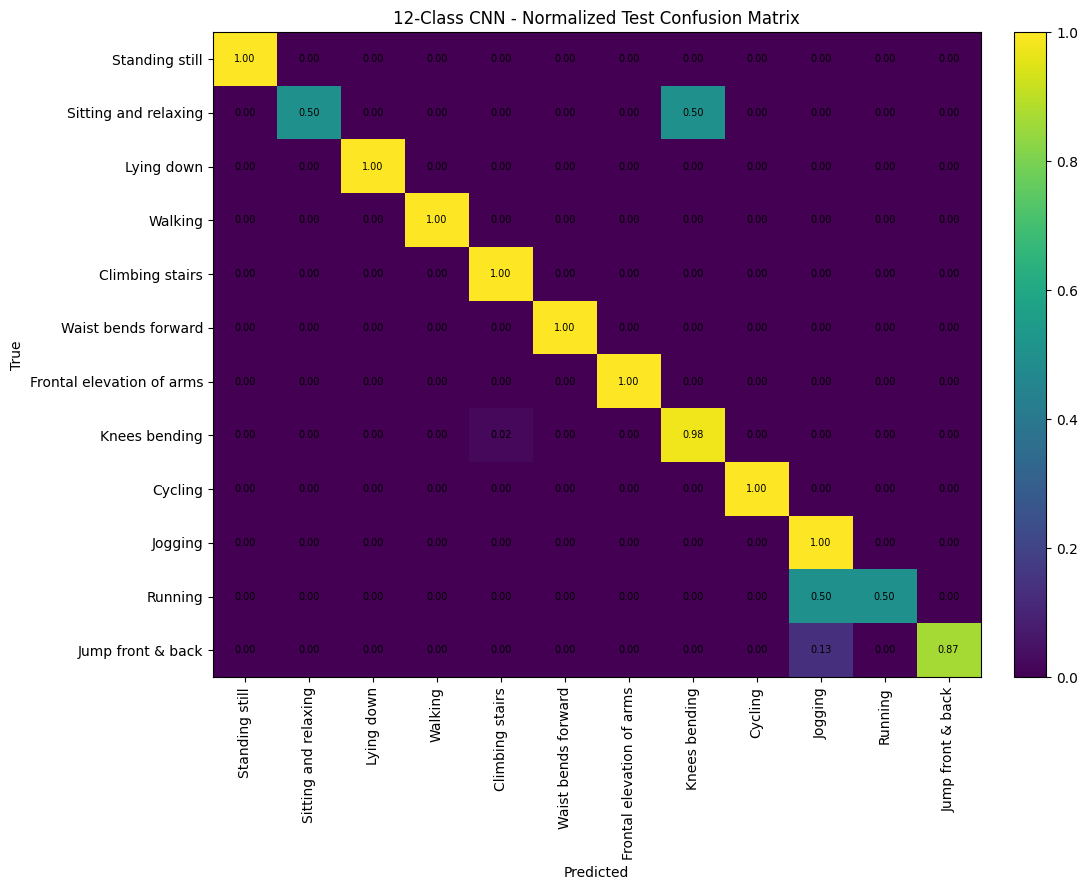


CNN ONLY - FINAL RESULTS
Train Accuracy      : 0.9965
Validation Accuracy : 1.0000
Test Accuracy       : 0.8987
Test Macro F1       : 0.9002
Test Weighted F1    : 0.8933
Parameters          : 29,916


In [6]:
# mHealth Dataset - 12-Class CNN

import os
import random
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    precision_recall_fscore_support
)

from tensorflow.keras import Model
from tensorflow.keras.layers import (
    Input,
    GaussianNoise,
    Conv1D,
    BatchNormalization,
    SpatialDropout1D,
    MaxPooling1D,
    Dense,
    Dropout,
    Concatenate,
    Activation,
    GlobalAveragePooling1D
)
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    TerminateOnNaN
)
from tensorflow.keras.losses import SparseCategoricalCrossentropy


# Configuration

SEED = 43

DATA_DIR = "mHealth_preprocessed"
RESULTS_DIR = os.path.join(DATA_DIR, "cnn_only_12class")

os.makedirs(RESULTS_DIR, exist_ok=True)

WINDOW_SIZE = 128
NUM_FEATURES = 23
NUM_CLASSES = 12

BATCH_SIZE = 32
EPOCHS = 35
LEARNING_RATE = 2.5e-4
WEIGHT_DECAY = 1e-4
L2_REG = 1.5e-4

INPUT_NOISE = 0.015
INPUT_FEATURE_DROPOUT = 0.10
CNN_DROPOUT = 0.20
TEMPORAL_DROPOUT = 0.25
DENSE_DROPOUT = 0.35

EARLY_STOPPING_PATIENCE = 7
LR_PATIENCE = 2
LR_FACTOR = 0.5
MIN_LR = 1e-6

CLASS_WEIGHTS = {
    0: 1.00,
    1: 1.00,
    2: 1.00,
    3: 1.00,
    4: 1.00,
    5: 1.00,
    6: 1.00,
    7: 1.00,
    8: 1.00,
    9: 1.00,
    10: 1.00,
    11: 1.60
}

ACTIVITY_NAMES = [
    "Standing still",
    "Sitting and relaxing",
    "Lying down",
    "Walking",
    "Climbing stairs",
    "Waist bends forward",
    "Frontal elevation of arms",
    "Knees bending",
    "Cycling",
    "Jogging",
    "Running",
    "Jump front & back"
]

MODEL_PATH = os.path.join(
    RESULTS_DIR,
    "cnn_only_12class.keras"
)

RESULTS_PATH = os.path.join(
    RESULTS_DIR,
    "results.csv"
)

PERCLASS_PATH = os.path.join(
    RESULTS_DIR,
    "perclass_metrics.csv"
)

CM_PATH = os.path.join(
    RESULTS_DIR,
    "confusion_matrix.csv"
)

CM_NORM_PATH = os.path.join(
    RESULTS_DIR,
    "confusion_matrix_normalized.csv"
)

HISTORY_PATH = os.path.join(
    RESULTS_DIR,
    "training_history.csv"
)


# Reproducibility

os.environ["PYTHONHASHSEED"] = str(SEED)

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)


# GPU

gpus = tf.config.list_physical_devices("GPU")

print("GPU available:", bool(gpus))

for gpu in gpus:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError:
        pass

    details = tf.config.experimental.get_device_details(gpu)
    print("GPU:", details.get("device_name", gpu.name))


# Data loading

def load_npz(filename):
    path = os.path.join(DATA_DIR, filename)

    if not os.path.exists(path):
        raise FileNotFoundError(path)

    data = np.load(path)

    return (
        data["X"].astype(np.float32),
        data["y"].astype(np.int64)
    )


X_train_raw, y_train_raw = load_npz("train.npz")
X_val_raw, y_val_raw = load_npz("validation.npz")
X_test_raw, y_test_raw = load_npz("test.npz")

print("Original train:", X_train_raw.shape, y_train_raw.shape)
print("Original validation:", X_val_raw.shape, y_val_raw.shape)
print("Original test:", X_test_raw.shape, y_test_raw.shape)


# Keep all 12 activities

X_train, y_train = X_train_raw, y_train_raw
X_val, y_val = X_val_raw, y_val_raw
X_test, y_test = X_test_raw, y_test_raw

# Label preparation

y_train = y_train.astype(np.int64)
y_val = y_val.astype(np.int64)
y_test = y_test.astype(np.int64)

expected = np.arange(1, NUM_CLASSES + 1)

assert np.array_equal(
    np.sort(np.unique(y_train)),
    expected
)

assert np.array_equal(
    np.sort(np.unique(y_val)),
    expected
)

assert np.array_equal(
    np.sort(np.unique(y_test)),
    expected
)

# Keras uses labels 0 to 11
y_train_model = y_train - 1
y_val_model = y_val - 1
y_test_model = y_test - 1


# CNN model

inputs = Input(
    shape=(WINDOW_SIZE, NUM_FEATURES),
    name="sensor_input"
)

x = GaussianNoise(
    INPUT_NOISE,
    name="input_noise"
)(inputs)

x = SpatialDropout1D(
    INPUT_FEATURE_DROPOUT,
    name="input_feature_dropout"
)(x)


x = Conv1D(
    filters=48,
    kernel_size=5,
    padding="same",
    activation=None,
    kernel_regularizer=l2(L2_REG),
    name="cnn_block1_conv"
)(x)

x = BatchNormalization(
    name="cnn_block1_bn"
)(x)

x = Activation(
    "relu",
    name="cnn_block1_activation"
)(x)

x = SpatialDropout1D(
    CNN_DROPOUT,
    name="cnn_block1_dropout"
)(x)

x = MaxPooling1D(
    pool_size=2,
    name="cnn_block1_pool"
)(x)


branch_short = Conv1D(
    filters=48,
    kernel_size=3,
    dilation_rate=1,
    padding="same",
    activation=None,
    kernel_regularizer=l2(L2_REG),
    name="temporal_short_conv"
)(x)

branch_short = BatchNormalization(
    name="temporal_short_bn"
)(branch_short)

branch_short = Activation(
    "relu",
    name="temporal_short_activation"
)(branch_short)


branch_long = Conv1D(
    filters=48,
    kernel_size=5,
    dilation_rate=2,
    padding="same",
    activation=None,
    kernel_regularizer=l2(L2_REG),
    name="temporal_long_conv"
)(x)

branch_long = BatchNormalization(
    name="temporal_long_bn"
)(branch_long)

branch_long = Activation(
    "relu",
    name="temporal_long_activation"
)(branch_long)


x = Concatenate(
    axis=-1,
    name="multi_scale_concat"
)([
    branch_short,
    branch_long
])

x = SpatialDropout1D(
    TEMPORAL_DROPOUT,
    name="multi_scale_dropout"
)(x)


x = GlobalAveragePooling1D(
    name="global_average_pooling"
)(x)

x = Dense(
    48,
    activation="relu",
    kernel_regularizer=l2(L2_REG),
    name="dense_features"
)(x)

x = Dropout(
    DENSE_DROPOUT,
    name="classifier_dropout"
)(x)

outputs = Dense(
    NUM_CLASSES,
    activation="softmax",
    name="activity_output"
)(x)

model = Model(
    inputs=inputs,
    outputs=outputs,
    name="mHealth_CNN_Only_12Class"
)

model.summary()

print("Parameters:", f"{model.count_params():,}")


# Training setup

try:
    optimizer = tf.keras.optimizers.AdamW(
        learning_rate=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY,
        clipnorm=1.0
    )
except AttributeError:
    optimizer = tf.keras.optimizers.Adam(
        learning_rate=LEARNING_RATE,
        clipnorm=1.0
    )

loss_fn = SparseCategoricalCrossentropy(
    from_logits=False
)

model.compile(
    optimizer=optimizer,
    loss=loss_fn,
    metrics=["accuracy"]
)


# Callbacks

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=LR_FACTOR,
    patience=LR_PATIENCE,
    min_lr=MIN_LR,
    verbose=1
)

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=EARLY_STOPPING_PATIENCE,
    mode="min",
    restore_best_weights=False,
    verbose=1
)

terminate_nan = TerminateOnNaN()


# Training

history = model.fit(
    X_train,
    y_train_model,
    validation_data=(
        X_val,
        y_val_model
    ),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    class_weight=CLASS_WEIGHTS,
    callbacks=[
        reduce_lr,
        early_stopping,
        terminate_nan
    ],
    shuffle=True,
    verbose=1
)


# Save training history

epoch_df = pd.DataFrame({
    "Epoch": np.arange(
        1,
        len(history.history["loss"]) + 1
    ),
    "Train_Loss": history.history["loss"],
    "Validation_Loss": history.history["val_loss"],
    "Train_Accuracy": history.history["accuracy"],
    "Validation_Accuracy": history.history["val_accuracy"]
})

epoch_df.to_csv(
    HISTORY_PATH,
    index=False
)


# Training curves

epochs = np.arange(
    1,
    len(history.history["loss"]) + 1
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(13, 5)
)

axes[0].plot(
    epochs,
    history.history["loss"],
    label="Train Loss"
)

axes[0].plot(
    epochs,
    history.history["val_loss"],
    label="Validation Loss"
)

axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True, alpha=0.25)

axes[1].plot(
    epochs,
    history.history["accuracy"],
    label="Train Accuracy"
)

axes[1].plot(
    epochs,
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

axes[1].set_title("Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].set_ylim(0, 1.02)
axes[1].legend()
axes[1].grid(True, alpha=0.25)

plt.tight_layout()
plt.show()
plt.close(fig)


# Save trained model

model.save(MODEL_PATH)


# Evaluation

def evaluate_split(name, X, y):

    probs = model.predict(
        X,
        batch_size=BATCH_SIZE,
        verbose=0
    )

    preds = np.argmax(
        probs,
        axis=1
    )

    metrics = {
        "Split": name,
        "Accuracy": accuracy_score(y, preds),
        "Macro_Precision": precision_score(
            y,
            preds,
            average="macro",
            zero_division=0
        ),
        "Macro_Recall": recall_score(
            y,
            preds,
            average="macro",
            zero_division=0
        ),
        "Macro_F1": f1_score(
            y,
            preds,
            average="macro",
            zero_division=0
        ),
        "Weighted_F1": f1_score(
            y,
            preds,
            average="weighted",
            zero_division=0
        )
    }

    print(
        f"{name:10s} | "
        f"Accuracy={metrics['Accuracy']:.4f} | "
        f"Macro F1={metrics['Macro_F1']:.4f} | "
        f"Weighted F1={metrics['Weighted_F1']:.4f}"
    )

    return probs, preds, metrics


print("\nFINAL RESULTS")

train_probs, train_preds, train_metrics = evaluate_split(
    "Train",
    X_train,
    y_train_model
)

val_probs, val_preds, val_metrics = evaluate_split(
    "Validation",
    X_val,
    y_val_model
)

test_probs, test_preds, test_metrics = evaluate_split(
    "Test",
    X_test,
    y_test_model
)


# Test classification report

y_pred_labels = test_preds + 1

print("\nTEST CLASSIFICATION REPORT\n")

print(
    classification_report(
        y_test,
        y_pred_labels,
        labels=np.arange(1, NUM_CLASSES + 1),
        target_names=ACTIVITY_NAMES,
        digits=4,
        zero_division=0
    )
)


# Per-class metrics

precision, recall, f1, support = (
    precision_recall_fscore_support(
        y_test,
        y_pred_labels,
        labels=np.arange(1, NUM_CLASSES + 1),
        zero_division=0
    )
)

perclass_df = pd.DataFrame({
    "Activity_ID": np.arange(
        1,
        NUM_CLASSES + 1
    ),
    "Activity": ACTIVITY_NAMES,
    "Precision": precision,
    "Recall": recall,
    "F1": f1,
    "Support": support
})

perclass_df.to_csv(
    PERCLASS_PATH,
    index=False
)


# Confusion matrix

labels = np.arange(
    1,
    NUM_CLASSES + 1
)

cm = confusion_matrix(
    y_test,
    y_pred_labels,
    labels=labels
)

with np.errstate(
    divide="ignore",
    invalid="ignore"
):
    cm_normalized = (
        cm.astype(np.float64)
        /
        cm.sum(
            axis=1,
            keepdims=True
        )
    )

cm_normalized = np.nan_to_num(
    cm_normalized
)

pd.DataFrame(
    cm,
    index=ACTIVITY_NAMES,
    columns=ACTIVITY_NAMES
).to_csv(
    CM_PATH
)

pd.DataFrame(
    cm_normalized,
    index=ACTIVITY_NAMES,
    columns=ACTIVITY_NAMES
).to_csv(
    CM_NORM_PATH
)


# Confusion matrix plot

fig, ax = plt.subplots(
    figsize=(11, 9)
)

im = ax.imshow(
    cm_normalized,
    interpolation="nearest",
    aspect="auto"
)

ax.set_title(
    "12-Class CNN - Normalized Test Confusion Matrix"
)

ax.set_xlabel("Predicted")
ax.set_ylabel("True")

ax.set_xticks(range(NUM_CLASSES))
ax.set_yticks(range(NUM_CLASSES))

ax.set_xticklabels(
    ACTIVITY_NAMES,
    rotation=90
)

ax.set_yticklabels(
    ACTIVITY_NAMES
)

fig.colorbar(
    im,
    ax=ax,
    fraction=0.046,
    pad=0.04
)

for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        ax.text(
            j,
            i,
            f"{cm_normalized[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=7
        )

plt.tight_layout()
plt.show()
plt.close(fig)


# Save final results

pd.DataFrame([
    train_metrics,
    val_metrics,
    test_metrics
]).to_csv(
    RESULTS_PATH,
    index=False
)


# Final summary

print("\nCNN ONLY - FINAL RESULTS")

print(
    f"Train Accuracy      : "
    f"{train_metrics['Accuracy']:.4f}"
)

print(
    f"Validation Accuracy : "
    f"{val_metrics['Accuracy']:.4f}"
)

print(
    f"Test Accuracy       : "
    f"{test_metrics['Accuracy']:.4f}"
)

print(
    f"Test Macro F1       : "
    f"{test_metrics['Macro_F1']:.4f}"
)

print(
    f"Test Weighted F1    : "
    f"{test_metrics['Weighted_F1']:.4f}"
)

print(
    f"Parameters          : "
    f"{model.count_params():,}"
)

GPU available: True
GPU: Tesla T4
GPU: Tesla T4
Original train: (3127, 128, 23) (3127,)
Original validation: (582, 128, 23) (582,)
Original test: (987, 128, 23) (987,)
Train after removal: (2845, 128, 23)
Validation after removal: (535, 128, 23)
Test after removal: (893, 128, 23)


Model: "mHealth_CNN_Only_11Class"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ sensor_input        │ (None, 128, 23)   │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_noise         │ (None, 128, 23)   │          0 │ sensor_input[0][… │
│ (GaussianNoise)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_feature_drop… │ (None, 128, 23)   │          0 │ input_noise[0][0] │
│ (SpatialDropout1D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cnn_block1_conv     │ (None, 128, 48)   │      5,568 │ input_feature_dr… │
│ (Conv1D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cnn_block1_bn       │ (None, 128, 48)   │        192 │ cnn_block1_conv[… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cnn_block1_activat… │ (None, 128, 48)   │          0 │ cnn_block1_bn[0]… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cnn_block1_dropout  │ (None, 128, 48)   │          0 │ cnn_block1_activ… │
│ (SpatialDropout1D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cnn_block1_pool     │ (None, 64, 48)    │          0 │ cnn_block1_dropo… │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ temporal_short_conv │ (None, 64, 48)    │      6,960 │ cnn_block1_pool[… │
│ (Conv1D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ temporal_long_conv  │ (None, 64, 48)    │     11,568 │ cnn_block1_pool[… │
│ (Conv1D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ temporal_short_bn   │ (None, 64, 48)    │        192 │ temporal_short_c… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ temporal_long_bn    │ (None, 64, 48)    │        192 │ temporal_long_co… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ temporal_short_act… │ (None, 64, 48)    │          0 │ temporal_short_b… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ temporal_long_acti… │ (None, 64, 48)    │          0 │ temporal_long_bn… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_scale_concat  │ (None, 64, 96)    │          0 │ temporal_short_a… │
│ (Concatenate)       │                   │            │ temporal_long_ac… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_scale_dropout │ (None, 64, 96)    │          0 │ multi_scale_conc… │
│ (SpatialDropout1D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 96)        │          0 │ multi_scale_drop

 Total params: 29,867 (116.67 KB)

 Trainable params: 29,579 (115.54 KB)

 Non-trainable params: 288 (1.12 KB)

Parameters: 29,867
Epoch 1/35
89/89 ━━━━━━━━━━━━━━━━━━━━ 18s 96ms/step - accuracy: 0.2671 - loss: 2.1950 - val_accuracy: 0.5664 - val_loss: 1.7792 - learning_rate: 2.5000e-04
Epoch 2/35
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.5336 - loss: 1.5606 - val_accuracy: 0.7701 - val_loss: 1.2271 - learning_rate: 2.5000e-04
Epoch 3/35
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.6475 - loss: 1.2175 - val_accuracy: 0.8654 - val_loss: 0.9050 - learning_rate: 2.5000e-04
Epoch 4/35
89/89 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7139 - loss: 0.9835 - val_accuracy: 0.9159 - val_loss: 0.6810 - learning_rate: 2.5000e-04
Epoch 5/35
89/89 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7603 - loss: 0.8409 - val_accuracy: 0.9383 - val_loss: 0.5365 - learning_rate: 2.5000e-04
Epoch 6/35
89/89 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8039 - loss: 0.7062 - val_accuracy: 0.9626 - val_loss: 0.4378 - learning_rate: 2.5000e-04
Epoch 7/35
89/89 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - acc

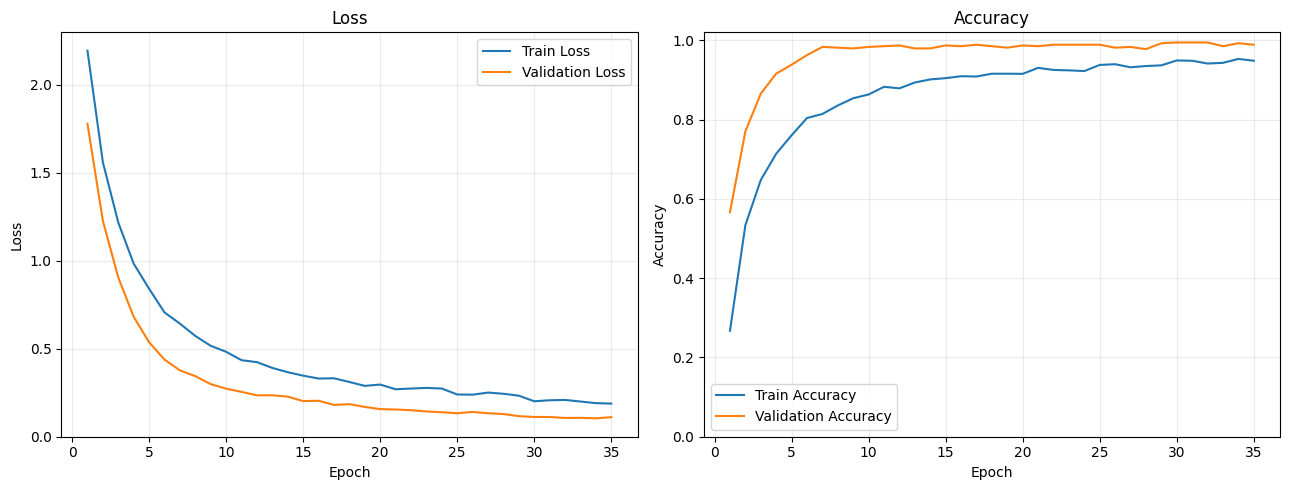


FINAL RESULTS
Train      | Accuracy=0.9986 | Macro F1=0.9987 | Weighted F1=0.9986
Validation | Accuracy=0.9888 | Macro F1=0.9898 | Weighted F1=0.9887
Test       | Accuracy=0.9306 | Macro F1=0.9303 | Weighted F1=0.9274

TEST CLASSIFICATION REPORT

                           precision    recall  f1-score   support

           Standing still     1.0000    1.0000    1.0000        94
               Lying down     1.0000    1.0000    1.0000        94
                  Walking     1.0000    1.0000    1.0000        94
          Climbing stairs     0.7581    1.0000    0.8624        47
      Waist bends forward     1.0000    1.0000    1.0000        81
Frontal elevation of arms     1.0000    1.0000    1.0000        85
            Knees bending     1.0000    0.8256    0.9045        86
                  Cycling     1.0000    1.0000    1.0000        94
                  Jogging     0.6667    1.0000    0.8000        94
                  Running     1.0000    0.5000    0.6667        94
        Jump f

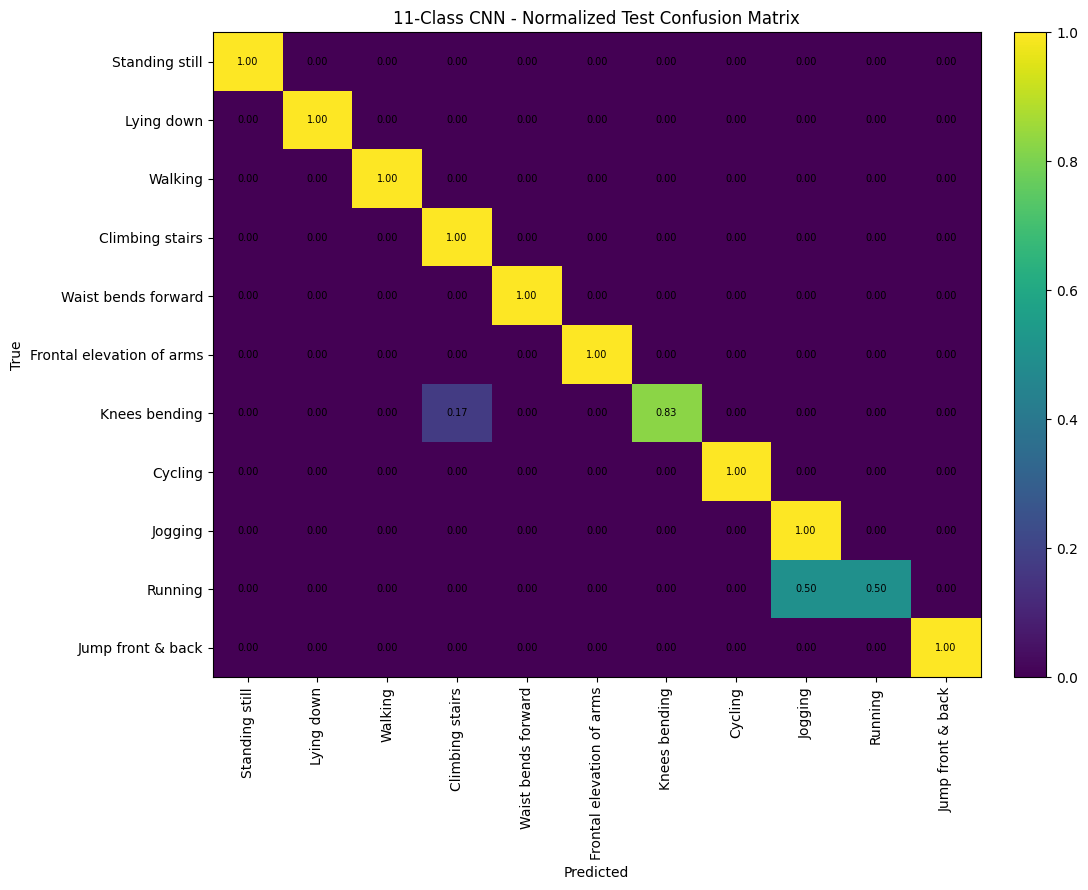


CNN ONLY - FINAL RESULTS
Train Accuracy      : 0.9986
Validation Accuracy : 0.9888
Test Accuracy       : 0.9306
Test Macro F1       : 0.9303
Test Weighted F1    : 0.9274
Parameters          : 29,867


In [7]:
# mHealth Dataset - 11-Class CNN

import os
import random
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    precision_recall_fscore_support
)

from tensorflow.keras import Model
from tensorflow.keras.layers import (
    Input,
    GaussianNoise,
    Conv1D,
    BatchNormalization,
    SpatialDropout1D,
    MaxPooling1D,
    Dense,
    Dropout,
    Concatenate,
    Activation,
    GlobalAveragePooling1D
)
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    TerminateOnNaN
)
from tensorflow.keras.losses import SparseCategoricalCrossentropy


# Configuration

SEED = 43

DATA_DIR = "mHealth_preprocessed"
RESULTS_DIR = os.path.join(DATA_DIR, "cnn_only_11class")

os.makedirs(RESULTS_DIR, exist_ok=True)

WINDOW_SIZE = 128
NUM_FEATURES = 23
NUM_CLASSES = 11
REMOVED_ACTIVITY = 2

BATCH_SIZE = 32
EPOCHS = 35
LEARNING_RATE = 2.5e-4
WEIGHT_DECAY = 1e-4
L2_REG = 1.5e-4

INPUT_NOISE = 0.015
INPUT_FEATURE_DROPOUT = 0.10
CNN_DROPOUT = 0.20
TEMPORAL_DROPOUT = 0.25
DENSE_DROPOUT = 0.35

EARLY_STOPPING_PATIENCE = 7
LR_PATIENCE = 2
LR_FACTOR = 0.5
MIN_LR = 1e-6

CLASS_WEIGHTS = {
    0: 1.00,
    1: 1.00,
    2: 1.00,
    3: 1.00,
    4: 1.00,
    5: 1.00,
    6: 1.00,
    7: 1.00,
    8: 1.00,
    9: 1.00,
    10: 1.60
}

ACTIVITY_NAMES = [
    "Standing still",
    "Lying down",
    "Walking",
    "Climbing stairs",
    "Waist bends forward",
    "Frontal elevation of arms",
    "Knees bending",
    "Cycling",
    "Jogging",
    "Running",
    "Jump front & back"
]

MODEL_PATH = os.path.join(
    RESULTS_DIR,
    "cnn_only_11class.keras"
)

RESULTS_PATH = os.path.join(
    RESULTS_DIR,
    "results.csv"
)

PERCLASS_PATH = os.path.join(
    RESULTS_DIR,
    "perclass_metrics.csv"
)

CM_PATH = os.path.join(
    RESULTS_DIR,
    "confusion_matrix.csv"
)

CM_NORM_PATH = os.path.join(
    RESULTS_DIR,
    "confusion_matrix_normalized.csv"
)

HISTORY_PATH = os.path.join(
    RESULTS_DIR,
    "training_history.csv"
)


# Reproducibility

os.environ["PYTHONHASHSEED"] = str(SEED)

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)


# GPU

gpus = tf.config.list_physical_devices("GPU")

print("GPU available:", bool(gpus))

for gpu in gpus:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError:
        pass

    details = tf.config.experimental.get_device_details(gpu)
    print("GPU:", details.get("device_name", gpu.name))


# Data loading

def load_npz(filename):
    path = os.path.join(DATA_DIR, filename)

    if not os.path.exists(path):
        raise FileNotFoundError(path)

    data = np.load(path)

    return (
        data["X"].astype(np.float32),
        data["y"].astype(np.int64)
    )


X_train_raw, y_train_raw = load_npz("train.npz")
X_val_raw, y_val_raw = load_npz("validation.npz")
X_test_raw, y_test_raw = load_npz("test.npz")

print("Original train:", X_train_raw.shape, y_train_raw.shape)
print("Original validation:", X_val_raw.shape, y_val_raw.shape)
print("Original test:", X_test_raw.shape, y_test_raw.shape)


# Remove activity 2

def remove_activity_2(X, y):
    mask = y != REMOVED_ACTIVITY
    return X[mask], y[mask]


X_train, y_train_original = remove_activity_2(
    X_train_raw,
    y_train_raw
)

X_val, y_val_original = remove_activity_2(
    X_val_raw,
    y_val_raw
)

X_test, y_test_original = remove_activity_2(
    X_test_raw,
    y_test_raw
)

print("Train after removal:", X_train.shape)
print("Validation after removal:", X_val.shape)
print("Test after removal:", X_test.shape)

assert REMOVED_ACTIVITY not in y_train_original
assert REMOVED_ACTIVITY not in y_val_original
assert REMOVED_ACTIVITY not in y_test_original


# Label remapping

def remap_labels(y):
    y_new = np.where(
        y > REMOVED_ACTIVITY,
        y - 1,
        y
    ).astype(np.int64)

    assert np.all(
        (y_new >= 1) &
        (y_new <= NUM_CLASSES)
    )

    return y_new


y_train = remap_labels(y_train_original)
y_val = remap_labels(y_val_original)
y_test = remap_labels(y_test_original)

expected = np.arange(1, NUM_CLASSES + 1)

assert np.array_equal(
    np.sort(np.unique(y_train)),
    expected
)

assert np.array_equal(
    np.sort(np.unique(y_val)),
    expected
)

assert np.array_equal(
    np.sort(np.unique(y_test)),
    expected
)

y_train_model = y_train - 1
y_val_model = y_val - 1
y_test_model = y_test - 1


# CNN model

inputs = Input(
    shape=(WINDOW_SIZE, NUM_FEATURES),
    name="sensor_input"
)

x = GaussianNoise(
    INPUT_NOISE,
    name="input_noise"
)(inputs)

x = SpatialDropout1D(
    INPUT_FEATURE_DROPOUT,
    name="input_feature_dropout"
)(x)


x = Conv1D(
    filters=48,
    kernel_size=5,
    padding="same",
    activation=None,
    kernel_regularizer=l2(L2_REG),
    name="cnn_block1_conv"
)(x)

x = BatchNormalization(
    name="cnn_block1_bn"
)(x)

x = Activation(
    "relu",
    name="cnn_block1_activation"
)(x)

x = SpatialDropout1D(
    CNN_DROPOUT,
    name="cnn_block1_dropout"
)(x)

x = MaxPooling1D(
    pool_size=2,
    name="cnn_block1_pool"
)(x)


branch_short = Conv1D(
    filters=48,
    kernel_size=3,
    dilation_rate=1,
    padding="same",
    activation=None,
    kernel_regularizer=l2(L2_REG),
    name="temporal_short_conv"
)(x)

branch_short = BatchNormalization(
    name="temporal_short_bn"
)(branch_short)

branch_short = Activation(
    "relu",
    name="temporal_short_activation"
)(branch_short)


branch_long = Conv1D(
    filters=48,
    kernel_size=5,
    dilation_rate=2,
    padding="same",
    activation=None,
    kernel_regularizer=l2(L2_REG),
    name="temporal_long_conv"
)(x)

branch_long = BatchNormalization(
    name="temporal_long_bn"
)(branch_long)

branch_long = Activation(
    "relu",
    name="temporal_long_activation"
)(branch_long)


x = Concatenate(
    axis=-1,
    name="multi_scale_concat"
)([
    branch_short,
    branch_long
])

x = SpatialDropout1D(
    TEMPORAL_DROPOUT,
    name="multi_scale_dropout"
)(x)


x = GlobalAveragePooling1D(
    name="global_average_pooling"
)(x)

x = Dense(
    48,
    activation="relu",
    kernel_regularizer=l2(L2_REG),
    name="dense_features"
)(x)

x = Dropout(
    DENSE_DROPOUT,
    name="classifier_dropout"
)(x)

outputs = Dense(
    NUM_CLASSES,
    activation="softmax",
    name="activity_output"
)(x)

model = Model(
    inputs=inputs,
    outputs=outputs,
    name="mHealth_CNN_Only_11Class"
)

model.summary()

print("Parameters:", f"{model.count_params():,}")


# Training setup

try:
    optimizer = tf.keras.optimizers.AdamW(
        learning_rate=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY,
        clipnorm=1.0
    )
except AttributeError:
    optimizer = tf.keras.optimizers.Adam(
        learning_rate=LEARNING_RATE,
        clipnorm=1.0
    )

loss_fn = SparseCategoricalCrossentropy(
    from_logits=False
)

model.compile(
    optimizer=optimizer,
    loss=loss_fn,
    metrics=["accuracy"]
)


# Callbacks

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=LR_FACTOR,
    patience=LR_PATIENCE,
    min_lr=MIN_LR,
    verbose=1
)

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=EARLY_STOPPING_PATIENCE,
    mode="min",
    restore_best_weights=False,
    verbose=1
)

terminate_nan = TerminateOnNaN()


# Training

history = model.fit(
    X_train,
    y_train_model,
    validation_data=(
        X_val,
        y_val_model
    ),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    class_weight=CLASS_WEIGHTS,
    callbacks=[
        reduce_lr,
        early_stopping,
        terminate_nan
    ],
    shuffle=True,
    verbose=1
)


# Save training history

epoch_df = pd.DataFrame({
    "Epoch": np.arange(
        1,
        len(history.history["loss"]) + 1
    ),
    "Train_Loss": history.history["loss"],
    "Validation_Loss": history.history["val_loss"],
    "Train_Accuracy": history.history["accuracy"],
    "Validation_Accuracy": history.history["val_accuracy"]
})

epoch_df.to_csv(
    HISTORY_PATH,
    index=False
)


# Training curves

epochs = np.arange(
    1,
    len(history.history["loss"]) + 1
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(13, 5)
)

axes[0].plot(
    epochs,
    history.history["loss"],
    label="Train Loss"
)

axes[0].plot(
    epochs,
    history.history["val_loss"],
    label="Validation Loss"
)

axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True, alpha=0.25)

axes[1].plot(
    epochs,
    history.history["accuracy"],
    label="Train Accuracy"
)

axes[1].plot(
    epochs,
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

axes[1].set_title("Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].set_ylim(0, 1.02)
axes[1].legend()
axes[1].grid(True, alpha=0.25)

plt.tight_layout()
plt.show()
plt.close(fig)


# Save trained model

model.save(MODEL_PATH)


# Evaluation

def evaluate_split(name, X, y):

    probs = model.predict(
        X,
        batch_size=BATCH_SIZE,
        verbose=0
    )

    preds = np.argmax(
        probs,
        axis=1
    )

    metrics = {
        "Split": name,
        "Accuracy": accuracy_score(y, preds),
        "Macro_Precision": precision_score(
            y,
            preds,
            average="macro",
            zero_division=0
        ),
        "Macro_Recall": recall_score(
            y,
            preds,
            average="macro",
            zero_division=0
        ),
        "Macro_F1": f1_score(
            y,
            preds,
            average="macro",
            zero_division=0
        ),
        "Weighted_F1": f1_score(
            y,
            preds,
            average="weighted",
            zero_division=0
        )
    }

    print(
        f"{name:10s} | "
        f"Accuracy={metrics['Accuracy']:.4f} | "
        f"Macro F1={metrics['Macro_F1']:.4f} | "
        f"Weighted F1={metrics['Weighted_F1']:.4f}"
    )

    return probs, preds, metrics


print("\nFINAL RESULTS")

train_probs, train_preds, train_metrics = evaluate_split(
    "Train",
    X_train,
    y_train_model
)

val_probs, val_preds, val_metrics = evaluate_split(
    "Validation",
    X_val,
    y_val_model
)

test_probs, test_preds, test_metrics = evaluate_split(
    "Test",
    X_test,
    y_test_model
)


# Test classification report

y_pred_labels = test_preds + 1

print("\nTEST CLASSIFICATION REPORT\n")

print(
    classification_report(
        y_test,
        y_pred_labels,
        labels=np.arange(1, NUM_CLASSES + 1),
        target_names=ACTIVITY_NAMES,
        digits=4,
        zero_division=0
    )
)


# Per-class metrics

precision, recall, f1, support = (
    precision_recall_fscore_support(
        y_test,
        y_pred_labels,
        labels=np.arange(1, NUM_CLASSES + 1),
        zero_division=0
    )
)

perclass_df = pd.DataFrame({
    "Activity_ID": np.arange(
        1,
        NUM_CLASSES + 1
    ),
    "Activity": ACTIVITY_NAMES,
    "Precision": precision,
    "Recall": recall,
    "F1": f1,
    "Support": support
})

perclass_df.to_csv(
    PERCLASS_PATH,
    index=False
)


# Confusion matrix

labels = np.arange(
    1,
    NUM_CLASSES + 1
)

cm = confusion_matrix(
    y_test,
    y_pred_labels,
    labels=labels
)

with np.errstate(
    divide="ignore",
    invalid="ignore"
):
    cm_normalized = (
        cm.astype(np.float64)
        /
        cm.sum(
            axis=1,
            keepdims=True
        )
    )

cm_normalized = np.nan_to_num(
    cm_normalized
)

pd.DataFrame(
    cm,
    index=ACTIVITY_NAMES,
    columns=ACTIVITY_NAMES
).to_csv(
    CM_PATH
)

pd.DataFrame(
    cm_normalized,
    index=ACTIVITY_NAMES,
    columns=ACTIVITY_NAMES
).to_csv(
    CM_NORM_PATH
)


# Confusion matrix plot

fig, ax = plt.subplots(
    figsize=(11, 9)
)

im = ax.imshow(
    cm_normalized,
    interpolation="nearest",
    aspect="auto"
)

ax.set_title(
    "11-Class CNN - Normalized Test Confusion Matrix"
)

ax.set_xlabel("Predicted")
ax.set_ylabel("True")

ax.set_xticks(range(NUM_CLASSES))
ax.set_yticks(range(NUM_CLASSES))

ax.set_xticklabels(
    ACTIVITY_NAMES,
    rotation=90
)

ax.set_yticklabels(
    ACTIVITY_NAMES
)

fig.colorbar(
    im,
    ax=ax,
    fraction=0.046,
    pad=0.04
)

for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        ax.text(
            j,
            i,
            f"{cm_normalized[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=7
        )

plt.tight_layout()
plt.show()
plt.close(fig)


# Save final results

pd.DataFrame([
    train_metrics,
    val_metrics,
    test_metrics
]).to_csv(
    RESULTS_PATH,
    index=False
)


# Final summary

print("\nCNN ONLY - FINAL RESULTS")

print(
    f"Train Accuracy      : "
    f"{train_metrics['Accuracy']:.4f}"
)

print(
    f"Validation Accuracy : "
    f"{val_metrics['Accuracy']:.4f}"
)

print(
    f"Test Accuracy       : "
    f"{test_metrics['Accuracy']:.4f}"
)

print(
    f"Test Macro F1       : "
    f"{test_metrics['Macro_F1']:.4f}"
)

print(
    f"Test Weighted F1    : "
    f"{test_metrics['Weighted_F1']:.4f}"
)

print(
    f"Parameters          : "
    f"{model.count_params():,}"
)

# LSTM Code


GPU CHECK
GPU available: True
GPU: Tesla T4
GPU: Tesla T4

LOADING DATA
Train: (3127, 128, 23) (3127,)
Validation: (582, 128, 23) (582,)
Test: (987, 128, 23) (987,)
PASS: Dataset validation complete.
PASS: Labels converted from 1..12 to 0..11.

TRAINING DISTRIBUTION
 1 | Standing still            |   282
 2 | Sitting and relaxing      |   282
 3 | Lying down                |   282
 4 | Walking                   |   282
 5 | Climbing stairs           |   284
 6 | Waist bends forward       |   253
 7 | Frontal elevation of arms |   264
 8 | Knees bending             |   262
 9 | Cycling                   |   282
10 | Jogging                   |   282
11 | Running                   |   282
12 | Jump front & back         |    90

Class weights:
 1 | Standing still            | 0.9241
 2 | Sitting and relaxing      | 0.9241
 3 | Lying down                | 0.9241
 4 | Walking                   | 0.9241
 5 | Climbing stairs           | 0.9175
 6 | Waist bends forward       | 1.0300
 7 | Fro

Model: "mHealth_LSTM_Only_12Class"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sensor_input (InputLayer)       │ (None, 128, 23)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ input_noise (GaussianNoise)     │ (None, 128, 23)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ input_feature_dropout           │ (None, 128, 23)        │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 128, 64)        │        22,528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1_layer_norm               │ (None, 128, 64)        │           128 │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2_layer_norm               │ (None, 32)             │            64 │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_features (Dense)          │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classifier_dropout (Dropout)    │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activity_output (Dense)         │ (None, 12)             │           396 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 36,588 (142.92 KB)

 Trainable params: 36,588 (142.92 KB)

 Non-trainable params: 0 (0.00 B)


Total parameters: 36,588

COMPILING MODEL
Optimizer: AdamW
Loss: Sparse Categorical Cross-Entropy

TRAINING LSTM-ONLY MODEL
Epoch 1/60
96/98 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.0943 - loss: 2.8989
  Saved best validation Macro-F1: 0.1592 (epoch 1)
98/98 ━━━━━━━━━━━━━━━━━━━━ 7s 33ms/step - accuracy: 0.1135 - loss: 2.7813 - val_accuracy: 0.2131 - val_loss: 2.4766 - learning_rate: 2.0000e-04
Epoch 2/60
98/98 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.1914 - loss: 2.4929
  Saved best validation Macro-F1: 0.2375 (epoch 2)
98/98 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - accuracy: 0.2005 - loss: 2.4294 - val_accuracy: 0.3299 - val_loss: 2.1241 - learning_rate: 2.0000e-04
Epoch 3/60
96/98 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.2588 - loss: 2.2959
  Saved best validation Macro-F1: 0.2529 (epoch 3)
98/98 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - accuracy: 0.2891 - loss: 2.2193 - val_accuracy: 0.3488 - val_loss: 1.9135 - learning_rate: 2.0000e-04
Epoch 4/60
97/98 ━━━━━━━━━━━━━━━━━━

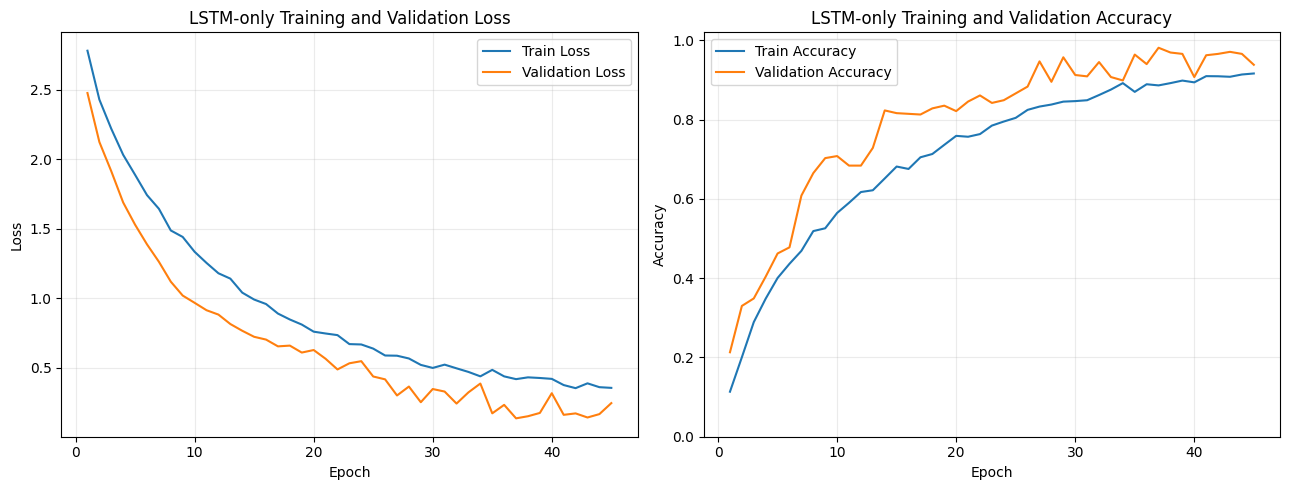


Best validation-selected LSTM model loaded.

FINAL RESULTS
Train        | Accuracy=0.9843 | Macro Precision=0.9868 | Macro Recall=0.9855 | Macro F1=0.9854 | Weighted F1=0.9843
Validation   | Accuracy=0.9811 | Macro Precision=0.9827 | Macro Recall=0.9820 | Macro F1=0.9821 | Weighted F1=0.9811
Test         | Accuracy=0.8582 | Macro Precision=0.8902 | Macro Recall=0.8602 | Macro F1=0.8530 | Weighted F1=0.8553

TEST CLASSIFICATION REPORT
                           precision    recall  f1-score   support

           Standing still     1.0000    1.0000    1.0000        94
     Sitting and relaxing     1.0000    0.5000    0.6667        94
               Lying down     1.0000    1.0000    1.0000        94
                  Walking     1.0000    1.0000    1.0000        94
          Climbing stairs     0.6053    0.9787    0.7480        47
      Waist bends forward     1.0000    0.9506    0.9747        81
Frontal elevation of arms     0.9884    1.0000    0.9942        85
            Knees bendin

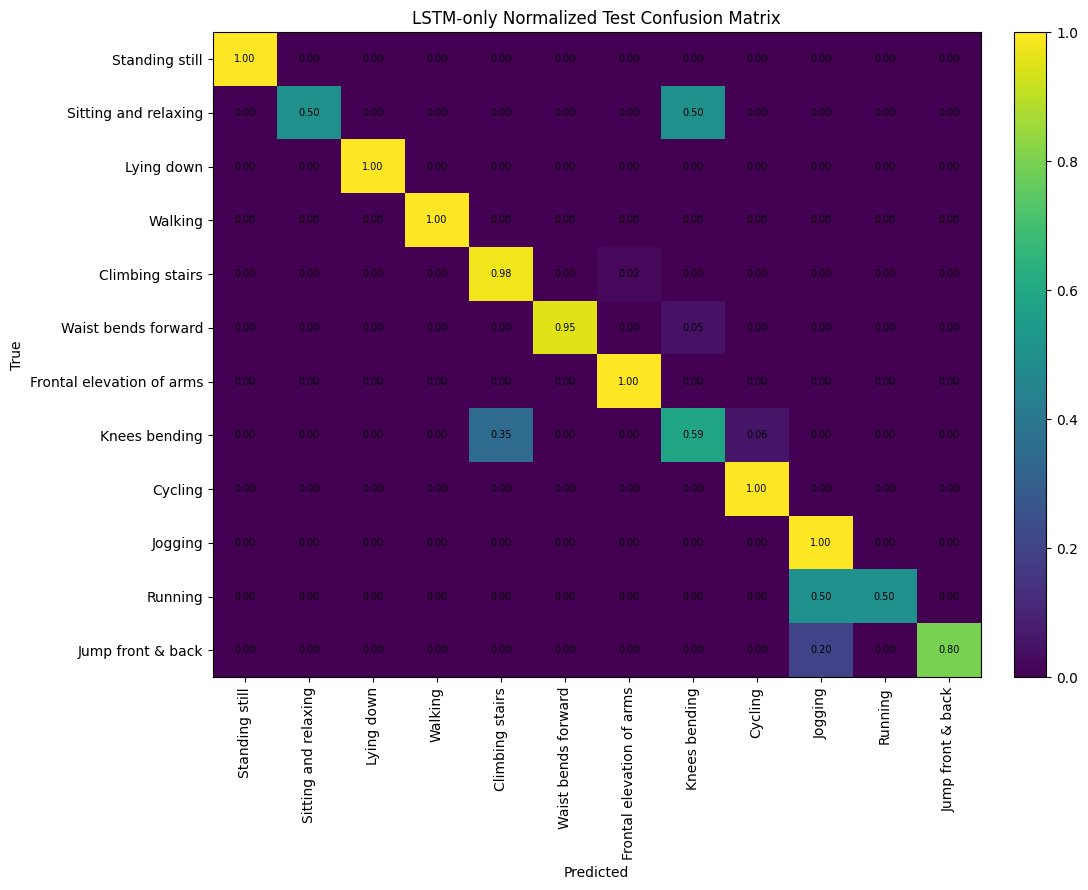


FINAL SUMMARY
Model: 12-Class LSTM-only
Parameters: 36,588

Train Accuracy      : 0.9843
Validation Accuracy : 0.9811
Test Accuracy       : 0.8582
Test Macro F1       : 0.8530
Test Weighted F1    : 0.8553

Best model saved to: mHealth_preprocessed/lstm_only_generalization_v1/best_lstm_only.keras
Training history saved to: mHealth_preprocessed/lstm_only_generalization_v1/training_history.csv
Results saved to: mHealth_preprocessed/lstm_only_generalization_v1/results.csv
Per-class metrics saved to: mHealth_preprocessed/lstm_only_generalization_v1/perclass_metrics.csv

Experiment complete.


In [8]:
# ============================================================
# mHealth DATASET
# 12-CLASS LSTM-ONLY BASELINE
# GENERALIZATION-FOCUSED / OVERFITTING-RESISTANT VERSION
#
# Input  : (128, 23)
# Output : 12 activity classes
#
# IMPORTANT:
# - No CNN
# - No Bidirectional layer
# - No attention
# - No test-set model selection
# - Best checkpoint selected ONLY by validation Macro-F1
# - Uses moderate capacity + strong regularization
# ============================================================

import os
import random
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    precision_recall_fscore_support,
)
from sklearn.utils.class_weight import compute_class_weight

from tensorflow.keras import Model
from tensorflow.keras.layers import (
    Input,
    GaussianNoise,
    SpatialDropout1D,
    LSTM,
    LayerNormalization,
    Dense,
    Dropout,
)
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import (
    Callback,
    EarlyStopping,
    ReduceLROnPlateau,
    TerminateOnNaN,
)
from tensorflow.keras.losses import SparseCategoricalCrossentropy


# ============================================================
# 1. REPRODUCIBILITY
# ============================================================

SEED = 43

os.environ["PYTHONHASHSEED"] = str(SEED)

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)


# ============================================================
# 2. DATASET CONFIGURATION
# ============================================================

DATA_DIR = "mHealth_preprocessed"

RESULTS_DIR = os.path.join(
    DATA_DIR,
    "lstm_only_generalization_v1"
)

os.makedirs(RESULTS_DIR, exist_ok=True)

NUM_CLASSES = 12
WINDOW_SIZE = 128
NUM_FEATURES = 23

ACTIVITY_NAMES = [
    "Standing still",
    "Sitting and relaxing",
    "Lying down",
    "Walking",
    "Climbing stairs",
    "Waist bends forward",
    "Frontal elevation of arms",
    "Knees bending",
    "Cycling",
    "Jogging",
    "Running",
    "Jump front & back",
]


# ============================================================
# 3. TRAINING CONFIGURATION
# ============================================================

BATCH_SIZE = 32
EPOCHS = 60

# Conservative learning rate for recurrent training
LEARNING_RATE = 2.0e-4

# AdamW regularization
WEIGHT_DECAY = 1.0e-4

# L2 regularization
L2_REG = 1.0e-4

# Input regularization
INPUT_NOISE = 0.01
INPUT_FEATURE_DROPOUT = 0.10

# LSTM regularization
LSTM_DROPOUT = 0.25

# Dense regularization
DENSE_DROPOUT = 0.40

# Training control
EARLY_STOPPING_PATIENCE = 8
LR_PATIENCE = 3
LR_FACTOR = 0.5
MIN_LR = 1e-6


# ============================================================
# 4. OUTPUT FILES
# ============================================================

MODEL_PATH = os.path.join(
    RESULTS_DIR,
    "best_lstm_only.keras"
)

RESULTS_PATH = os.path.join(
    RESULTS_DIR,
    "results.csv"
)

PERCLASS_PATH = os.path.join(
    RESULTS_DIR,
    "perclass_metrics.csv"
)

CM_RAW_PATH = os.path.join(
    RESULTS_DIR,
    "confusion_matrix_raw.csv"
)

CM_NORM_PATH = os.path.join(
    RESULTS_DIR,
    "confusion_matrix_normalized.csv"
)

HISTORY_PATH = os.path.join(
    RESULTS_DIR,
    "training_history.csv"
)

PLOT_PATH = os.path.join(
    RESULTS_DIR,
    "training_curves.png"
)

CM_PLOT_PATH = os.path.join(
    RESULTS_DIR,
    "confusion_matrix.png"
)


# ============================================================
# 5. GPU CHECK
# ============================================================

print("\n" + "=" * 75)
print("GPU CHECK")
print("=" * 75)

gpus = tf.config.list_physical_devices("GPU")

print("GPU available:", bool(gpus))

for gpu in gpus:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError:
        pass

    details = tf.config.experimental.get_device_details(gpu)

    print(
        "GPU:",
        details.get("device_name", gpu.name)
    )


# ============================================================
# 6. LOAD DATA
# ============================================================

print("\n" + "=" * 75)
print("LOADING DATA")
print("=" * 75)


def load_npz(filename):

    filepath = os.path.join(
        DATA_DIR,
        filename
    )

    if not os.path.exists(filepath):
        raise FileNotFoundError(
            f"File not found: {filepath}"
        )

    data = np.load(filepath)

    X = data["X"].astype(np.float32)
    y = data["y"].astype(np.int64)

    return X, y


X_train, y_train_raw = load_npz("train.npz")
X_val, y_val_raw = load_npz("validation.npz")
X_test, y_test_raw = load_npz("test.npz")

print("Train:", X_train.shape, y_train_raw.shape)
print("Validation:", X_val.shape, y_val_raw.shape)
print("Test:", X_test.shape, y_test_raw.shape)


# ============================================================
# 7. DATA VALIDATION
# ============================================================

def validate_dataset(name, X, y):

    assert X.ndim == 3, (
        f"{name}: X must be 3-dimensional."
    )

    assert X.shape[1] == WINDOW_SIZE, (
        f"{name}: expected {WINDOW_SIZE} time steps, "
        f"got {X.shape[1]}."
    )

    assert X.shape[2] == NUM_FEATURES, (
        f"{name}: expected {NUM_FEATURES} features, "
        f"got {X.shape[2]}."
    )

    assert len(X) == len(y), (
        f"{name}: X/y length mismatch."
    )

    assert not np.isnan(X).any(), (
        f"{name}: NaN detected."
    )

    assert not np.isinf(X).any(), (
        f"{name}: infinity detected."
    )

    assert np.all(
        (y >= 1) & (y <= NUM_CLASSES)
    ), (
        f"{name}: labels must be 1..12."
    )


validate_dataset(
    "Train",
    X_train,
    y_train_raw
)

validate_dataset(
    "Validation",
    X_val,
    y_val_raw
)

validate_dataset(
    "Test",
    X_test,
    y_test_raw
)

print("PASS: Dataset validation complete.")


# ============================================================
# 8. LABEL PREPARATION
# ============================================================

# Stored dataset labels:
#     1 ... 12
#
# Keras labels:
#     0 ... 11

y_train = y_train_raw - 1
y_val = y_val_raw - 1
y_test = y_test_raw - 1

assert np.array_equal(
    np.sort(np.unique(y_train)),
    np.arange(NUM_CLASSES)
)

assert np.array_equal(
    np.sort(np.unique(y_val)),
    np.arange(NUM_CLASSES)
)

assert np.array_equal(
    np.sort(np.unique(y_test)),
    np.arange(NUM_CLASSES)
)

print("PASS: Labels converted from 1..12 to 0..11.")


# ============================================================
# 9. TRAINING DISTRIBUTION
# ============================================================

print("\n" + "=" * 75)
print("TRAINING DISTRIBUTION")
print("=" * 75)

train_counts = (
    pd.Series(y_train)
    .value_counts()
    .sort_index()
)

for class_id in range(NUM_CLASSES):

    count = int(
        train_counts.get(
            class_id,
            0
        )
    )

    print(
        f"{class_id + 1:2d} | "
        f"{ACTIVITY_NAMES[class_id]:25s} | "
        f"{count:5d}"
    )


# ============================================================
# 10. DATA-DRIVEN CLASS WEIGHTS
#
# IMPORTANT:
# Do NOT manually force a class weight such as 1.60.
#
# Balanced weights are computed ONLY from TRAINING labels.
# Validation/test labels never influence the weights.
# ============================================================

classes = np.arange(NUM_CLASSES)

computed_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = {
    int(class_id): float(weight)
    for class_id, weight in zip(
        classes,
        computed_weights
    )
}

print("\nClass weights:")

for class_id, weight in class_weights.items():

    print(
        f"{class_id + 1:2d} | "
        f"{ACTIVITY_NAMES[class_id]:25s} | "
        f"{weight:.4f}"
    )


# ============================================================
# 11. BEST VALIDATION MACRO-F1 CHECKPOINT
# ============================================================

class BestMacroF1Checkpoint(Callback):

    def __init__(
        self,
        x_val,
        y_val,
        filepath
    ):

        super().__init__()

        self.x_val = x_val
        self.y_val = y_val
        self.filepath = filepath

        self.best = -np.inf
        self.best_epoch = -1

    def on_epoch_end(
        self,
        epoch,
        logs=None
    ):

        probabilities = self.model.predict(
            self.x_val,
            batch_size=BATCH_SIZE,
            verbose=0
        )

        predictions = np.argmax(
            probabilities,
            axis=1
        )

        score = f1_score(
            self.y_val,
            predictions,
            average="macro",
            zero_division=0
        )

        if score > self.best:

            self.best = float(score)
            self.best_epoch = epoch + 1

            self.model.save(
                self.filepath
            )

            print(
                f"\n  Saved best validation "
                f"Macro-F1: {score:.4f} "
                f"(epoch {self.best_epoch})"
            )


# ============================================================
# 12. MODEL
# ============================================================

print("\n" + "=" * 75)
print("BUILDING LSTM-ONLY MODEL")
print("=" * 75)

inputs = Input(
    shape=(
        WINDOW_SIZE,
        NUM_FEATURES
    ),
    name="sensor_input"
)


# ------------------------------------------------------------
# INPUT REGULARIZATION
# ------------------------------------------------------------

x = GaussianNoise(
    INPUT_NOISE,
    name="input_noise"
)(inputs)

x = SpatialDropout1D(
    INPUT_FEATURE_DROPOUT,
    name="input_feature_dropout"
)(x)


# ------------------------------------------------------------
# LSTM BLOCK 1
#
# Moderate size: 64 units
# return_sequences=True because another LSTM follows.
# ------------------------------------------------------------

x = LSTM(
    64,
    return_sequences=True,
    dropout=LSTM_DROPOUT,
    recurrent_dropout=0.0,
    kernel_regularizer=l2(L2_REG),
    recurrent_regularizer=l2(L2_REG),
    name="lstm_1"
)(x)

x = LayerNormalization(
    name="lstm_1_layer_norm"
)(x)


# ------------------------------------------------------------
# LSTM BLOCK 2
#
# Smaller second recurrent layer prevents the model from
# becoming unnecessarily large.
# ------------------------------------------------------------

x = LSTM(
    32,
    return_sequences=False,
    dropout=LSTM_DROPOUT,
    recurrent_dropout=0.0,
    kernel_regularizer=l2(L2_REG),
    recurrent_regularizer=l2(L2_REG),
    name="lstm_2"
)(x)

x = LayerNormalization(
    name="lstm_2_layer_norm"
)(x)


# ------------------------------------------------------------
# CLASSIFICATION HEAD
# ------------------------------------------------------------

x = Dense(
    32,
    activation="relu",
    kernel_regularizer=l2(L2_REG),
    name="dense_features"
)(x)

x = Dropout(
    DENSE_DROPOUT,
    name="classifier_dropout"
)(x)

outputs = Dense(
    NUM_CLASSES,
    activation="softmax",
    name="activity_output"
)(x)


model = Model(
    inputs=inputs,
    outputs=outputs,
    name="mHealth_LSTM_Only_12Class"
)

model.summary()

print(
    "\nTotal parameters:",
    f"{model.count_params():,}"
)


# ============================================================
# 13. OPTIMIZER
# ============================================================

print("\n" + "=" * 75)
print("COMPILING MODEL")
print("=" * 75)

try:

    optimizer = tf.keras.optimizers.AdamW(
        learning_rate=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY,
        clipnorm=1.0
    )

    print("Optimizer: AdamW")

except AttributeError:

    optimizer = tf.keras.optimizers.Adam(
        learning_rate=LEARNING_RATE,
        clipnorm=1.0
    )

    print("Optimizer: Adam")


model.compile(
    optimizer=optimizer,
    loss=SparseCategoricalCrossentropy(
        from_logits=False
    ),
    metrics=["accuracy"]
)

print("Loss: Sparse Categorical Cross-Entropy")


# ============================================================
# 14. CALLBACKS
# ============================================================

macro_checkpoint = BestMacroF1Checkpoint(
    X_val,
    y_val,
    MODEL_PATH
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=LR_FACTOR,
    patience=LR_PATIENCE,
    min_lr=MIN_LR,
    verbose=1
)

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=EARLY_STOPPING_PATIENCE,
    mode="min",
    restore_best_weights=False,
    verbose=1
)

terminate_nan = TerminateOnNaN()


# ============================================================
# 15. TRAIN
# ============================================================

print("\n" + "=" * 75)
print("TRAINING LSTM-ONLY MODEL")
print("=" * 75)

history = model.fit(

    X_train,
    y_train,

    validation_data=(
        X_val,
        y_val
    ),

    epochs=EPOCHS,
    batch_size=BATCH_SIZE,

    class_weight=class_weights,

    callbacks=[
        macro_checkpoint,
        reduce_lr,
        early_stopping,
        terminate_nan,
    ],

    shuffle=True,
    verbose=1
)


# ============================================================
# 16. SAVE TRAINING HISTORY
# ============================================================

history_df = pd.DataFrame(
    history.history
)

history_df.insert(
    0,
    "Epoch",
    np.arange(
        1,
        len(history_df) + 1
    )
)

history_df.to_csv(
    HISTORY_PATH,
    index=False
)


# ============================================================
# 17. TRAINING CURVES
# ============================================================

epochs = history_df["Epoch"]

fig, axes = plt.subplots(
    1,
    2,
    figsize=(13, 5)
)

axes[0].plot(
    epochs,
    history_df["loss"],
    label="Train Loss"
)

axes[0].plot(
    epochs,
    history_df["val_loss"],
    label="Validation Loss"
)

axes[0].set_title(
    "LSTM-only Training and Validation Loss"
)

axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")

axes[0].legend()
axes[0].grid(True, alpha=0.25)


axes[1].plot(
    epochs,
    history_df["accuracy"],
    label="Train Accuracy"
)

axes[1].plot(
    epochs,
    history_df["val_accuracy"],
    label="Validation Accuracy"
)

axes[1].set_title(
    "LSTM-only Training and Validation Accuracy"
)

axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")

axes[1].set_ylim(
    0,
    1.02
)

axes[1].legend()
axes[1].grid(True, alpha=0.25)

plt.tight_layout()

plt.savefig(
    PLOT_PATH,
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ============================================================
# 18. LOAD BEST VALIDATION MODEL
# ============================================================

if not os.path.exists(MODEL_PATH):

    raise FileNotFoundError(
        "Best validation Macro-F1 model was not saved."
    )

best_model = tf.keras.models.load_model(
    MODEL_PATH,
    compile=False
)

print(
    "\nBest validation-selected LSTM model loaded."
)


# ============================================================
# 19. EVALUATION FUNCTION
# ============================================================

def evaluate_split(
    name,
    X,
    y
):

    probabilities = best_model.predict(
        X,
        batch_size=BATCH_SIZE,
        verbose=0
    )

    predictions = np.argmax(
        probabilities,
        axis=1
    )

    metrics = {

        "Split": name,

        "Accuracy": accuracy_score(
            y,
            predictions
        ),

        "Macro_Precision": precision_score(
            y,
            predictions,
            average="macro",
            zero_division=0
        ),

        "Macro_Recall": recall_score(
            y,
            predictions,
            average="macro",
            zero_division=0
        ),

        "Macro_F1": f1_score(
            y,
            predictions,
            average="macro",
            zero_division=0
        ),

        "Weighted_F1": f1_score(
            y,
            predictions,
            average="weighted",
            zero_division=0
        )
    }

    print(
        f"{name:12s} | "
        f"Accuracy={metrics['Accuracy']:.4f} | "
        f"Macro Precision={metrics['Macro_Precision']:.4f} | "
        f"Macro Recall={metrics['Macro_Recall']:.4f} | "
        f"Macro F1={metrics['Macro_F1']:.4f} | "
        f"Weighted F1={metrics['Weighted_F1']:.4f}"
    )

    return predictions, metrics


# ============================================================
# 20. FINAL RESULTS
# ============================================================

print("\n" + "=" * 75)
print("FINAL RESULTS")
print("=" * 75)

train_predictions, train_metrics = evaluate_split(
    "Train",
    X_train,
    y_train
)

val_predictions, val_metrics = evaluate_split(
    "Validation",
    X_val,
    y_val
)

test_predictions, test_metrics = evaluate_split(
    "Test",
    X_test,
    y_test
)


# ============================================================
# 21. TEST CLASSIFICATION REPORT
# ============================================================

test_predictions_labels = test_predictions + 1

print("\n" + "=" * 75)
print("TEST CLASSIFICATION REPORT")
print("=" * 75)

print(
    classification_report(
        y_test_raw,
        test_predictions_labels,
        labels=np.arange(
            1,
            NUM_CLASSES + 1
        ),
        target_names=ACTIVITY_NAMES,
        digits=4,
        zero_division=0
    )
)


# ============================================================
# 22. PER-CLASS METRICS
# ============================================================

precision_per_class, \
recall_per_class, \
f1_per_class, \
support_per_class = (
    precision_recall_fscore_support(
        y_test_raw,
        test_predictions_labels,
        labels=np.arange(
            1,
            NUM_CLASSES + 1
        ),
        zero_division=0
    )
)

perclass_df = pd.DataFrame({

    "Activity_ID":
        np.arange(
            1,
            NUM_CLASSES + 1
        ),

    "Activity":
        ACTIVITY_NAMES,

    "Precision":
        precision_per_class,

    "Recall":
        recall_per_class,

    "F1":
        f1_per_class,

    "Support":
        support_per_class
})

perclass_df.to_csv(
    PERCLASS_PATH,
    index=False
)


# ============================================================
# 23. CONFUSION MATRIX
# ============================================================

labels = np.arange(
    1,
    NUM_CLASSES + 1
)

cm = confusion_matrix(
    y_test_raw,
    test_predictions_labels,
    labels=labels
)

with np.errstate(
    divide="ignore",
    invalid="ignore"
):

    cm_normalized = (
        cm.astype(np.float64)
        /
        cm.sum(
            axis=1,
            keepdims=True
        )
    )

cm_normalized = np.nan_to_num(
    cm_normalized
)

pd.DataFrame(
    cm,
    index=ACTIVITY_NAMES,
    columns=ACTIVITY_NAMES
).to_csv(
    CM_RAW_PATH
)

pd.DataFrame(
    cm_normalized,
    index=ACTIVITY_NAMES,
    columns=ACTIVITY_NAMES
).to_csv(
    CM_NORM_PATH
)


# ============================================================
# 24. CONFUSION MATRIX PLOT
# ============================================================

fig, ax = plt.subplots(
    figsize=(11, 9)
)

im = ax.imshow(
    cm_normalized,
    interpolation="nearest",
    aspect="auto"
)

ax.set_title(
    "LSTM-only Normalized Test Confusion Matrix"
)

ax.set_xlabel("Predicted")
ax.set_ylabel("True")

ax.set_xticks(
    range(NUM_CLASSES)
)

ax.set_yticks(
    range(NUM_CLASSES)
)

ax.set_xticklabels(
    ACTIVITY_NAMES,
    rotation=90
)

ax.set_yticklabels(
    ACTIVITY_NAMES
)

fig.colorbar(
    im,
    ax=ax,
    fraction=0.046,
    pad=0.04
)

for i in range(NUM_CLASSES):

    for j in range(NUM_CLASSES):

        ax.text(
            j,
            i,
            f"{cm_normalized[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=7
        )

plt.tight_layout()

plt.savefig(
    CM_PLOT_PATH,
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ============================================================
# 25. SAVE RESULTS
# ============================================================

results_df = pd.DataFrame([
    train_metrics,
    val_metrics,
    test_metrics
])

results_df.to_csv(
    RESULTS_PATH,
    index=False
)


# ============================================================
# 26. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 75)
print("FINAL SUMMARY")
print("=" * 75)

print(
    "Model:",
    "12-Class LSTM-only"
)

print(
    "Parameters:",
    f"{best_model.count_params():,}"
)

print()

print(
    f"Train Accuracy      : "
    f"{train_metrics['Accuracy']:.4f}"
)

print(
    f"Validation Accuracy : "
    f"{val_metrics['Accuracy']:.4f}"
)

print(
    f"Test Accuracy       : "
    f"{test_metrics['Accuracy']:.4f}"
)

print(
    f"Test Macro F1       : "
    f"{test_metrics['Macro_F1']:.4f}"
)

print(
    f"Test Weighted F1    : "
    f"{test_metrics['Weighted_F1']:.4f}"
)

print()

print(
    "Best model saved to:",
    MODEL_PATH
)

print(
    "Training history saved to:",
    HISTORY_PATH
)

print(
    "Results saved to:",
    RESULTS_PATH
)

print(
    "Per-class metrics saved to:",
    PERCLASS_PATH
)

print(
    "\nExperiment complete."
)


GPU CHECK
GPU available: True
GPU: Tesla T4
GPU: Tesla T4

LOADING DATA
Train: (3127, 128, 23) (3127,)
Validation: (582, 128, 23) (582,)
Test: (987, 128, 23) (987,)
PASS: Dataset validation complete.
PASS: Labels converted from 1..12 to 0..11.

TRAINING DISTRIBUTION
 1 | Standing still            |   282
 2 | Sitting and relaxing      |   282
 3 | Lying down                |   282
 4 | Walking                   |   282
 5 | Climbing stairs           |   284
 6 | Waist bends forward       |   253
 7 | Frontal elevation of arms |   264
 8 | Knees bending             |   262
 9 | Cycling                   |   282
10 | Jogging                   |   282
11 | Running                   |   282
12 | Jump front & back         |    90

Class weights:
 1 | Standing still            | 0.9241
 2 | Sitting and relaxing      | 0.9241
 3 | Lying down                | 0.9241
 4 | Walking                   | 0.9241
 5 | Climbing stairs           | 0.9175
 6 | Waist bends forward       | 1.0300
 7 | Fro

Model: "mHealth_BiLSTM_Only_12Class"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sensor_input (InputLayer)       │ (None, 128, 23)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ input_noise (GaussianNoise)     │ (None, 128, 23)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ input_feature_dropout           │ (None, 128, 23)        │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_lstm_1            │ (None, 128, 128)       │        45,056 │
│ (Bidirectional)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bilstm_1_layer_norm             │ (None, 128, 128)       │           256 │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_lstm_2            │ (None, 64)             │        41,216 │
│ (Bidirectional)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bilstm_2_layer_norm             │ (None, 64)             │           128 │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_features (Dense)          │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classifier_dropout (Dropout)    │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activity_output (Dense)         │ (None, 12)             │           396 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 89,132 (348.17 KB)

 Trainable params: 89,132 (348.17 KB)

 Non-trainable params: 0 (0.00 B)


Total parameters: 89,132

COMPILING MODEL
Optimizer: AdamW
Loss: Sparse Categorical Cross-Entropy

TRAINING BiLSTM-ONLY MODEL
Epoch 1/60
97/98 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.1023 - loss: 2.9624
  Saved best validation Macro-F1: 0.2183 (epoch 1)
98/98 ━━━━━━━━━━━━━━━━━━━━ 11s 51ms/step - accuracy: 0.1321 - loss: 2.8123 - val_accuracy: 0.2852 - val_loss: 2.2661 - learning_rate: 2.0000e-04
Epoch 2/60
97/98 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.2121 - loss: 2.4618
  Saved best validation Macro-F1: 0.3630 (epoch 2)
98/98 ━━━━━━━━━━━━━━━━━━━━ 3s 34ms/step - accuracy: 0.2411 - loss: 2.3506 - val_accuracy: 0.4433 - val_loss: 1.7884 - learning_rate: 2.0000e-04
Epoch 3/60
97/98 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.3322 - loss: 2.1196
  Saved best validation Macro-F1: 0.4348 (epoch 3)
98/98 ━━━━━━━━━━━━━━━━━━━━ 3s 33ms/step - accuracy: 0.3550 - loss: 2.0443 - val_accuracy: 0.5120 - val_loss: 1.5470 - learning_rate: 2.0000e-04
Epoch 4/60
97/98 ━━━━━━━━━━━━━━━

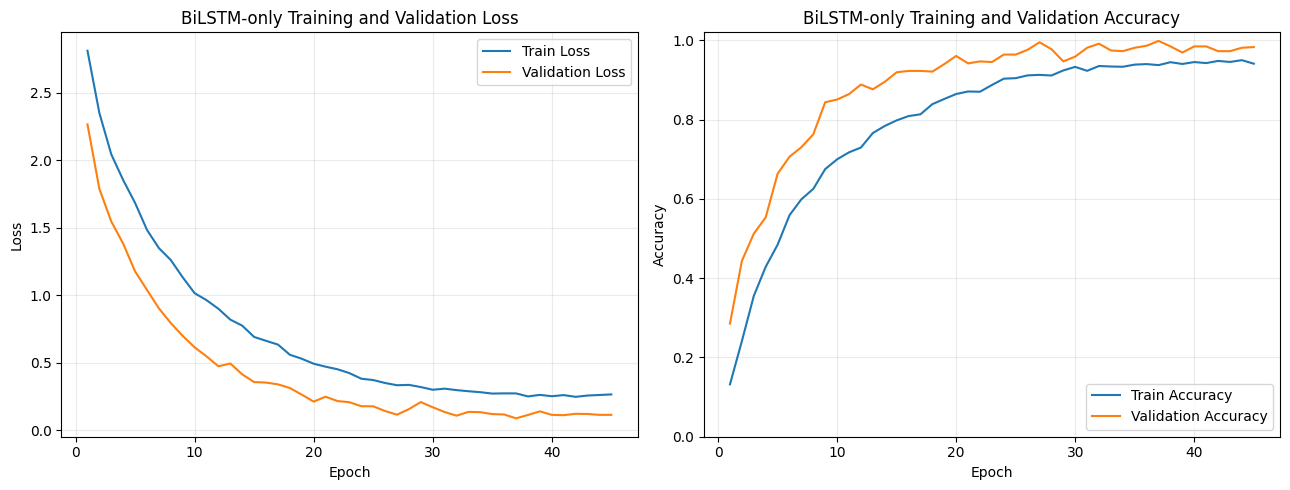


Best validation-selected LSTM model loaded.

FINAL RESULTS
Train        | Accuracy=0.9930 | Macro Precision=0.9939 | Macro Recall=0.9935 | Macro F1=0.9935 | Weighted F1=0.9930
Validation   | Accuracy=0.9983 | Macro Precision=0.9983 | Macro Recall=0.9981 | Macro F1=0.9982 | Weighted F1=0.9983
Test         | Accuracy=0.8723 | Macro Precision=0.8983 | Macro Recall=0.8794 | Macro F1=0.8685 | Weighted F1=0.8666

TEST CLASSIFICATION REPORT
                           precision    recall  f1-score   support

           Standing still     1.0000    1.0000    1.0000        94
     Sitting and relaxing     1.0000    0.5000    0.6667        94
               Lying down     1.0000    1.0000    1.0000        94
                  Walking     1.0000    1.0000    1.0000        94
          Climbing stairs     0.6479    0.9787    0.7797        47
      Waist bends forward     1.0000    1.0000    1.0000        81
Frontal elevation of arms     0.9884    1.0000    0.9942        85
            Knees bendin

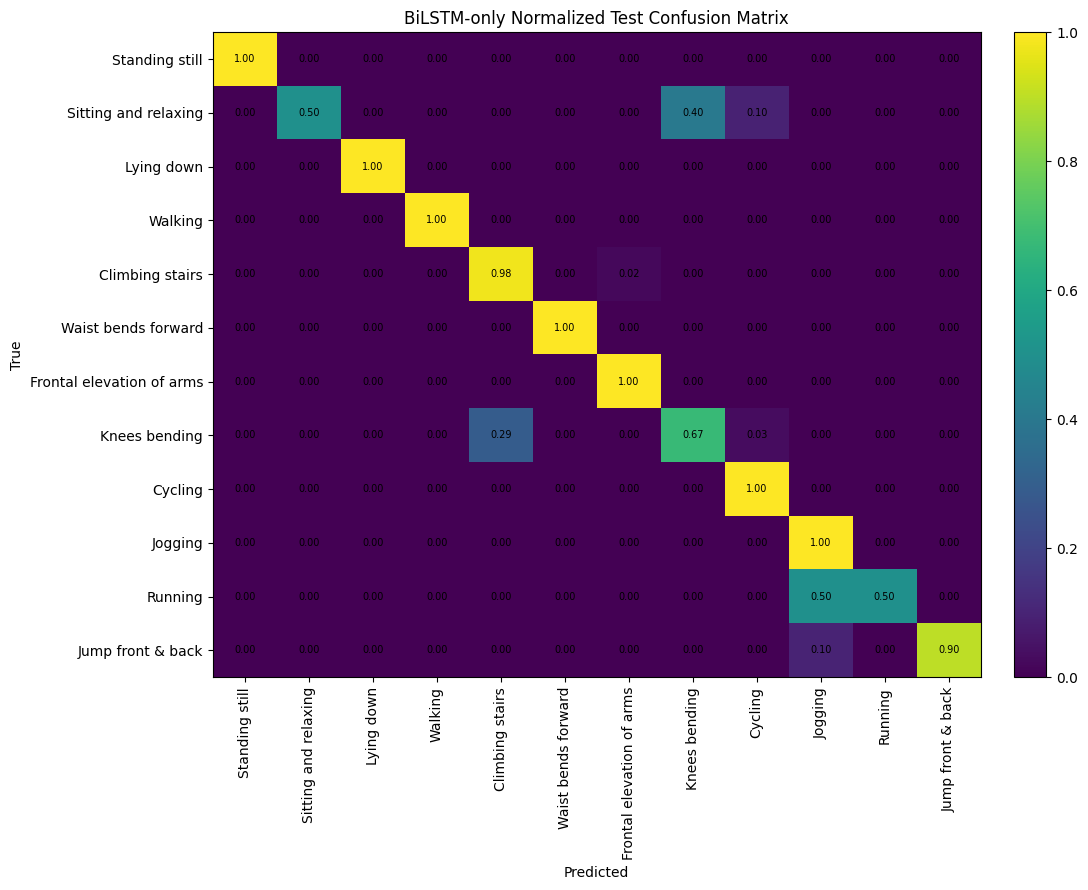


FINAL SUMMARY
Model: 12-Class BiLSTM-only
Parameters: 89,132

Train Accuracy      : 0.9930
Validation Accuracy : 0.9983
Test Accuracy       : 0.8723
Test Macro F1       : 0.8685
Test Weighted F1    : 0.8666

Best model saved to: mHealth_preprocessed/bilstm_only_generalization_v1/best_bilstm_only.keras
Training history saved to: mHealth_preprocessed/bilstm_only_generalization_v1/training_history.csv
Results saved to: mHealth_preprocessed/bilstm_only_generalization_v1/results.csv
Per-class metrics saved to: mHealth_preprocessed/bilstm_only_generalization_v1/perclass_metrics.csv

Experiment complete.


In [9]:
# ============================================================
# mHealth DATASET
# 12-CLASS BiLSTM-ONLY BASELINE
# GENERALIZATION-FOCUSED / OVERFITTING-RESISTANT VERSION
#
# Input  : (128, 23)
# Output : 12 activity classes
#
# IMPORTANT:
# - No CNN
# - BiLSTM is the ONLY sequence feature extractor
# - No attention
# - No test-set model selection
# - Best checkpoint selected ONLY by validation Macro-F1
# - Uses moderate capacity + strong regularization
# ============================================================

import os
import random
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    precision_recall_fscore_support,
)
from sklearn.utils.class_weight import compute_class_weight

from tensorflow.keras import Model
from tensorflow.keras.layers import (
    Input,
    GaussianNoise,
    SpatialDropout1D,
    LSTM,
    Bidirectional,
    LayerNormalization,
    Dense,
    Dropout,
)
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import (
    Callback,
    EarlyStopping,
    ReduceLROnPlateau,
    TerminateOnNaN,
)
from tensorflow.keras.losses import SparseCategoricalCrossentropy


# ============================================================
# 1. REPRODUCIBILITY
# ============================================================

SEED = 43

os.environ["PYTHONHASHSEED"] = str(SEED)

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)


# ============================================================
# 2. DATASET CONFIGURATION
# ============================================================

DATA_DIR = "mHealth_preprocessed"

RESULTS_DIR = os.path.join(
    DATA_DIR,
    "bilstm_only_generalization_v1"
)

os.makedirs(RESULTS_DIR, exist_ok=True)

NUM_CLASSES = 12
WINDOW_SIZE = 128
NUM_FEATURES = 23

ACTIVITY_NAMES = [
    "Standing still",
    "Sitting and relaxing",
    "Lying down",
    "Walking",
    "Climbing stairs",
    "Waist bends forward",
    "Frontal elevation of arms",
    "Knees bending",
    "Cycling",
    "Jogging",
    "Running",
    "Jump front & back",
]


# ============================================================
# 3. TRAINING CONFIGURATION
# ============================================================

BATCH_SIZE = 32
EPOCHS = 60

# Conservative learning rate for recurrent training
LEARNING_RATE = 2.0e-4

# AdamW regularization
WEIGHT_DECAY = 1.0e-4

# L2 regularization
L2_REG = 1.0e-4

# Input regularization
INPUT_NOISE = 0.01
INPUT_FEATURE_DROPOUT = 0.10

# LSTM regularization
LSTM_DROPOUT = 0.25

# Dense regularization
DENSE_DROPOUT = 0.40

# Training control
EARLY_STOPPING_PATIENCE = 8
LR_PATIENCE = 3
LR_FACTOR = 0.5
MIN_LR = 1e-6


# ============================================================
# 4. OUTPUT FILES
# ============================================================

MODEL_PATH = os.path.join(
    RESULTS_DIR,
    "best_bilstm_only.keras"
)

RESULTS_PATH = os.path.join(
    RESULTS_DIR,
    "results.csv"
)

PERCLASS_PATH = os.path.join(
    RESULTS_DIR,
    "perclass_metrics.csv"
)

CM_RAW_PATH = os.path.join(
    RESULTS_DIR,
    "confusion_matrix_raw.csv"
)

CM_NORM_PATH = os.path.join(
    RESULTS_DIR,
    "confusion_matrix_normalized.csv"
)

HISTORY_PATH = os.path.join(
    RESULTS_DIR,
    "training_history.csv"
)

PLOT_PATH = os.path.join(
    RESULTS_DIR,
    "training_curves.png"
)

CM_PLOT_PATH = os.path.join(
    RESULTS_DIR,
    "confusion_matrix.png"
)


# ============================================================
# 5. GPU CHECK
# ============================================================

print("\n" + "=" * 75)
print("GPU CHECK")
print("=" * 75)

gpus = tf.config.list_physical_devices("GPU")

print("GPU available:", bool(gpus))

for gpu in gpus:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError:
        pass

    details = tf.config.experimental.get_device_details(gpu)

    print(
        "GPU:",
        details.get("device_name", gpu.name)
    )


# ============================================================
# 6. LOAD DATA
# ============================================================

print("\n" + "=" * 75)
print("LOADING DATA")
print("=" * 75)


def load_npz(filename):

    filepath = os.path.join(
        DATA_DIR,
        filename
    )

    if not os.path.exists(filepath):
        raise FileNotFoundError(
            f"File not found: {filepath}"
        )

    data = np.load(filepath)

    X = data["X"].astype(np.float32)
    y = data["y"].astype(np.int64)

    return X, y


X_train, y_train_raw = load_npz("train.npz")
X_val, y_val_raw = load_npz("validation.npz")
X_test, y_test_raw = load_npz("test.npz")

print("Train:", X_train.shape, y_train_raw.shape)
print("Validation:", X_val.shape, y_val_raw.shape)
print("Test:", X_test.shape, y_test_raw.shape)


# ============================================================
# 7. DATA VALIDATION
# ============================================================

def validate_dataset(name, X, y):

    assert X.ndim == 3, (
        f"{name}: X must be 3-dimensional."
    )

    assert X.shape[1] == WINDOW_SIZE, (
        f"{name}: expected {WINDOW_SIZE} time steps, "
        f"got {X.shape[1]}."
    )

    assert X.shape[2] == NUM_FEATURES, (
        f"{name}: expected {NUM_FEATURES} features, "
        f"got {X.shape[2]}."
    )

    assert len(X) == len(y), (
        f"{name}: X/y length mismatch."
    )

    assert not np.isnan(X).any(), (
        f"{name}: NaN detected."
    )

    assert not np.isinf(X).any(), (
        f"{name}: infinity detected."
    )

    assert np.all(
        (y >= 1) & (y <= NUM_CLASSES)
    ), (
        f"{name}: labels must be 1..12."
    )


validate_dataset(
    "Train",
    X_train,
    y_train_raw
)

validate_dataset(
    "Validation",
    X_val,
    y_val_raw
)

validate_dataset(
    "Test",
    X_test,
    y_test_raw
)

print("PASS: Dataset validation complete.")


# ============================================================
# 8. LABEL PREPARATION
# ============================================================

# Stored dataset labels:
#     1 ... 12
#
# Keras labels:
#     0 ... 11

y_train = y_train_raw - 1
y_val = y_val_raw - 1
y_test = y_test_raw - 1

assert np.array_equal(
    np.sort(np.unique(y_train)),
    np.arange(NUM_CLASSES)
)

assert np.array_equal(
    np.sort(np.unique(y_val)),
    np.arange(NUM_CLASSES)
)

assert np.array_equal(
    np.sort(np.unique(y_test)),
    np.arange(NUM_CLASSES)
)

print("PASS: Labels converted from 1..12 to 0..11.")


# ============================================================
# 9. TRAINING DISTRIBUTION
# ============================================================

print("\n" + "=" * 75)
print("TRAINING DISTRIBUTION")
print("=" * 75)

train_counts = (
    pd.Series(y_train)
    .value_counts()
    .sort_index()
)

for class_id in range(NUM_CLASSES):

    count = int(
        train_counts.get(
            class_id,
            0
        )
    )

    print(
        f"{class_id + 1:2d} | "
        f"{ACTIVITY_NAMES[class_id]:25s} | "
        f"{count:5d}"
    )


# ============================================================
# 10. DATA-DRIVEN CLASS WEIGHTS
#
# IMPORTANT:
# Do NOT manually force a class weight such as 1.60.
#
# Balanced weights are computed ONLY from TRAINING labels.
# Validation/test labels never influence the weights.
# ============================================================

classes = np.arange(NUM_CLASSES)

computed_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = {
    int(class_id): float(weight)
    for class_id, weight in zip(
        classes,
        computed_weights
    )
}

print("\nClass weights:")

for class_id, weight in class_weights.items():

    print(
        f"{class_id + 1:2d} | "
        f"{ACTIVITY_NAMES[class_id]:25s} | "
        f"{weight:.4f}"
    )


# ============================================================
# 11. BEST VALIDATION MACRO-F1 CHECKPOINT
# ============================================================

class BestMacroF1Checkpoint(Callback):

    def __init__(
        self,
        x_val,
        y_val,
        filepath
    ):

        super().__init__()

        self.x_val = x_val
        self.y_val = y_val
        self.filepath = filepath

        self.best = -np.inf
        self.best_epoch = -1

    def on_epoch_end(
        self,
        epoch,
        logs=None
    ):

        probabilities = self.model.predict(
            self.x_val,
            batch_size=BATCH_SIZE,
            verbose=0
        )

        predictions = np.argmax(
            probabilities,
            axis=1
        )

        score = f1_score(
            self.y_val,
            predictions,
            average="macro",
            zero_division=0
        )

        if score > self.best:

            self.best = float(score)
            self.best_epoch = epoch + 1

            self.model.save(
                self.filepath
            )

            print(
                f"\n  Saved best validation "
                f"Macro-F1: {score:.4f} "
                f"(epoch {self.best_epoch})"
            )


# ============================================================
# ============================================================
# 12. BiLSTM-ONLY MODEL
# ============================================================

print("\n" + "=" * 75)
print("BUILDING BiLSTM-ONLY MODEL")
print("=" * 75)

inputs = Input(
    shape=(
        WINDOW_SIZE,
        NUM_FEATURES
    ),
    name="sensor_input"
)


# ------------------------------------------------------------
# INPUT REGULARIZATION
# ------------------------------------------------------------

x = GaussianNoise(
    INPUT_NOISE,
    name="input_noise"
)(inputs)

x = SpatialDropout1D(
    INPUT_FEATURE_DROPOUT,
    name="input_feature_dropout"
)(x)


# ------------------------------------------------------------
# BiLSTM BLOCK 1
#
# 64 units in each direction.
# Output dimension = 128.
# ------------------------------------------------------------

x = Bidirectional(
    LSTM(
        64,
        return_sequences=True,
        dropout=LSTM_DROPOUT,
        recurrent_dropout=0.0,
        kernel_regularizer=l2(L2_REG),
        recurrent_regularizer=l2(L2_REG),
        name="bilstm_1"
    ),
    name="bidirectional_lstm_1"
)(x)

x = LayerNormalization(
    name="bilstm_1_layer_norm"
)(x)


# ------------------------------------------------------------
# BiLSTM BLOCK 2
#
# 32 units in each direction.
# Output dimension = 64.
# ------------------------------------------------------------

x = Bidirectional(
    LSTM(
        32,
        return_sequences=False,
        dropout=LSTM_DROPOUT,
        recurrent_dropout=0.0,
        kernel_regularizer=l2(L2_REG),
        recurrent_regularizer=l2(L2_REG),
        name="bilstm_2"
    ),
    name="bidirectional_lstm_2"
)(x)

x = LayerNormalization(
    name="bilstm_2_layer_norm"
)(x)


# ------------------------------------------------------------
# CLASSIFICATION HEAD
# ------------------------------------------------------------

x = Dense(
    32,
    activation="relu",
    kernel_regularizer=l2(L2_REG),
    name="dense_features"
)(x)

x = Dropout(
    DENSE_DROPOUT,
    name="classifier_dropout"
)(x)

outputs = Dense(
    NUM_CLASSES,
    activation="softmax",
    name="activity_output"
)(x)

model = Model(
    inputs=inputs,
    outputs=outputs,
    name="mHealth_BiLSTM_Only_12Class"
)

model.summary()

print(
    "\nTotal parameters:",
    f"{model.count_params():,}"
)


# 13. OPTIMIZER
# ============================================================

print("\n" + "=" * 75)
print("COMPILING MODEL")
print("=" * 75)

try:

    optimizer = tf.keras.optimizers.AdamW(
        learning_rate=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY,
        clipnorm=1.0
    )

    print("Optimizer: AdamW")

except AttributeError:

    optimizer = tf.keras.optimizers.Adam(
        learning_rate=LEARNING_RATE,
        clipnorm=1.0
    )

    print("Optimizer: Adam")


model.compile(
    optimizer=optimizer,
    loss=SparseCategoricalCrossentropy(
        from_logits=False
    ),
    metrics=["accuracy"]
)

print("Loss: Sparse Categorical Cross-Entropy")


# ============================================================
# 14. CALLBACKS
# ============================================================

macro_checkpoint = BestMacroF1Checkpoint(
    X_val,
    y_val,
    MODEL_PATH
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=LR_FACTOR,
    patience=LR_PATIENCE,
    min_lr=MIN_LR,
    verbose=1
)

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=EARLY_STOPPING_PATIENCE,
    mode="min",
    restore_best_weights=False,
    verbose=1
)

terminate_nan = TerminateOnNaN()


# ============================================================
# 15. TRAIN
# ============================================================

print("\n" + "=" * 75)
print("TRAINING BiLSTM-ONLY MODEL")
print("=" * 75)

history = model.fit(

    X_train,
    y_train,

    validation_data=(
        X_val,
        y_val
    ),

    epochs=EPOCHS,
    batch_size=BATCH_SIZE,

    class_weight=class_weights,

    callbacks=[
        macro_checkpoint,
        reduce_lr,
        early_stopping,
        terminate_nan,
    ],

    shuffle=True,
    verbose=1
)


# ============================================================
# 16. SAVE TRAINING HISTORY
# ============================================================

history_df = pd.DataFrame(
    history.history
)

history_df.insert(
    0,
    "Epoch",
    np.arange(
        1,
        len(history_df) + 1
    )
)

history_df.to_csv(
    HISTORY_PATH,
    index=False
)


# ============================================================
# 17. TRAINING CURVES
# ============================================================

epochs = history_df["Epoch"]

fig, axes = plt.subplots(
    1,
    2,
    figsize=(13, 5)
)

axes[0].plot(
    epochs,
    history_df["loss"],
    label="Train Loss"
)

axes[0].plot(
    epochs,
    history_df["val_loss"],
    label="Validation Loss"
)

axes[0].set_title(
    "BiLSTM-only Training and Validation Loss"
)

axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")

axes[0].legend()
axes[0].grid(True, alpha=0.25)


axes[1].plot(
    epochs,
    history_df["accuracy"],
    label="Train Accuracy"
)

axes[1].plot(
    epochs,
    history_df["val_accuracy"],
    label="Validation Accuracy"
)

axes[1].set_title(
    "BiLSTM-only Training and Validation Accuracy"
)

axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")

axes[1].set_ylim(
    0,
    1.02
)

axes[1].legend()
axes[1].grid(True, alpha=0.25)

plt.tight_layout()

plt.savefig(
    PLOT_PATH,
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ============================================================
# 18. LOAD BEST VALIDATION MODEL
# ============================================================

if not os.path.exists(MODEL_PATH):

    raise FileNotFoundError(
        "Best validation Macro-F1 model was not saved."
    )

best_model = tf.keras.models.load_model(
    MODEL_PATH,
    compile=False
)

print(
    "\nBest validation-selected LSTM model loaded."
)


# ============================================================
# 19. EVALUATION FUNCTION
# ============================================================

def evaluate_split(
    name,
    X,
    y
):

    probabilities = best_model.predict(
        X,
        batch_size=BATCH_SIZE,
        verbose=0
    )

    predictions = np.argmax(
        probabilities,
        axis=1
    )

    metrics = {

        "Split": name,

        "Accuracy": accuracy_score(
            y,
            predictions
        ),

        "Macro_Precision": precision_score(
            y,
            predictions,
            average="macro",
            zero_division=0
        ),

        "Macro_Recall": recall_score(
            y,
            predictions,
            average="macro",
            zero_division=0
        ),

        "Macro_F1": f1_score(
            y,
            predictions,
            average="macro",
            zero_division=0
        ),

        "Weighted_F1": f1_score(
            y,
            predictions,
            average="weighted",
            zero_division=0
        )
    }

    print(
        f"{name:12s} | "
        f"Accuracy={metrics['Accuracy']:.4f} | "
        f"Macro Precision={metrics['Macro_Precision']:.4f} | "
        f"Macro Recall={metrics['Macro_Recall']:.4f} | "
        f"Macro F1={metrics['Macro_F1']:.4f} | "
        f"Weighted F1={metrics['Weighted_F1']:.4f}"
    )

    return predictions, metrics


# ============================================================
# 20. FINAL RESULTS
# ============================================================

print("\n" + "=" * 75)
print("FINAL RESULTS")
print("=" * 75)

train_predictions, train_metrics = evaluate_split(
    "Train",
    X_train,
    y_train
)

val_predictions, val_metrics = evaluate_split(
    "Validation",
    X_val,
    y_val
)

test_predictions, test_metrics = evaluate_split(
    "Test",
    X_test,
    y_test
)


# ============================================================
# 21. TEST CLASSIFICATION REPORT
# ============================================================

test_predictions_labels = test_predictions + 1

print("\n" + "=" * 75)
print("TEST CLASSIFICATION REPORT")
print("=" * 75)

print(
    classification_report(
        y_test_raw,
        test_predictions_labels,
        labels=np.arange(
            1,
            NUM_CLASSES + 1
        ),
        target_names=ACTIVITY_NAMES,
        digits=4,
        zero_division=0
    )
)


# ============================================================
# 22. PER-CLASS METRICS
# ============================================================

precision_per_class, \
recall_per_class, \
f1_per_class, \
support_per_class = (
    precision_recall_fscore_support(
        y_test_raw,
        test_predictions_labels,
        labels=np.arange(
            1,
            NUM_CLASSES + 1
        ),
        zero_division=0
    )
)

perclass_df = pd.DataFrame({

    "Activity_ID":
        np.arange(
            1,
            NUM_CLASSES + 1
        ),

    "Activity":
        ACTIVITY_NAMES,

    "Precision":
        precision_per_class,

    "Recall":
        recall_per_class,

    "F1":
        f1_per_class,

    "Support":
        support_per_class
})

perclass_df.to_csv(
    PERCLASS_PATH,
    index=False
)


# ============================================================
# 23. CONFUSION MATRIX
# ============================================================

labels = np.arange(
    1,
    NUM_CLASSES + 1
)

cm = confusion_matrix(
    y_test_raw,
    test_predictions_labels,
    labels=labels
)

with np.errstate(
    divide="ignore",
    invalid="ignore"
):

    cm_normalized = (
        cm.astype(np.float64)
        /
        cm.sum(
            axis=1,
            keepdims=True
        )
    )

cm_normalized = np.nan_to_num(
    cm_normalized
)

pd.DataFrame(
    cm,
    index=ACTIVITY_NAMES,
    columns=ACTIVITY_NAMES
).to_csv(
    CM_RAW_PATH
)

pd.DataFrame(
    cm_normalized,
    index=ACTIVITY_NAMES,
    columns=ACTIVITY_NAMES
).to_csv(
    CM_NORM_PATH
)


# ============================================================
# 24. CONFUSION MATRIX PLOT
# ============================================================

fig, ax = plt.subplots(
    figsize=(11, 9)
)

im = ax.imshow(
    cm_normalized,
    interpolation="nearest",
    aspect="auto"
)

ax.set_title(
    "BiLSTM-only Normalized Test Confusion Matrix"
)

ax.set_xlabel("Predicted")
ax.set_ylabel("True")

ax.set_xticks(
    range(NUM_CLASSES)
)

ax.set_yticks(
    range(NUM_CLASSES)
)

ax.set_xticklabels(
    ACTIVITY_NAMES,
    rotation=90
)

ax.set_yticklabels(
    ACTIVITY_NAMES
)

fig.colorbar(
    im,
    ax=ax,
    fraction=0.046,
    pad=0.04
)

for i in range(NUM_CLASSES):

    for j in range(NUM_CLASSES):

        ax.text(
            j,
            i,
            f"{cm_normalized[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=7
        )

plt.tight_layout()

plt.savefig(
    CM_PLOT_PATH,
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ============================================================
# 25. SAVE RESULTS
# ============================================================

results_df = pd.DataFrame([
    train_metrics,
    val_metrics,
    test_metrics
])

results_df.to_csv(
    RESULTS_PATH,
    index=False
)


# ============================================================
# 26. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 75)
print("FINAL SUMMARY")
print("=" * 75)

print(
    "Model:",
    "12-Class BiLSTM-only"
)

print(
    "Parameters:",
    f"{best_model.count_params():,}"
)

print()

print(
    f"Train Accuracy      : "
    f"{train_metrics['Accuracy']:.4f}"
)

print(
    f"Validation Accuracy : "
    f"{val_metrics['Accuracy']:.4f}"
)

print(
    f"Test Accuracy       : "
    f"{test_metrics['Accuracy']:.4f}"
)

print(
    f"Test Macro F1       : "
    f"{test_metrics['Macro_F1']:.4f}"
)

print(
    f"Test Weighted F1    : "
    f"{test_metrics['Weighted_F1']:.4f}"
)

print()

print(
    "Best model saved to:",
    MODEL_PATH
)

print(
    "Training history saved to:",
    HISTORY_PATH
)

print(
    "Results saved to:",
    RESULTS_PATH
)

print(
    "Per-class metrics saved to:",
    PERCLASS_PATH
)

print(
    "\nExperiment complete."
)

In [ ]:
# ============================================================
# mHealth - 11 Class LSTM Only
# Activity 2 removed
# Same BiLSTM used in CNN + BiLSTM model
# No per-epoch graphs; all epoch data saved/displayed
# ============================================================

import os
import random
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from IPython.display import display

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    precision_recall_fscore_support
)

from tensorflow.keras import Model
from tensorflow.keras.layers import (
    Input,
    GaussianNoise,
    SpatialDropout1D,
    LSTM,
    Bidirectional,
    Dense,
    Dropout
)
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import (
    Callback,
    EarlyStopping,
    ReduceLROnPlateau,
    TerminateOnNaN
)
from tensorflow.keras.losses import SparseCategoricalCrossentropy


# ============================================================
# CONFIG
# ============================================================

SEED = 43

DATA_DIR = "mHealth_preprocessed"
RESULTS_DIR = os.path.join(
    DATA_DIR,
    "lstm_only_11class"
)

os.makedirs(RESULTS_DIR, exist_ok=True)

WINDOW_SIZE = 128
NUM_FEATURES = 23
NUM_CLASSES = 11
REMOVED_ACTIVITY = 2

BATCH_SIZE = 32
EPOCHS = 15

LEARNING_RATE = 2.5e-4
WEIGHT_DECAY = 1e-4
L2_REG = 1.5e-4

INPUT_NOISE = 0.015
INPUT_FEATURE_DROPOUT = 0.10

LSTM_DROPOUT = 0.25
DENSE_DROPOUT = 0.35

EARLY_STOPPING_PATIENCE = 7
LR_PATIENCE = 2
LR_FACTOR = 0.5
MIN_LR = 1e-6

CLASS_WEIGHTS = {
    0: 1.00,
    1: 1.00,
    2: 1.00,
    3: 1.00,
    4: 1.00,
    5: 1.00,
    6: 1.00,
    7: 1.00,
    8: 1.00,
    9: 1.00,
    10: 1.60
}

ACTIVITY_NAMES = [
    "Standing still",
    "Lying down",
    "Walking",
    "Climbing stairs",
    "Waist bends forward",
    "Frontal elevation of arms",
    "Knees bending",
    "Cycling",
    "Jogging",
    "Running",
    "Jump front & back"
]

MODEL_PATH = os.path.join(
    RESULTS_DIR,
    "best_lstm_only_11class.keras"
)

RESULTS_PATH = os.path.join(
    RESULTS_DIR,
    "results.csv"
)

PERCLASS_PATH = os.path.join(
    RESULTS_DIR,
    "perclass_metrics.csv"
)

CM_PATH = os.path.join(
    RESULTS_DIR,
    "confusion_matrix.csv"
)

CM_NORM_PATH = os.path.join(
    RESULTS_DIR,
    "confusion_matrix_normalized.csv"
)

HISTORY_PATH = os.path.join(
    RESULTS_DIR,
    "training_history.csv"
)


# ============================================================
# REPRODUCIBILITY
# ============================================================

os.environ["PYTHONHASHSEED"] = str(SEED)

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)


# ============================================================
# GPU
# ============================================================

gpus = tf.config.list_physical_devices("GPU")

print("GPU available:", bool(gpus))

for gpu in gpus:

    try:
        tf.config.experimental.set_memory_growth(
            gpu,
            True
        )
    except RuntimeError:
        pass

    details = tf.config.experimental.get_device_details(gpu)

    print(
        "GPU:",
        details.get(
            "device_name",
            gpu.name
        )
    )


# ============================================================
# LOAD DATA
# ============================================================

def load_npz(filename):

    path = os.path.join(
        DATA_DIR,
        filename
    )

    if not os.path.exists(path):
        raise FileNotFoundError(path)

    data = np.load(path)

    return (
        data["X"].astype(np.float32),
        data["y"].astype(np.int64)
    )


X_train_raw, y_train_raw = load_npz("train.npz")
X_val_raw, y_val_raw = load_npz("validation.npz")
X_test_raw, y_test_raw = load_npz("test.npz")

print(
    "Original train:",
    X_train_raw.shape,
    y_train_raw.shape
)

print(
    "Original validation:",
    X_val_raw.shape,
    y_val_raw.shape
)

print(
    "Original test:",
    X_test_raw.shape,
    y_test_raw.shape
)


# ============================================================
# REMOVE ACTIVITY 2
# ============================================================

def remove_activity_2(X, y):

    mask = y != REMOVED_ACTIVITY

    return X[mask], y[mask]


X_train, y_train_original = remove_activity_2(
    X_train_raw,
    y_train_raw
)

X_val, y_val_original = remove_activity_2(
    X_val_raw,
    y_val_raw
)

X_test, y_test_original = remove_activity_2(
    X_test_raw,
    y_test_raw
)

print(
    "Train after removal:",
    X_train.shape
)

print(
    "Validation after removal:",
    X_val.shape
)

print(
    "Test after removal:",
    X_test.shape
)

assert REMOVED_ACTIVITY not in y_train_original
assert REMOVED_ACTIVITY not in y_val_original
assert REMOVED_ACTIVITY not in y_test_original


# ============================================================
# REMAP 1..12 -> 1..11
# ============================================================

def remap_labels(y):

    y_new = np.where(
        y > REMOVED_ACTIVITY,
        y - 1,
        y
    ).astype(np.int64)

    assert np.all(
        (y_new >= 1) &
        (y_new <= NUM_CLASSES)
    )

    return y_new


y_train = remap_labels(
    y_train_original
)

y_val = remap_labels(
    y_val_original
)

y_test = remap_labels(
    y_test_original
)

expected = np.arange(
    1,
    NUM_CLASSES + 1
)

assert np.array_equal(
    np.sort(np.unique(y_train)),
    expected
)

assert np.array_equal(
    np.sort(np.unique(y_val)),
    expected
)

assert np.array_equal(
    np.sort(np.unique(y_test)),
    expected
)

y_train_model = y_train - 1
y_val_model = y_val - 1
y_test_model = y_test - 1


# ============================================================
# EPOCH METRICS
# No graph during training
# ============================================================

class EpochMetrics(Callback):

    def __init__(self, x_val, y_val):

        super().__init__()

        self.x_val = x_val
        self.y_val = y_val
        self.val_macro_f1 = []

    def on_epoch_end(
        self,
        epoch,
        logs=None
    ):

        probs = self.model.predict(
            self.x_val,
            batch_size=BATCH_SIZE,
            verbose=0
        )

        preds = np.argmax(
            probs,
            axis=1
        )

        macro_f1 = f1_score(
            self.y_val,
            preds,
            average="macro",
            zero_division=0
        )

        self.val_macro_f1.append(
            float(macro_f1)
        )


# ============================================================
# BEST VALIDATION MACRO-F1 CHECKPOINT
# ============================================================

class BestMacroF1Checkpoint(Callback):

    def __init__(
        self,
        x_val,
        y_val,
        filepath
    ):

        super().__init__()

        self.x_val = x_val
        self.y_val = y_val
        self.filepath = filepath

        self.best = -np.inf
        self.best_epoch = -1

    def on_epoch_end(
        self,
        epoch,
        logs=None
    ):

        probs = self.model.predict(
            self.x_val,
            batch_size=BATCH_SIZE,
            verbose=0
        )

        preds = np.argmax(
            probs,
            axis=1
        )

        score = f1_score(
            self.y_val,
            preds,
            average="macro",
            zero_division=0
        )

        if score > self.best:

            self.best = float(score)
            self.best_epoch = epoch + 1

            self.model.save(
                self.filepath
            )

            print(
                f"\nBest validation Macro-F1: "
                f"{score:.4f} | Epoch "
                f"{self.best_epoch}"
            )


# ============================================================
# LSTM ONLY MODEL
#
# Same LSTM as CNN + BiLSTM:
# Bidirectional(
#     LSTM(
#         32,
#         return_sequences=False,
#         dropout=0.25,
#         recurrent_dropout=0.0,
#         kernel_regularizer=l2(1.5e-4),
#         recurrent_regularizer=l2(1.5e-4)
#     )
# )
# ============================================================

inputs = Input(
    shape=(
        WINDOW_SIZE,
        NUM_FEATURES
    ),
    name="sensor_input"
)

x = GaussianNoise(
    INPUT_NOISE,
    name="input_noise"
)(inputs)

x = SpatialDropout1D(
    INPUT_FEATURE_DROPOUT,
    name="input_feature_dropout"
)(x)

x = Bidirectional(
    LSTM(
        32,
        return_sequences=False,
        dropout=LSTM_DROPOUT,
        recurrent_dropout=0.0,
        kernel_regularizer=l2(L2_REG),
        recurrent_regularizer=l2(L2_REG),
        name="temporal_lstm"
    ),
    name="bidirectional_lstm"
)(x)

x = Dense(
    48,
    activation="relu",
    kernel_regularizer=l2(L2_REG),
    name="dense_features"
)(x)

x = Dropout(
    DENSE_DROPOUT,
    name="classifier_dropout"
)(x)

outputs = Dense(
    NUM_CLASSES,
    activation="softmax",
    name="activity_output"
)(x)

model = Model(
    inputs=inputs,
    outputs=outputs,
    name="mHealth_LSTM_Only_11Class"
)

model.summary()

print(
    "Parameters:",
    f"{model.count_params():,}"
)


# ============================================================
# COMPILE
# ============================================================

try:

    optimizer = tf.keras.optimizers.AdamW(
        learning_rate=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY,
        clipnorm=1.0
    )

except AttributeError:

    optimizer = tf.keras.optimizers.Adam(
        learning_rate=LEARNING_RATE,
        clipnorm=1.0
    )

loss_fn = SparseCategoricalCrossentropy(
    from_logits=False
)

model.compile(
    optimizer=optimizer,
    loss=loss_fn,
    metrics=["accuracy"]
)


# ============================================================
# CALLBACKS
# ============================================================

epoch_metrics = EpochMetrics(
    X_val,
    y_val_model
)

checkpoint = BestMacroF1Checkpoint(
    X_val,
    y_val_model,
    MODEL_PATH
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=LR_FACTOR,
    patience=LR_PATIENCE,
    min_lr=MIN_LR,
    verbose=1
)

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=EARLY_STOPPING_PATIENCE,
    mode="min",
    restore_best_weights=False,
    verbose=1
)

terminate_nan = TerminateOnNaN()


# ============================================================
# TRAIN
# ============================================================

history = model.fit(
    X_train,
    y_train_model,
    validation_data=(
        X_val,
        y_val_model
    ),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    class_weight=CLASS_WEIGHTS,
    callbacks=[
        epoch_metrics,
        checkpoint,
        reduce_lr,
        early_stopping,
        terminate_nan
    ],
    shuffle=True,
    verbose=1
)


# ============================================================
# FINAL TRAINING GRAPH
# Only plotted once after training
# ============================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(13, 5)
)

epochs = np.arange(
    1,
    len(history.history["loss"]) + 1
)

axes[0].plot(
    epochs,
    history.history["loss"],
    label="Train Loss"
)

axes[0].plot(
    epochs,
    history.history["val_loss"],
    label="Validation Loss"
)

axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(
    True,
    alpha=0.25
)

axes[1].plot(
    epochs,
    history.history["accuracy"],
    label="Train Accuracy"
)

axes[1].plot(
    epochs,
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

axes[1].plot(
    epochs,
    epoch_metrics.val_macro_f1,
    label="Validation Macro-F1"
)

axes[1].set_title(
    "Accuracy / Validation Macro-F1"
)

axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Score")
axes[1].set_ylim(
    0,
    1.02
)

axes[1].legend()
axes[1].grid(
    True,
    alpha=0.25
)

plt.tight_layout()
plt.show()
plt.close(fig)


# ============================================================
# ALL EPOCH DATA
# ============================================================

epoch_df = pd.DataFrame({
    "Epoch": epochs,
    "Train_Loss": history.history["loss"],
    "Validation_Loss": history.history["val_loss"],
    "Train_Accuracy": history.history["accuracy"],
    "Validation_Accuracy": history.history["val_accuracy"],
    "Validation_Macro_F1": epoch_metrics.val_macro_f1
})

print(
    "\nALL EPOCH RESULTS"
)

display(
    epoch_df.round(4)
)

epoch_df.to_csv(
    HISTORY_PATH,
    index=False
)


# ============================================================
# LOAD BEST MODEL
# ============================================================

if not os.path.exists(
    MODEL_PATH
):

    raise FileNotFoundError(
        "Best model was not saved."
    )

best_model = tf.keras.models.load_model(
    MODEL_PATH,
    compile=False
)

print(
    "\nBest validation Macro-F1:",
    f"{checkpoint.best:.4f}"
)

print(
    "Best epoch:",
    checkpoint.best_epoch
)


# ============================================================
# EVALUATION
# ============================================================

def evaluate_split(
    name,
    X,
    y
):

    probs = best_model.predict(
        X,
        batch_size=BATCH_SIZE,
        verbose=0
    )

    preds = np.argmax(
        probs,
        axis=1
    )

    metrics = {
        "Split": name,

        "Accuracy": accuracy_score(
            y,
            preds
        ),

        "Macro_Precision": precision_score(
            y,
            preds,
            average="macro",
            zero_division=0
        ),

        "Macro_Recall": recall_score(
            y,
            preds,
            average="macro",
            zero_division=0
        ),

        "Macro_F1": f1_score(
            y,
            preds,
            average="macro",
            zero_division=0
        ),

        "Weighted_F1": f1_score(
            y,
            preds,
            average="weighted",
            zero_division=0
        )
    }

    print(
        f"{name:10s} | "
        f"Accuracy={metrics['Accuracy']:.4f} | "
        f"Macro Precision={metrics['Macro_Precision']:.4f} | "
        f"Macro Recall={metrics['Macro_Recall']:.4f} | "
        f"Macro F1={metrics['Macro_F1']:.4f} | "
        f"Weighted F1={metrics['Weighted_F1']:.4f}"
    )

    return (
        probs,
        preds,
        metrics
    )


print(
    "\nFINAL RESULTS"
)

train_probs, train_preds, train_metrics = evaluate_split(
    "Train",
    X_train,
    y_train_model
)

val_probs, val_preds, val_metrics = evaluate_split(
    "Validation",
    X_val,
    y_val_model
)

test_probs, test_preds, test_metrics = evaluate_split(
    "Test",
    X_test,
    y_test_model
)


# ============================================================
# TEST CLASSIFICATION REPORT
# ============================================================

y_pred_labels = test_preds + 1

print(
    "\nTEST CLASSIFICATION REPORT\n"
)

print(
    classification_report(
        y_test,
        y_pred_labels,
        labels=np.arange(
            1,
            NUM_CLASSES + 1
        ),
        target_names=ACTIVITY_NAMES,
        digits=4,
        zero_division=0
    )
)


# ============================================================
# PER-CLASS METRICS
# ============================================================

precision, recall, f1, support = (
    precision_recall_fscore_support(
        y_test,
        y_pred_labels,
        labels=np.arange(
            1,
            NUM_CLASSES + 1
        ),
        zero_division=0
    )
)

perclass_df = pd.DataFrame({
    "Activity_ID": np.arange(
        1,
        NUM_CLASSES + 1
    ),

    "Activity": ACTIVITY_NAMES,

    "Precision": precision,

    "Recall": recall,

    "F1": f1,

    "Support": support
})

perclass_df.to_csv(
    PERCLASS_PATH,
    index=False
)


# ============================================================
# CONFUSION MATRIX
# ============================================================

labels = np.arange(
    1,
    NUM_CLASSES + 1
)

cm = confusion_matrix(
    y_test,
    y_pred_labels,
    labels=labels
)

with np.errstate(
    divide="ignore",
    invalid="ignore"
):

    cm_normalized = (
        cm.astype(np.float64)
        /
        cm.sum(
            axis=1,
            keepdims=True
        )
    )

cm_normalized = np.nan_to_num(
    cm_normalized
)

pd.DataFrame(
    cm,
    index=ACTIVITY_NAMES,
    columns=ACTIVITY_NAMES
).to_csv(
    CM_PATH
)

pd.DataFrame(
    cm_normalized,
    index=ACTIVITY_NAMES,
    columns=ACTIVITY_NAMES
).to_csv(
    CM_NORM_PATH
)


# ============================================================
# INLINE CONFUSION MATRIX
# ============================================================

fig, ax = plt.subplots(
    figsize=(11, 9)
)

im = ax.imshow(
    cm_normalized,
    interpolation="nearest",
    aspect="auto"
)

ax.set_title(
    "11-Class LSTM Only - "
    "Normalized Test Confusion Matrix"
)

ax.set_xlabel(
    "Predicted"
)

ax.set_ylabel(
    "True"
)

ax.set_xticks(
    range(NUM_CLASSES)
)

ax.set_yticks(
    range(NUM_CLASSES)
)

ax.set_xticklabels(
    ACTIVITY_NAMES,
    rotation=90
)

ax.set_yticklabels(
    ACTIVITY_NAMES
)

fig.colorbar(
    im,
    ax=ax,
    fraction=0.046,
    pad=0.04
)

for i in range(NUM_CLASSES):

    for j in range(NUM_CLASSES):

        ax.text(
            j,
            i,
            f"{cm_normalized[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=7
        )

plt.tight_layout()
plt.show()
plt.close(fig)


# ============================================================
# SAVE RESULTS
# ============================================================

pd.DataFrame([
    train_metrics,
    val_metrics,
    test_metrics
]).to_csv(
    RESULTS_PATH,
    index=False
)


# ============================================================
# SUMMARY
# ============================================================

print(
    "\n" + "=" * 60
)

print(
    "LSTM ONLY - FINAL SUMMARY"
)

print(
    "=" * 60
)

print(
    f"Train Accuracy      : "
    f"{train_metrics['Accuracy']:.4f}"
)

print(
    f"Validation Accuracy : "
    f"{val_metrics['Accuracy']:.4f}"
)

print(
    f"Test Accuracy       : "
    f"{test_metrics['Accuracy']:.4f}"
)

print(
    f"Test Macro F1       : "
    f"{test_metrics['Macro_F1']:.4f}"
)

print(
    f"Test Weighted F1    : "
    f"{test_metrics['Weighted_F1']:.4f}"
)

print(
    f"Parameters          : "
    f"{best_model.count_params():,}"
)

print(
    f"Best Val Macro-F1   : "
    f"{checkpoint.best:.4f}"
)

print(
    f"Best Epoch          : "
    f"{checkpoint.best_epoch}"
)

print(
    "\nNo per-epoch graphs are plotted."
)

print(
    "All epoch metrics are displayed "
    "and saved to CSV."
)

print(
    "No PNG files were created."
)

print(
    "Training graph and confusion matrix "
    "are displayed inline."
)

In [ ]:
print("test")